# Physics-Informed Battery State of Health Estimation via Wide-and-Deep GPR and Uncertainty-Weighted Symbolic Residual Regression (Phases 1–9)
## Complete Reproducible Research Pipeline: EDA, Baselines, WD-GPR-SR, Ablation Study & Explainable AI

---

### Problem Statement 2 & Core Motivation
Accurate **State of Health (SOH%)** estimation is essential for battery management systems, operational safety, and second-life repurposing. Traditional machine learning and deep neural networks deliver strong point accuracy but lack calibrated epistemic uncertainty, whereas standard exact Gaussian Processes struggle with $\mathcal{O}(N^3)$ scaling and rigid stationary kernels, and standalone symbolic regression can miss local non-linear variance structure.

This consolidated notebook unifies the full end-to-end study on **Problem Statement 2** across four CALCE prismatic lithium-ion cells (`CS2_35`, `CS2_36`, `CS2_37`, `CS2_38`, `1.1 Ah` nominal capacity, 0.5C CC-CV charge / 1C discharge at 25°C):
* **Input features** ($d = 4$): `Discharge_Time(s)`, `CC_Charge_Time(s)`, `Avg_Voltage(V)`, `Avg_Resistance(Ohm)`
* **Target** ($y$): `SOH(%)` normalized relative to initial baseline capacity (average of first 3 valid cycles per cell)
* **Protocol**: Strict 4-cell **Leave-One-Cell-Out (LOCO)** cross-validation across three fixed random seeds `[42, 100, 2026]`, with two-stage metric aggregation (seed average within fold $\rightarrow$ Mean $\pm$ Generalization Std Dev across folds)

---

### Project Structure, Datasets & Environment Setup

```text
WD_GPR_SR_Project/
├── requirements.txt                  # Python dependencies (PyTorch, GPyTorch, scikit-learn, PySR, SHAP, LIME, SymPy)
├── complete_project_phases_1_to_9.ipynb
├── phase1_6e.ipynb
├── run_phase7.py / run_phase8.py / run_phase9.py
├── src/                              # Modular Python source package for Phases 7-9
│   ├── data_pipeline.py
│   ├── models_gpr.py
│   ├── symbolic_utils.py
│   └── metrics.py
├── data/
│   ├── raw_zips/                     # CS2_35.zip .. CS2_38.zip (raw Arbin cycler archives)
│   ├── calce_data/                   # Extracted Excel workbooks per cell
│   └── processed/                    # CS2_*_features.csv (922, 907, 986, 1049 cycles) and *_SOH.csv
├── models/                           # Saved Phase 7-8 .pt checkpoints, .joblib preprocessors, .npz OOF residuals, HOF CSVs
└── results/                          # Phase 6-8 evaluation CSVs, JSON metadata, figures/, xai/
```

#### Installation & Julia Runtime Notes
1. **Python Packages**: Create/activate a Python 3.10–3.12 environment and run `pip install -r requirements.txt` (install PyTorch for your CPU or CUDA device; note `xgboost` is required only when rerunning Phase 6A training from scratch).
2. **Julia Runtime for Symbolic Regression (PySR — Phases 6E, 7, 8)**: PySR delegates evolutionary symbolic search to Julia (`SymbolicRegression.jl`). All notebooks and scripts pin `JULIA_DEPOT_PATH`, `PYTHON_JULIAPKG_DIR`, and `PYTHON_JULIACALL_DEPOT` to `./.julia` relative to `PROJECT_ROOT` so Julia environments remain self-contained inside the project folder. When rerunning Phases 6E/7/8 from scratch in a fresh Python kernel, configure `.julia` variables and import `pysr` before `torch` (as implemented in `run_phase7.py` and `run_phase8.py`) to avoid `juliacall`/`torch` signal-handler warnings.
3. **Execution Toggles (`FORCE_REPROCESS`, `FORCE_RETRAIN`)**:
   * **Default (`False`)**: Verifies local files and loads precomputed Phase 6–9 CSV metrics, checkpoints, discovered equations, XAI tables, and publication figures cleanly without heavy computation or triggering Julia initialization.
   * **Full Fresh Run (`True`)**: Runs raw Excel extraction and retrains all baseline, proposed, ablation, and XAI pipelines from scratch.

---

### Table of Contents
* **Phase 1**: Portable Environment Setup & Directory Initialization
* **Phase 2**: Raw CALCE Exploration & Multi-Cycle Discovery
* **Phases 3 & 4**: Cycle-Level Feature Extraction & Data Quality Audits
* **Phase 5**: Leak-Free Preprocessing & LOCO Pipeline
* **Phase 6A–6E & Master Synthesis**: 13 Baseline Benchmarks (ML, Exact/Sparse/Deep-Kernel GPR, NNs/BiLSTM, Standalone PySR)
* **Phase 7**: Proposed WD-GPR-SR Model (Wide+Deep Variational GP + Uncertainty-Weighted OOF Symbolic Residual Correction)
* **Phase 8**: 5-Stage Ablation Study, 18-Model Master Comparison & Exploratory Hypothesis Tests
* **Phase 9**: Six-Component Explainable AI (SHAP, LIME, PDP, ICE, GP ARD Relevance, SymPy Derivatives)
* **Final Synthesis**: Key Scientific Findings, Methodological Caveats & Limitations

### Phase 1: Portable Environment Setup & Directory Initialization
This cell resolves the project root dynamically using relative paths, creates all standard workspace folders, configures local `.matplotlib` and `.julia` cache directories, and sets global random seeds alongside `FORCE_REPROCESS` and `FORCE_RETRAIN` switches.

In [1]:
import os
import sys
import time
import glob
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings('ignore')

try:
    from IPython.display import display, Image
except ImportError:
    display = print
    Image = None


def resolve_project_root():
    env_root = os.environ.get('WD_GPR_SR_ROOT')
    if env_root and os.path.isdir(env_root):
        return os.path.abspath(env_root)
    cwd = os.path.abspath(os.getcwd())
    for candidate in (cwd, os.path.dirname(cwd)):
        if os.path.isdir(os.path.join(candidate, 'data')) or os.path.isdir(os.path.join(candidate, 'src')):
            return candidate
    return cwd


project_path = resolve_project_root()
PROJECT_ROOT = project_path
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

JULIA_DIR = os.path.join(PROJECT_ROOT, '.julia')
os.environ.setdefault('JULIA_DEPOT_PATH', JULIA_DIR)
os.environ.setdefault('PYTHON_JULIAPKG_DIR', os.path.join(JULIA_DIR, 'juliapkg'))
os.environ.setdefault('PYTHON_JULIACALL_DEPOT', JULIA_DIR)
os.environ.setdefault('PYTHON_JULIACALL_HANDLE_SIGNALS', 'no')
os.environ.setdefault('MPLCONFIGDIR', os.path.join(PROJECT_ROOT, '.matplotlib'))

folders_to_create = [
    'data/raw_zips',
    'data/calce_data',
    'data/processed',
    'models',
    'outputs',
    'results',
    'results/figures',
    'results/figures/xai',
    'results/xai',
]

for folder in folders_to_create:
    os.makedirs(os.path.join(PROJECT_ROOT, folder), exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RANDOM_SEEDS = [42, 100, 2026]
FORCE_REPROCESS = False
FORCE_RETRAIN = False

print(f"Project root        : {os.path.basename(PROJECT_ROOT)}")
print(f"Compute device      : {device.type.upper()}")
if device.type == 'cuda':
    print(f"GPU device          : {torch.cuda.get_device_name(0)}")
print(f"Random seeds        : {RANDOM_SEEDS}")
print(f"Execution modes     : FORCE_REPROCESS={FORCE_REPROCESS}, FORCE_RETRAIN={FORCE_RETRAIN}")

Project root        : WD_GPR_SR_Project
Compute device      : CPU
Random seeds        : [42, 100, 2026]
Execution modes     : FORCE_REPROCESS=False, FORCE_RETRAIN=False


This cell unpacks any unextracted CALCE cell ZIP archives into `data/calce_data/` when raw workbooks are not yet present and audits the workbook inventory and sheet names.

In [2]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
zip_dir = os.path.join(project_path, 'data', 'raw_zips')
extract_dir = os.path.join(project_path, 'data', 'calce_data')
cells = ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']
os.makedirs(extract_dir, exist_ok=True)

print("--- Raw Dataset Archive Audit ---")
all_excel_files = {}
for cell in cells:
    zip_path = os.path.join(zip_dir, f"{cell}.zip")
    cell_extract_path = os.path.join(extract_dir, cell)
    existing_files = sorted(glob.glob(os.path.join(cell_extract_path, '**', '*.xls*'), recursive=True))

    if not existing_files and os.path.exists(zip_path):
        print(f"Extracting {cell}.zip...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(cell_extract_path)
        existing_files = sorted(glob.glob(os.path.join(cell_extract_path, '**', '*.xls*'), recursive=True))
    elif not existing_files:
        print(f"Notice: Neither extracted workbooks nor {cell}.zip present locally.")

    all_excel_files[cell] = existing_files
    print(f"{cell}: {len(existing_files)} Excel workbooks found.")
    for f in existing_files[:3]:
        print(f"  - {os.path.basename(f)} ({os.path.getsize(f) / 1024:.1f} KB)")

if all_excel_files.get('CS2_35'):
    first_file = all_excel_files['CS2_35'][0]
    xls = pd.ExcelFile(first_file)
    print(f"\nFirst workbook inspected ({os.path.basename(first_file)}): sheets = {xls.sheet_names}")

--- Raw Dataset Archive Audit ---
CS2_35: 25 Excel workbooks found.
  - CS2_35_10_15_10.xlsx (2643.0 KB)
  - CS2_35_10_22_10.xlsx (2566.0 KB)
  - CS2_35_10_29_10.xlsx (2480.7 KB)
CS2_36: 26 Excel workbooks found.
  - CS2_36_10_04_10.xlsx (429.0 KB)
  - CS2_36_10_05_10.xlsx (436.9 KB)
  - CS2_36_10_14_10.xlsx (2642.5 KB)
CS2_37: 27 Excel workbooks found.
  - CS2_37_10_04_10.xlsx (1299.4 KB)
  - CS2_37_10_05_10.xlsx (442.8 KB)
  - CS2_37_10_14_10.xlsx (2576.1 KB)
CS2_38: 28 Excel workbooks found.
  - CS2_38_10_04_10.xlsx (1294.3 KB)
  - CS2_38_10_05_10.xlsx (439.8 KB)
  - CS2_38_10_14_10.xlsx (2577.1 KB)

First workbook inspected (CS2_35_10_15_10.xlsx): sheets = ['Info', 'Channel_1-008']


### Phase 2: Raw Battery Data Exploration & Multi-Cycle Discovery
This cell parses dates embedded in CALCE Excel filenames (`MM_DD_YY`) to sort workbooks chronologically and inspects `Cycle_Index` and `Discharge_Capacity(Ah)` ranges in the earliest three `CS2_35` workbooks.

In [3]:
from datetime import datetime


def parse_calce_date(filename):
    base = os.path.basename(filename).replace('.xlsx', '').replace('.xls', '')
    parts = base.split('_')
    if len(parts) >= 5:
        try:
            m, d, y = int(parts[-3]), int(parts[-2]), int(parts[-1])
            y = y + 2000 if y < 100 else y
            return datetime(y, m, d)
        except ValueError:
            pass
    return datetime.max


project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
extract_dir = os.path.join(project_path, 'data', 'calce_data')
excel_files = glob.glob(os.path.join(extract_dir, 'CS2_35', '**', '*.xls*'), recursive=True)
excel_files.sort(key=parse_calce_date)

print("--- Chronological Audit of First 3 CS2_35 Workbooks ---")
for i in range(min(3, len(excel_files))):
    file_path = excel_files[i]
    xls = pd.ExcelFile(file_path)
    channel_sheets = [s for s in xls.sheet_names if 'Channel' in s]
    if not channel_sheets:
        continue
    cols_to_load = ['Cycle_Index', 'Discharge_Capacity(Ah)', 'Step_Index']
    df_preview = pd.read_excel(file_path, sheet_name=channel_sheets[0], nrows=5)
    available_cols = [c for c in cols_to_load if c in df_preview.columns]
    df = pd.read_excel(file_path, sheet_name=channel_sheets[0], usecols=available_cols)
    print(f"File {i+1}: {os.path.basename(file_path)}")
    if 'Cycle_Index' in df.columns:
        cycles = df['Cycle_Index'].dropna().unique()
        print(f"  Cycle_Index range  : {int(cycles.min())} to {int(cycles.max())} ({len(cycles)} unique)")
    if 'Discharge_Capacity(Ah)' in df.columns:
        print(f"  Discharge_Capacity : [{df['Discharge_Capacity(Ah)'].min():.4f}, {df['Discharge_Capacity(Ah)'].max():.4f}] Ah")

--- Chronological Audit of First 3 CS2_35 Workbooks ---
File 1: CS2_35_8_17_10.xlsx
  Cycle_Index range  : 1 to 1 (1 unique)
  Discharge_Capacity : [0.0000, 1.1385] Ah
File 2: CS2_35_8_18_10.xlsx
  Cycle_Index range  : 1 to 1 (1 unique)
  Discharge_Capacity : [0.0000, 1.1377] Ah
File 3: CS2_35_8_19_10.xlsx
  Cycle_Index range  : 1 to 1 (1 unique)
  Discharge_Capacity : [0.0000, 1.1375] Ah


This cell runs or loads the naive file-level `Discharge_Capacity(Ah)` audit (`CS2_35_capacity.csv`), illustrating that reading one summary maximum per Excel workbook collapses over 900 cycles into only 25 records.

Loaded 25 file-level records from data\processed\CS2_35_capacity.csv.


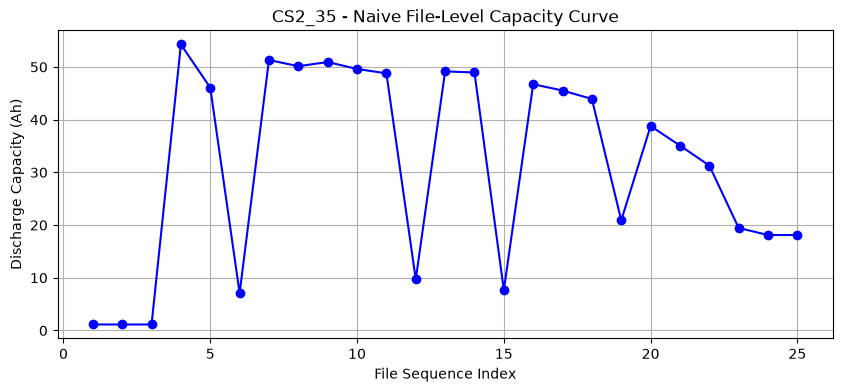

,Global_Cycle,File_Name,Discharge_Capacity(Ah)
0,1,CS2_35_8_17_10.xlsx,1.138460
1,2,CS2_35_8_18_10.xlsx,1.137728
2,3,CS2_35_8_19_10.xlsx,1.137481
3,4,CS2_35_8_30_10.xlsx,54.264202
4,5,CS2_35_9_7_10.xlsx,46.078954


In [4]:
cell_name = 'CS2_35'
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
processed_dir = os.path.join(project_path, 'data', 'processed')
extract_dir = os.path.join(project_path, 'data', 'calce_data')
save_path = os.path.join(processed_dir, f'{cell_name}_capacity.csv')
FORCE_REPROCESS = globals().get('FORCE_REPROCESS', False)

if os.path.exists(save_path) and not FORCE_REPROCESS:
    df_capacity = pd.read_csv(save_path)
    print(f"Loaded {len(df_capacity)} file-level records from {os.path.relpath(save_path, project_path)}.")
else:
    excel_files = glob.glob(os.path.join(extract_dir, cell_name, '**', '*.xls*'), recursive=True)
    excel_files.sort(key=parse_calce_date)
    cycle_data = []
    global_cycle = 1
    for file_path in excel_files:
        try:
            xls = pd.ExcelFile(file_path)
            channel_sheets = [s for s in xls.sheet_names if 'Channel' in s]
            if not channel_sheets:
                continue
            df = pd.read_excel(file_path, sheet_name=channel_sheets[0], usecols=['Discharge_Capacity(Ah)'])
            max_capacity = df['Discharge_Capacity(Ah)'].max()
            if max_capacity > 0.5:
                cycle_data.append({
                    'Global_Cycle': global_cycle,
                    'File_Name': os.path.basename(file_path),
                    'Discharge_Capacity(Ah)': max_capacity,
                })
                global_cycle += 1
        except Exception as e:
            print(f"Skipping {os.path.basename(file_path)}: {e}")
    df_capacity = pd.DataFrame(cycle_data)
    df_capacity.to_csv(save_path, index=False)
    print(f"Extracted {len(df_capacity)} file-level capacity records.")

plt.figure(figsize=(10, 4))
plt.plot(df_capacity['Global_Cycle'], df_capacity['Discharge_Capacity(Ah)'], marker='o', linestyle='-', color='b')
plt.title(f'{cell_name} - Naive File-Level Capacity Curve')
plt.xlabel('File Sequence Index')
plt.ylabel('Discharge Capacity (Ah)')
plt.grid(True)
plt.show()
display(df_capacity.head())

This diagnostic cell demonstrates in memory why integrating current without grouping by `Cycle_Index` and without handling physical multi-cycle bounds retains only three single-cycle files (intentionally leaving saved `*_SOH.csv` files unmodified when `FORCE_REPROCESS=False`).

Ungrouped integration yielded only 3 records (Reference Capacity: 1.1385 Ah).


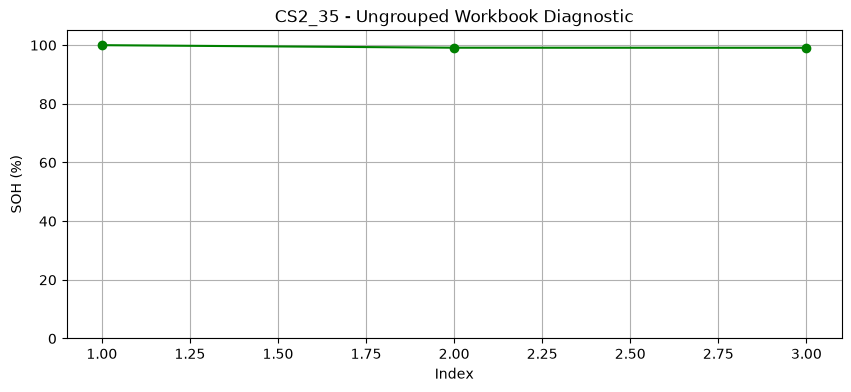

In [5]:
cell_name = 'CS2_35'
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
extract_dir = os.path.join(project_path, 'data', 'calce_data')
excel_files = glob.glob(os.path.join(extract_dir, cell_name, '**', '*.xls*'), recursive=True)
excel_files.sort(key=parse_calce_date)

if not excel_files:
    print("Raw Excel files not found locally; skipping ungrouped workbook integration diagnostic.")
else:
    cycle_data = []
    global_cycle = 1
    for file_path in excel_files:
        try:
            xls = pd.ExcelFile(file_path)
            channel_sheets = [s for s in xls.sheet_names if 'Channel' in s]
            if not channel_sheets:
                continue
            df = pd.read_excel(file_path, sheet_name=channel_sheets[0], usecols=['Test_Time(s)', 'Step_Index', 'Current(A)', 'Voltage(V)'])
            df_discharge = df[df['Current(A)'] < -0.5].copy()
            if len(df_discharge) > 50:
                df_discharge['dt_seconds'] = df_discharge['Test_Time(s)'].diff().fillna(0)
                true_capacity = (df_discharge['Current(A)'].abs() * df_discharge['dt_seconds']).sum() / 3600.0
                if 0.2 < true_capacity < 1.5:
                    cycle_data.append({
                        'Global_Cycle': global_cycle,
                        'File_Name': os.path.basename(file_path),
                        'Calculated_Capacity(Ah)': true_capacity,
                    })
                    global_cycle += 1
        except Exception:
            pass

    if cycle_data:
        df_naive_soh = pd.DataFrame(cycle_data)
        ref_cap = df_naive_soh['Calculated_Capacity(Ah)'].iloc[0]
        df_naive_soh['SOH(%)'] = (df_naive_soh['Calculated_Capacity(Ah)'] / ref_cap) * 100.0
        print(f"Ungrouped integration yielded only {len(df_naive_soh)} records (Reference Capacity: {ref_cap:.4f} Ah).")
        plt.figure(figsize=(10, 4))
        plt.plot(df_naive_soh['Global_Cycle'], df_naive_soh['SOH(%)'], marker='o', linestyle='-', color='g')
        plt.title(f'{cell_name} - Ungrouped Workbook Diagnostic')
        plt.xlabel('Index')
        plt.ylabel('SOH (%)')
        plt.ylim(0, 105)
        plt.grid(True)
        plt.show()

This cell inspects a multi-megabyte Arbin workbook (`> 1 MB`) and counts continuous discharge segments via `Step_Index`, confirming that single Excel files pack up to 50 distinct aging cycles.

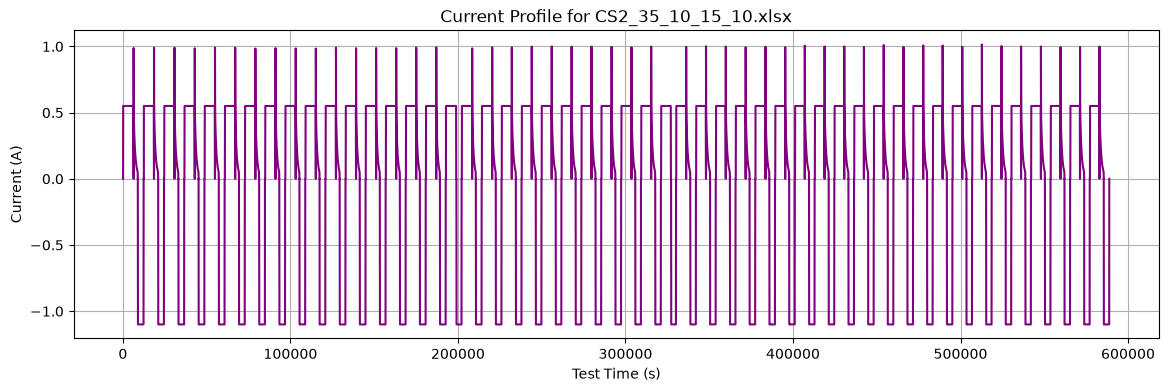

CS2_35_10_15_10.xlsx: discharge Step_Index=[7], detected cycles=50


In [6]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
extract_dir = os.path.join(project_path, 'data', 'calce_data')
excel_files = sorted(glob.glob(os.path.join(extract_dir, 'CS2_35', '**', '*.xls*'), recursive=True))
large_files = [f for f in excel_files if os.path.getsize(f) > 1_000_000]

if large_files:
    test_file = large_files[0]
    xls = pd.ExcelFile(test_file)
    sheet = [s for s in xls.sheet_names if 'Channel' in s][0]
    df = pd.read_excel(test_file, sheet_name=sheet, usecols=['Test_Time(s)', 'Step_Index', 'Current(A)'])

    plt.figure(figsize=(14, 4))
    plt.plot(df['Test_Time(s)'], df['Current(A)'], color='purple')
    plt.title(f"Current Profile for {os.path.basename(test_file)}")
    plt.xlabel("Test Time (s)")
    plt.ylabel("Current (A)")
    plt.grid(True)
    plt.show()

    discharge_steps = df.groupby('Step_Index')['Current(A)'].mean()
    actual_discharge_steps = discharge_steps[discharge_steps < -0.5].index.tolist()
    df['is_discharge'] = df['Step_Index'].isin(actual_discharge_steps)
    df['cycle_start'] = df['is_discharge'] & (~df['is_discharge'].shift(1, fill_value=False))
    print(f"{os.path.basename(test_file)}: discharge Step_Index={actual_discharge_steps}, detected cycles={int(df['cycle_start'].sum())}")
else:
    print("No raw workbook >1 MB available locally.")

This cell verifies that internal `Cycle_Index` values inside `CS2_35_8_30_10.xlsx` align cleanly with discharge transition boundaries (cycles 1 through 50).

In [7]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
extract_dir = os.path.join(project_path, 'data', 'calce_data')
candidate_files = glob.glob(os.path.join(extract_dir, 'CS2_35', '**', '*8_30_10.xls*'), recursive=True)

if candidate_files:
    test_file = candidate_files[0]
    xls = pd.ExcelFile(test_file)
    sheet = [s for s in xls.sheet_names if 'Channel' in s][0]
    df = pd.read_excel(test_file, sheet_name=sheet, usecols=['Data_Point', 'Test_Time(s)', 'Step_Time(s)', 'Step_Index', 'Cycle_Index', 'Current(A)'])
    unique_cycles = df['Cycle_Index'].dropna().unique()
    df['is_discharge'] = df['Current(A)'] < -0.5
    df['discharge_start'] = df['is_discharge'] & (~df['is_discharge'].shift(1, fill_value=False))
    discharge_starts = df[df['discharge_start']]
    print(f"File: {os.path.basename(test_file)} | Unique Cycle_Index count: {len(unique_cycles)} | Discharge starts: {len(discharge_starts)}")
    if len(discharge_starts) > 1:
        idx = discharge_starts.index[1]
        display(df.iloc[idx - 2 : idx + 3])
else:
    print("CS2_35_8_30_10.xlsx not found locally.")

File: CS2_35_8_30_10.xlsx | Unique Cycle_Index count: 50 | Discharge starts: 50


,Data_Point,Test_Time(s),Step_Time(s),Step_Index,Cycle_Index,Current(A),is_discharge,discharge_start
634,635,22142.112656,0.187475,6,2,0.000161,False,False
635,636,22146.940754,5.015573,6,2,0.000703,False,False
636,637,22176.956238,30.015126,7,2,-1.099568,True,True
637,638,22206.971563,60.030451,7,2,-1.099749,True,False
638,639,22236.986896,90.045784,7,2,-1.099749,True,False


This cell performs the full `Cycle_Index`-grouped Coulomb counting SOH extraction across all four cells when `FORCE_REPROCESS = True`, or verifies and plots the saved `*_SOH.csv` degradation trajectories when `FORCE_REPROCESS = False`.

Loading verified SOH CSV files (set FORCE_REPROCESS = True to rebuild from Excel logs)...
  CS2_35_SOH.csv: 3 rows | Mean initial 3-cycle cap=1.1318 Ah | Last SOH=99.11%


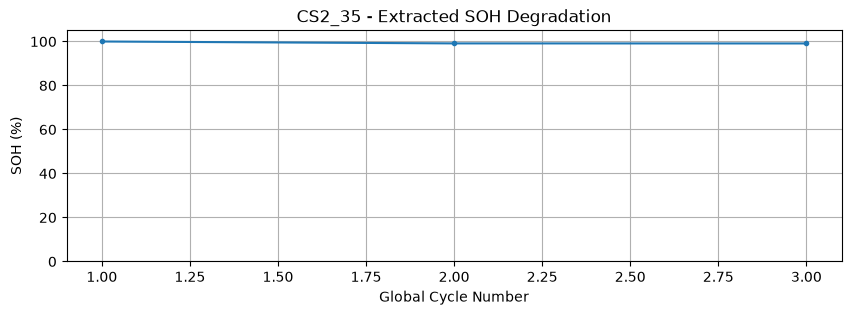

  CS2_36_SOH.csv: 927 rows | Mean initial 3-cycle cap=1.1377 Ah | Last SOH=17.68%


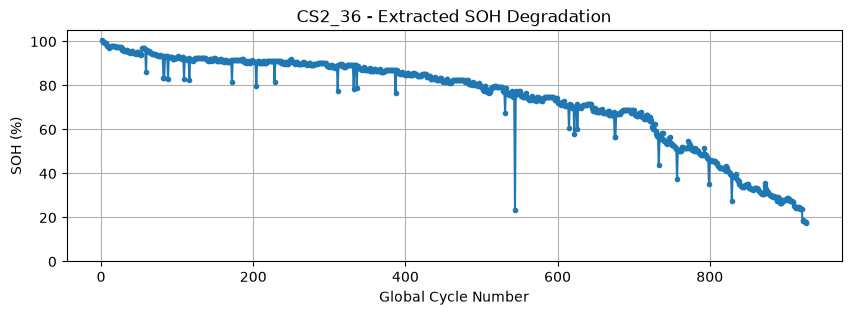

  CS2_37_SOH.csv: 1007 rows | Mean initial 3-cycle cap=1.1281 Ah | Last SOH=17.76%


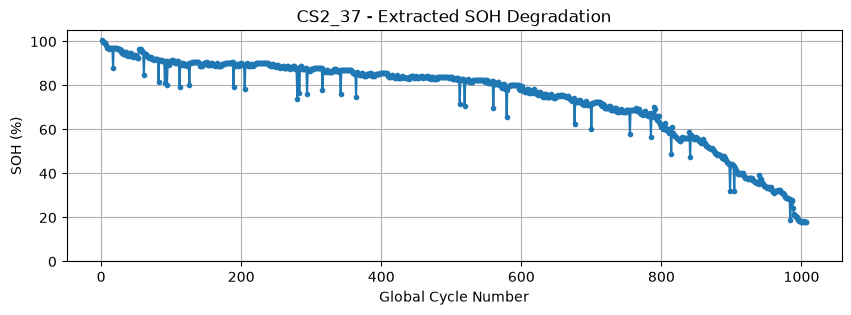

  CS2_38_SOH.csv: 1076 rows | Mean initial 3-cycle cap=1.1324 Ah | Last SOH=25.43%


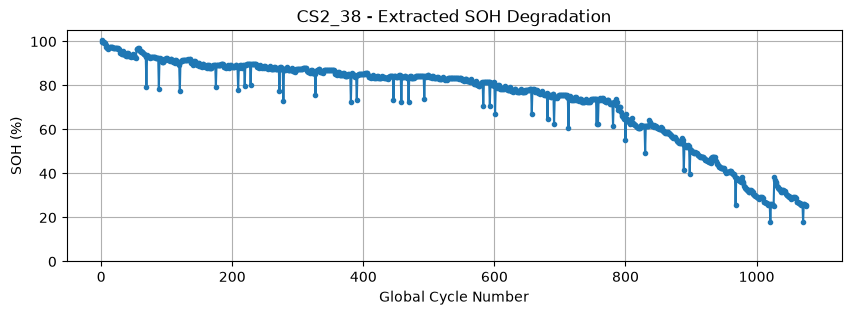

In [8]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
cells_list = ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']
extract_dir = os.path.join(project_path, 'data', 'calce_data')
processed_dir = os.path.join(project_path, 'data', 'processed')
os.makedirs(processed_dir, exist_ok=True)
FORCE_REPROCESS = globals().get('FORCE_REPROCESS', False)
all_soh_exist = all(os.path.exists(os.path.join(processed_dir, f'{c}_SOH.csv')) for c in cells_list)

if all_soh_exist and not FORCE_REPROCESS:
    print("Loading verified SOH CSV files (set FORCE_REPROCESS = True to rebuild from Excel logs)...")
    for cell_name in cells_list:
        df_soh = pd.read_csv(os.path.join(processed_dir, f'{cell_name}_SOH.csv'))
        cap_col = 'Capacity(Ah)' if 'Capacity(Ah)' in df_soh.columns else 'Calculated_Capacity(Ah)'
        ref_cap = df_soh[cap_col].head(3).mean()
        print(f"  {cell_name}_SOH.csv: {len(df_soh)} rows | Mean initial 3-cycle cap={ref_cap:.4f} Ah | Last SOH={df_soh['SOH(%)'].iloc[-1]:.2f}%")
        plt.figure(figsize=(10, 3))
        plt.plot(df_soh['Global_Cycle'], df_soh['SOH(%)'], marker='.', linestyle='-')
        plt.title(f'{cell_name} - Extracted SOH Degradation')
        plt.xlabel('Global Cycle Number')
        plt.ylabel('SOH (%)')
        plt.ylim(0, 105)
        plt.grid(True)
        plt.show()
else:
    for cell_name in cells_list:
        excel_files = glob.glob(os.path.join(extract_dir, cell_name, '**', '*.xls*'), recursive=True)
        excel_files.sort(key=parse_calce_date)
        if not excel_files:
            print(f"Warning: No Excel files found for {cell_name}.")
            continue

        cycle_data = []
        global_cycle = 1
        for file_path in excel_files:
            try:
                xls = pd.ExcelFile(file_path)
                channel_sheets = [s for s in xls.sheet_names if 'Channel' in s]
                if not channel_sheets:
                    continue
                df = pd.read_excel(file_path, sheet_name=channel_sheets[0], usecols=['Test_Time(s)', 'Step_Index', 'Cycle_Index', 'Current(A)', 'Voltage(V)'])
                for local_cycle, df_cycle in df.groupby('Cycle_Index'):
                    step_means = df_cycle.groupby('Step_Index')['Current(A)'].mean()
                    discharge_steps = step_means[step_means < -0.5].index.tolist()
                    for step in discharge_steps:
                        df_discharge = df_cycle[df_cycle['Step_Index'] == step].copy()
                        if len(df_discharge) > 20:
                            df_discharge = df_discharge.sort_values('Test_Time(s)')
                            dt = df_discharge['Test_Time(s)'].diff().fillna(0)
                            capacity = (df_discharge['Current(A)'].abs() * dt).sum() / 3600.0
                            if 0.2 < capacity < 1.5:
                                cycle_data.append({
                                    'Global_Cycle': global_cycle,
                                    'File_Name': os.path.basename(file_path),
                                    'Local_Cycle_Index': local_cycle,
                                    'Capacity(Ah)': capacity,
                                })
                                global_cycle += 1
            except Exception as e:
                print(f"  Error reading {os.path.basename(file_path)}: {e}")

        if cycle_data:
            df_final = pd.DataFrame(cycle_data)
            ref_cap = df_final['Capacity(Ah)'].head(3).mean()
            df_final['SOH(%)'] = (df_final['Capacity(Ah)'] / ref_cap) * 100.0
            df_final.to_csv(os.path.join(processed_dir, f'{cell_name}_SOH.csv'), index=False)
            print(f"Saved {len(df_final)} valid cycles for {cell_name} (Ref Capacity: {ref_cap:.4f} Ah)")
            plt.figure(figsize=(10, 3))
            plt.plot(df_final['Global_Cycle'], df_final['SOH(%)'], marker='.', linestyle='-')
            plt.title(f'{cell_name} - Extracted SOH Degradation')
            plt.xlabel('Global Cycle Number')
            plt.ylabel('SOH (%)')
            plt.ylim(0, 105)
            plt.grid(True)
            plt.show()

### Phases 3 & 4: Cycle-Level Feature Extraction & Data Quality Audits
We extract four physical health indicators per cycle from the Arbin logs (`Discharge_Time(s)`, `CC_Charge_Time(s)`, `Avg_Voltage(V)`, `Avg_Resistance(Ohm)` via positive `Internal_Resistance(Ohm)`) and compute reference-normalized `SOH(%)` across all cycles.

This first inspection cell checks all available column headers inside a raw Arbin `Channel` worksheet inside `CS2_35.zip`.

In [9]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
zip_path = os.path.join(project_path, 'data', 'raw_zips', 'CS2_35.zip')
target_filename = 'CS2_35_8_30_10.xlsx'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as z:
        for file_info in z.infolist():
            if target_filename in file_info.filename:
                with z.open(file_info) as f:
                    xls = pd.ExcelFile(f)
                    sheet = [s for s in xls.sheet_names if 'Channel' in s][0]
                    df_cols = pd.read_excel(f, sheet_name=sheet, nrows=5)
                    print(f"Columns in {target_filename} ({sheet}):")
                    for col in df_cols.columns:
                        print(f" - {col}")
                break
else:
    print("CS2_35.zip not present locally; skipping raw column inspection.")

Columns in CS2_35_8_30_10.xlsx (Channel_1-008):
 - Data_Point
 - Test_Time(s)
 - Date_Time
 - Step_Time(s)
 - Step_Index
 - Cycle_Index
 - Current(A)
 - Voltage(V)
 - Charge_Capacity(Ah)
 - Discharge_Capacity(Ah)
 - Charge_Energy(Wh)
 - Discharge_Energy(Wh)
 - dV/dt(V/s)
 - Internal_Resistance(Ohm)
 - Is_FC_Data
 - AC_Impedance(Ohm)
 - ACI_Phase_Angle(Deg)


This cell audits Cycle 2 of `CS2_35_8_30_10.xlsx` to inspect individual `Step_Index` charge/discharge currents, check time-step monotonicity, verify `Internal_Resistance(Ohm)` zero counts, and plot the Constant-Current Constant-Voltage (CC-CV) charge profile.

Step Index Summary (Cycle 2):
            Mean_Current  Duration_Seconds
Step_Index                                
1               0.000000        120.016446
2               0.550134       6634.747396
3               0.000000        120.013988
4               0.517788       2247.576694
5               0.000000         60.017393
6               0.000432          5.015573
7              -1.099711       3703.606319
8               0.000000         60.017477
9               0.000342          5.015491

Time audit: 0 negative dt, 9 gaps > 60s.
Internal Resistance: 381 rows, 0 zeros.


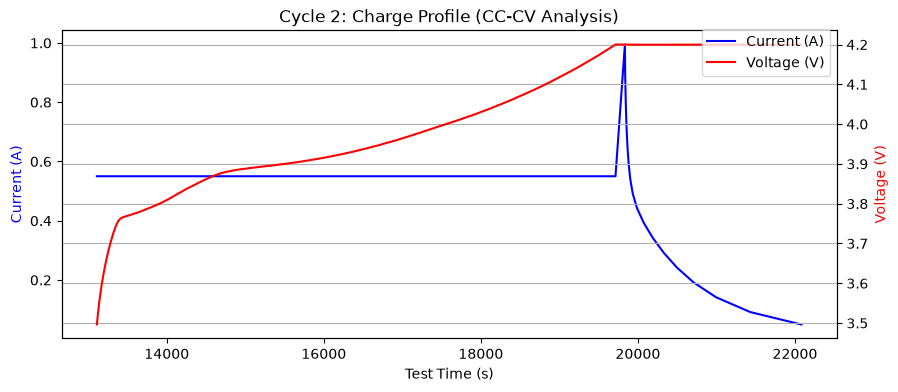

In [10]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
zip_path = os.path.join(project_path, 'data', 'raw_zips', 'CS2_35.zip')
target_filename = 'CS2_35_8_30_10.xlsx'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as z:
        for file_info in z.infolist():
            if target_filename in file_info.filename:
                with z.open(file_info) as f:
                    xls = pd.ExcelFile(f)
                    sheet = [s for s in xls.sheet_names if 'Channel' in s][0]
                    cols = ['Test_Time(s)', 'Step_Time(s)', 'Step_Index', 'Cycle_Index', 'Current(A)', 'Voltage(V)', 'Internal_Resistance(Ohm)']
                    df = pd.read_excel(f, sheet_name=sheet, usecols=cols)
                    df_c2 = df[df['Cycle_Index'] == 2].copy().sort_values('Test_Time(s)')

                    step_summary = df_c2.groupby('Step_Index').agg(
                        Mean_Current=('Current(A)', 'mean'),
                        Duration_Seconds=('Step_Time(s)', 'max'),
                    )
                    print("Step Index Summary (Cycle 2):")
                    print(step_summary)

                    dt = df_c2['Test_Time(s)'].diff().fillna(0)
                    print(f"\nTime audit: {(dt < 0).sum()} negative dt, {(dt > 60).sum()} gaps > 60s.")
                    res_col = df_c2['Internal_Resistance(Ohm)']
                    print(f"Internal Resistance: {res_col.count()} rows, {(res_col == 0).sum()} zeros.")

                    charge_steps = step_summary[step_summary['Mean_Current'] > 0.1].index.tolist()
                    if charge_steps:
                        df_charge = df_c2[df_c2['Step_Index'].isin(charge_steps)]
                        fig, ax1 = plt.subplots(figsize=(10, 4))
                        ax1.plot(df_charge['Test_Time(s)'], df_charge['Current(A)'], color='blue', label='Current (A)')
                        ax1.set_xlabel('Test Time (s)')
                        ax1.set_ylabel('Current (A)', color='blue')
                        ax2 = ax1.twinx()
                        ax2.plot(df_charge['Test_Time(s)'], df_charge['Voltage(V)'], color='red', label='Voltage (V)')
                        ax2.set_ylabel('Voltage (V)', color='red')
                        plt.title('Cycle 2: Charge Profile (CC-CV Analysis)')
                        fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.9))
                        plt.grid(True)
                        plt.show()
                break
else:
    print("CS2_35.zip not present locally; skipping Cycle 2 profile audit.")

This cell loads and summarizes the processed feature CSVs (`CS2_35_features.csv` to `CS2_38_features.csv`) when `FORCE_REPROCESS = False`, or runs the exact Arbin feature-extraction pipeline with time-gap audits and positive `Internal_Resistance(Ohm)` filtering when `FORCE_REPROCESS = True`.

In [11]:
def parse_calce_timestamp(filename):
    base = os.path.basename(filename).replace('.xlsx', '').replace('.xls', '')
    parts = base.split('_')
    if len(parts) >= 5:
        try:
            m, d, y = int(parts[-3]), int(parts[-2]), int(parts[-1])
            y = y + 2000 if y < 100 else y
            return pd.Timestamp(year=y, month=m, day=d)
        except ValueError:
            pass
    return pd.Timestamp.max


project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
cells_list = ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']
extract_dir = os.path.join(project_path, 'data', 'calce_data')
processed_dir = os.path.join(project_path, 'data', 'processed')
os.makedirs(processed_dir, exist_ok=True)
FORCE_REPROCESS = globals().get('FORCE_REPROCESS', False)
all_feat_exist = all(os.path.exists(os.path.join(processed_dir, f'{c}_features.csv')) for c in cells_list)

if all_feat_exist and not FORCE_REPROCESS:
    print("Loading verified processed feature CSVs (set FORCE_REPROCESS = True to rebuild)...")
    total_cycles = 0
    for cell_name in cells_list:
        df_feat = pd.read_csv(os.path.join(processed_dir, f'{cell_name}_features.csv'))
        total_cycles += len(df_feat)
        print(f"  {cell_name}_features.csv: {len(df_feat)} cycles | SOH range [{df_feat['SOH(%)'].min():.2f}%, {df_feat['SOH(%)'].max():.2f}%]")
    print(f"Total verified cycles across 4 cells: {total_cycles}")
else:
    print("Running Phase 4 Feature Extraction with Time & Resistance Audits...")
    cols = ['Test_Time(s)', 'Step_Time(s)', 'Step_Index', 'Cycle_Index', 'Current(A)', 'Voltage(V)', 'Internal_Resistance(Ohm)']
    for cell_name in cells_list:
        excel_files = glob.glob(os.path.join(extract_dir, cell_name, '**', '*.xls*'), recursive=True)
        excel_files.sort(key=parse_calce_timestamp)
        feature_data = []
        global_cycle = 1

        for file_path in excel_files:
            file_name = os.path.basename(file_path)
            try:
                xls = pd.ExcelFile(file_path)
                channel_sheets = [s for s in xls.sheet_names if 'Channel' in s]
                if not channel_sheets:
                    continue
                df = pd.read_excel(file_path, sheet_name=channel_sheets[0], usecols=cols)
                file_dups, file_max_dt, file_large_gaps, valid_cycles = 0, 0.0, 0, 0

                for local_cycle, df_cycle in df.groupby('Cycle_Index'):
                    step_means = df_cycle.groupby('Step_Index')['Current(A)'].mean()
                    discharge_steps = step_means[step_means < -0.5].index.tolist()
                    cc_charge_steps = step_means[(step_means > 0.4) & (step_means < 0.7)].index.tolist()

                    if discharge_steps:
                        step_durations = df_cycle.groupby('Step_Index')['Step_Time(s)'].max()
                        main_discharge_step = max(discharge_steps, key=lambda s: step_durations.get(s, 0))
                        if step_durations.get(main_discharge_step, 0) > 1000:
                            df_discharge = df_cycle[df_cycle['Step_Index'] == main_discharge_step].sort_values('Test_Time(s)').copy()
                            file_dups += int(df_discharge['Test_Time(s)'].duplicated().sum())
                            dt = df_discharge['Test_Time(s)'].diff().fillna(0)
                            file_large_gaps += int((dt > 60).sum())
                            dt_clipped = dt.clip(lower=0)
                            file_max_dt = max(file_max_dt, float(dt_clipped.max()))
                            capacity = float((df_discharge['Current(A)'].abs() * dt_clipped).sum() / 3600.0)

                            discharge_time = float(df_discharge['Test_Time(s)'].max() - df_discharge['Test_Time(s)'].min())
                            avg_voltage = float(df_discharge['Voltage(V)'].mean())

                            avg_resistance = np.nan
                            if 'Internal_Resistance(Ohm)' in df_discharge.columns:
                                res_vals = df_discharge['Internal_Resistance(Ohm)']
                                if (res_vals > 0).any():
                                    avg_resistance = float(res_vals[res_vals > 0].mean())

                            cc_charge_time = np.nan
                            if cc_charge_steps:
                                main_cc_step = max(cc_charge_steps, key=lambda s: step_durations.get(s, 0))
                                df_cc = df_cycle[df_cycle['Step_Index'] == main_cc_step]
                                cc_charge_time = float(df_cc['Test_Time(s)'].max() - df_cc['Test_Time(s)'].min())

                            if 0.2 < capacity < 1.5:
                                feature_data.append({
                                    'File_Name': file_name,
                                    'Local_Cycle_Index': local_cycle,
                                    'Global_Cycle': global_cycle,
                                    'Discharge_Time(s)': discharge_time,
                                    'CC_Charge_Time(s)': cc_charge_time,
                                    'Avg_Voltage(V)': avg_voltage,
                                    'Avg_Resistance(Ohm)': avg_resistance,
                                    'Capacity(Ah)': capacity,
                                })
                                global_cycle += 1
                                valid_cycles += 1
                if valid_cycles > 0:
                    print(f"  [{file_name}] Cycles: {valid_cycles:3d} | Dups: {file_dups} | Max dt: {file_max_dt:4.1f}s | Gaps >60s: {file_large_gaps}")
            except Exception as e:
                print(f"  [ERROR] {file_name}: {e}")

        if feature_data:
            df_features = pd.DataFrame(feature_data)
            reference_capacity = df_features['Capacity(Ah)'].head(3).mean()
            df_features['SOH(%)'] = (df_features['Capacity(Ah)'] / reference_capacity) * 100.0
            save_path = os.path.join(processed_dir, f'{cell_name}_features.csv')
            df_features.to_csv(save_path, index=False)
            print(f"-> Saved {len(df_features)} cycles for {cell_name}.")

Loading verified processed feature CSVs (set FORCE_REPROCESS = True to rebuild)...
  CS2_35_features.csv: 922 cycles | SOH range [27.07%, 100.59%]
  CS2_36_features.csv: 907 cycles | SOH range [26.75%, 100.62%]
  CS2_37_features.csv: 986 cycles | SOH range [27.58%, 100.61%]
  CS2_38_features.csv: 1049 cycles | SOH range [26.92%, 100.63%]
Total verified cycles across 4 cells: 3864


This data-quality audit checks all four processed feature CSVs for missing/infinite values, physical feature min/median/max ranges, tail SOH values, and strict `Global_Cycle` monotonicity.

In [12]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
processed_dir = os.path.join(project_path, 'data', 'processed')
audit_cols = ['Discharge_Time(s)', 'CC_Charge_Time(s)', 'Avg_Voltage(V)', 'Avg_Resistance(Ohm)', 'Capacity(Ah)', 'SOH(%)']

for cell in ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']:
    df = pd.read_csv(os.path.join(processed_dir, f'{cell}_features.csv'))
    nans = int(df[audit_cols].isna().sum().sum())
    infs = int(np.isinf(df[audit_cols].select_dtypes(include=[np.number])).sum().sum())
    print(f"\n========== {cell} (n={len(df)}, NaNs={nans}, Infs={infs}, Monotonic={df['Global_Cycle'].is_monotonic_increasing}) ==========")
    print(df[audit_cols].agg(['min', 'median', 'max']).round(4))


========== CS2_35 (n=922, NaNs=0, Infs=0, Monotonic=True) ==========
        Discharge_Time(s)  CC_Charge_Time(s)  Avg_Voltage(V)  \
min             1003.0765             0.0000          3.3290   
median          3083.5781          5312.2992          3.6188   
max             3726.8046          6735.3236          3.6906   

        Avg_Resistance(Ohm)  Capacity(Ah)    SOH(%)  
min                  0.0850        0.3064   27.0699  
median               0.0964        0.9419   83.2222  
max                  0.1232        1.1385  100.5898  

========== CS2_36 (n=907, NaNs=0, Infs=0, Monotonic=True) ==========
        Discharge_Time(s)  CC_Charge_Time(s)  Avg_Voltage(V)  \
min              996.2953          1718.0728          3.3321   
median          3069.5703          5335.3915          3.6242   
max             3746.5543          6763.8699          3.6736   

        Avg_Resistance(Ohm)  Capacity(Ah)    SOH(%)  
min                  0.0820        0.3044   26.7535  
median               0

This cell explicitly audits zero or non-positive `CC_Charge_Time(s)` entries (`<= 0`) across the four datasets so they can be masked as missing values before train-only median imputation.

In [13]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
processed_dir = os.path.join(project_path, 'data', 'processed')

for cell in ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']:
    df = pd.read_csv(os.path.join(processed_dir, f'{cell}_features.csv'))
    zero_rows = df[df['CC_Charge_Time(s)'] <= 0]
    print(f"{cell}: total={len(df)} | non-positive CC_Charge_Time(s)={len(zero_rows)}")
    if len(zero_rows) > 0:
        print(zero_rows[['File_Name', 'Local_Cycle_Index', 'Global_Cycle', 'CC_Charge_Time(s)', 'Capacity(Ah)']].to_string(index=False))

CS2_35: total=922 | non-positive CC_Charge_Time(s)=3
          File_Name  Local_Cycle_Index  Global_Cycle  CC_Charge_Time(s)  Capacity(Ah)
CS2_35_1_10_11.xlsx                  1           647                0.0      0.874875
 CS2_35_2_4_11.xlsx                  1           833                0.0      0.497129
CS2_35_2_10_11.xlsx                  1           878                0.0      0.497129
CS2_36: total=907 | non-positive CC_Charge_Time(s)=0
CS2_37: total=986 | non-positive CC_Charge_Time(s)=2
           File_Name  Local_Cycle_Index  Global_Cycle  CC_Charge_Time(s)  Capacity(Ah)
CS2_37_10_05_10.xlsx                  1           272                0.0      0.998954
CS2_37_12_06_10.xlsx                  1           613                0.0      0.879336
CS2_38: total=1049 | non-positive CC_Charge_Time(s)=3
           File_Name  Local_Cycle_Index  Global_Cycle  CC_Charge_Time(s)  Capacity(Ah)
 CS2_38_9_14_10.xlsx                  1            96                0.0      1.041453
CS2_38_1

### Phase 5: Leak-Free Preprocessing & Leave-One-Cell-Out (LOCO) Pipeline
To prevent temporal and cell-identity data leakage across cycles from the same battery, we evaluate all models strictly via 4-fold Leave-One-Cell-Out cross-validation.

This cell implements `BatteryDataPipeline`, converting `CC_Charge_Time(s) <= 0` to `NaN`, fitting `SimpleImputer(strategy='median')` and `StandardScaler()` strictly on each fold's 3 training cells, and caching the verified arrays in `loco_results`.

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


class BatteryDataPipeline:
    def __init__(self, data_dir):
        self.data_dir = data_dir
        self.cells = ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']
        self.features = ['Discharge_Time(s)', 'CC_Charge_Time(s)', 'Avg_Voltage(V)', 'Avg_Resistance(Ohm)']
        self.target = 'SOH(%)'
        self.datasets = {}
        self._load_data()

    def _load_data(self):
        required = self.features + [self.target, 'Global_Cycle']
        for cell in self.cells:
            file_path = os.path.join(self.data_dir, f'{cell}_features.csv')
            if not os.path.exists(file_path):
                raise FileNotFoundError(f"Processed dataset not found: {file_path}")
            df = pd.read_csv(file_path)
            missing = [col for col in required if col not in df.columns]
            if missing:
                raise ValueError(f"{cell} missing columns: {missing}")
            df = df.sort_values('Global_Cycle').reset_index(drop=True)
            df.loc[df['CC_Charge_Time(s)'] <= 0, 'CC_Charge_Time(s)'] = np.nan
            self.datasets[cell] = df
            print(f"Loaded {cell}: {len(df)} cycles | Masked CC_Charge_Time NaNs: {int(df['CC_Charge_Time(s)'].isna().sum())}")

    def get_loco_fold(self, test_cell):
        if test_cell not in self.cells:
            raise ValueError(f"Unknown test cell: {test_cell}")
        train_cells = [c for c in self.cells if c != test_cell]
        df_train = pd.concat([self.datasets[c] for c in train_cells], ignore_index=True)
        df_test = self.datasets[test_cell].copy()

        X_train_raw = df_train[self.features].replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)
        X_test_raw = df_test[self.features].replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)
        y_train = df_train[self.target].to_numpy(dtype=float)
        y_test = df_test[self.target].to_numpy(dtype=float)

        assert np.isfinite(y_train).all() and np.isfinite(y_test).all()
        imputer = SimpleImputer(strategy='median')
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(imputer.fit_transform(X_train_raw))
        X_test_scaled = scaler.transform(imputer.transform(X_test_raw))

        assert np.isfinite(X_train_scaled).all() and np.isfinite(X_test_scaled).all()
        return X_train_scaled, y_train, X_test_scaled, y_test, scaler, imputer

    def run_all_folds(self):
        results = {}
        print("\n========== LOCO FOLD INTEGRITY CHECK ==========")
        for test_cell in self.cells:
            train_cells = [c for c in self.cells if c != test_cell]
            X_tr, y_tr, X_te, y_te, sc, imp = self.get_loco_fold(test_cell)
            results[test_cell] = {
                'train_cells': train_cells,
                'X_train': X_tr,
                'y_train': y_tr,
                'X_test': X_te,
                'y_test': y_te,
                'scaler': sc,
                'imputer': imp,
            }
            print(f"Fold {test_cell}: X_train={X_tr.shape}, X_test={X_te.shape} | NaNs=0")
        return results


project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
pipeline_p5 = BatteryDataPipeline(os.path.join(project_path, 'data', 'processed'))
loco_results = pipeline_p5.run_all_folds()

Loaded CS2_35: 922 cycles | Masked CC_Charge_Time NaNs: 3
Loaded CS2_36: 907 cycles | Masked CC_Charge_Time NaNs: 0
Loaded CS2_37: 986 cycles | Masked CC_Charge_Time NaNs: 2
Loaded CS2_38: 1049 cycles | Masked CC_Charge_Time NaNs: 3

========== LOCO FOLD INTEGRITY CHECK ==========
Fold CS2_35: X_train=(2942, 4), X_test=(922, 4) | NaNs=0
Fold CS2_36: X_train=(2957, 4), X_test=(907, 4) | NaNs=0
Fold CS2_37: X_train=(2878, 4), X_test=(986, 4) | NaNs=0
Fold CS2_38: X_train=(2815, 4), X_test=(1049, 4) | NaNs=0


### Phase 6A: Traditional Machine Learning Baselines
We evaluate three classical tabular regressors under the 4-cell LOCO protocol: `RandomForestRegressor(n_estimators=100)` across seeds `[42, 100, 2026]`, `XGBRegressor(n_estimators=100, learning_rate=0.1)` across seeds `[42, 100, 2026]`, and deterministic `SVR(kernel='rbf', C=1.0, epsilon=0.1)` (one run per fold).

This cell loads the verified Phase 6A CSV metrics by default (`FORCE_RETRAIN = False`), or retrains and aggregates all 28 baseline evaluations from scratch when `FORCE_RETRAIN = True`.

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
results_dir = os.path.join(project_path, 'results')
raw_csv_path = os.path.join(results_dir, 'phase6a_detailed_results.csv')
summary_csv_path = os.path.join(results_dir, 'phase6a_summary_results.csv')
FORCE_RETRAIN = globals().get('FORCE_RETRAIN', False)

if not FORCE_RETRAIN and os.path.exists(summary_csv_path) and os.path.exists(raw_csv_path):
    df_raw_6a = pd.read_csv(raw_csv_path)
    formatted_summary_6a = pd.read_csv(summary_csv_path)
    print("Loaded verified Phase 6A results (set FORCE_RETRAIN = True to retrain).")
    display(formatted_summary_6a)
else:
    try:
        import xgboost as xgb
    except ImportError as err:
        raise ImportError("Package 'xgboost' is required for Phase 6A retraining. Install via: pip install xgboost") from err

    evaluation_records = []
    random_seeds = [42, 100, 2026]
    for test_cell, fold_data in loco_results.items():
        X_tr, y_tr = fold_data['X_train'], fold_data['y_train']
        X_te, y_te = fold_data['X_test'], fold_data['y_test']
        for model_name in ['RandomForest', 'XGBoost', 'SVR']:
            seeds_to_run = [42] if model_name == 'SVR' else random_seeds
            for seed in seeds_to_run:
                if model_name == 'RandomForest':
                    model = RandomForestRegressor(n_estimators=100, random_state=seed, n_jobs=-1)
                elif model_name == 'XGBoost':
                    model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=seed, n_jobs=-1, objective='reg:squarederror')
                else:
                    model = SVR(kernel='rbf', C=1.0, epsilon=0.1)
                model.fit(X_tr, y_tr)
                y_pred = model.predict(X_te)
                mse = mean_squared_error(y_te, y_pred)
                evaluation_records.append({
                    'Test_Cell': test_cell,
                    'Model': model_name,
                    'Seed': 'Deterministic' if model_name == 'SVR' else seed,
                    'MAE': mean_absolute_error(y_te, y_pred),
                    'MSE': mse,
                    'RMSE': np.sqrt(mse),
                    'R2': r2_score(y_te, y_pred),
                    'MAPE(%)': mean_absolute_percentage_error(y_te, y_pred) * 100.0,
                })

    df_raw_6a = pd.DataFrame(evaluation_records)
    df_fold_means = df_raw_6a.groupby(['Test_Cell', 'Model'])[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].mean().reset_index()
    summary_stats = df_fold_means.groupby('Model')[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].agg(['mean', 'std']).round(4)
    formatted_summary_6a = pd.DataFrame(index=summary_stats.index)
    for m in ['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']:
        formatted_summary_6a[m] = summary_stats[m]['mean'].astype(str) + " ± " + summary_stats[m]['std'].astype(str)
    df_raw_6a.to_csv(raw_csv_path, index=False)
    formatted_summary_6a.reset_index().to_csv(summary_csv_path, index=False)
    display(formatted_summary_6a.reset_index())

Loaded verified Phase 6A results (set FORCE_RETRAIN = True to retrain).


,Model,MAE,MSE,RMSE,R2,MAPE(%)
0,RandomForest,0.2969 ± 0.1967,0.136 ± 0.1284,0.3295 ± 0.191,0.9996 ± 0.0004,0.3936 ± 0.2566
1,SVR,1.211 ± 1.2807,18.17 ± 34.0669,2.8698 ± 3.6395,0.9456 ± 0.1022,1.6563 ± 1.3598
2,XGBoost,0.3582 ± 0.1962,0.1885 ± 0.1516,0.4047 ± 0.1817,0.9994 ± 0.0004,0.5081 ± 0.2608


### Phase 6B: Gaussian Process Regression Baselines (Exact & Sparse SVGP)
Exact GPR models provide analytical predictive distributions but incur $\mathcal{O}(N^3)$ training cost ($100.55\text{ s}$ observed for single-fold $N = 2942$ RBF fit). We evaluate three deterministic Exact GPR formulations (`GPR-RBF`, `GPR-Matern` with $\nu = 1.5$, and anisotropic `GPR-ARD` with `alpha=1e-6`, `normalize_y=True`, `n_restarts_optimizer=0`) alongside Sparse Variational GPR (`SparseGPR-Matern`, $M = 100$ inducing points, `lr=0.05`, 100 epochs).

This cell loads the verified Exact GPR metrics by default or runs the deterministic L-BFGS Exact GPR benchmark across all 4 LOCO folds when `FORCE_RETRAIN = True`.

In [16]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel as C

project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
results_dir = os.path.join(project_path, 'results')
raw_csv_path = os.path.join(results_dir, 'phase6b_exact_gp_detailed.csv')
summary_csv_path = os.path.join(results_dir, 'phase6b_exact_gp_summary.csv')
FORCE_RETRAIN = globals().get('FORCE_RETRAIN', False)

if not FORCE_RETRAIN and os.path.exists(summary_csv_path) and os.path.exists(raw_csv_path):
    df_raw_6b_ex = pd.read_csv(raw_csv_path)
    formatted_summary_6b_ex = pd.read_csv(summary_csv_path)
    print("Loaded verified Phase 6B Exact GPR results (observed O(N^3) single-fold RBF fit on N=2942: 100.55s).")
    display(formatted_summary_6b_ex)
else:
    kernels_to_test = {
        'GPR-RBF': C(1.0, (1e-2, 1e2)) * RBF(length_scale=1.0, length_scale_bounds=(1e-2, 1e2)),
        'GPR-Matern': C(1.0, (1e-2, 1e2)) * Matern(length_scale=1.0, length_scale_bounds=(1e-2, 1e2), nu=1.5),
        'GPR-ARD': C(1.0, (1e-2, 1e2)) * RBF(length_scale=[1.0, 1.0, 1.0, 1.0], length_scale_bounds=(1e-2, 1e2)),
    }
    evaluation_records = []
    for test_cell, fold_data in loco_results.items():
        X_tr, y_tr = fold_data['X_train'], fold_data['y_train']
        X_te, y_te = fold_data['X_test'], fold_data['y_test']
        for model_name, kernel in kernels_to_test.items():
            t0 = time.time()
            gpr = GaussianProcessRegressor(
                kernel=kernel, alpha=1e-6, n_restarts_optimizer=0, normalize_y=True, random_state=42
            )
            gpr.fit(X_tr, y_tr)
            y_pred = gpr.predict(X_te)
            mse = mean_squared_error(y_te, y_pred)
            rmse = np.sqrt(mse)
            print(f"Fold {test_cell} | {model_name:10s} | {time.time() - t0:5.1f}s | RMSE: {rmse:.4f}")
            evaluation_records.append({
                'Test_Cell': test_cell,
                'Model': model_name,
                'Seed': 'Deterministic',
                'MAE': mean_absolute_error(y_te, y_pred),
                'MSE': mse,
                'RMSE': rmse,
                'R2': r2_score(y_te, y_pred),
                'MAPE(%)': mean_absolute_percentage_error(y_te, y_pred) * 100.0,
            })

    df_raw_6b_ex = pd.DataFrame(evaluation_records)
    df_fold_means = df_raw_6b_ex.groupby(['Test_Cell', 'Model'])[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].mean().reset_index()
    summary_stats = df_fold_means.groupby('Model')[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].agg(['mean', 'std']).round(4)
    formatted_summary_6b_ex = pd.DataFrame(index=summary_stats.index)
    for m in ['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']:
        formatted_summary_6b_ex[m] = summary_stats[m]['mean'].astype(str) + " ± " + summary_stats[m]['std'].astype(str)
    df_raw_6b_ex.to_csv(raw_csv_path, index=False)
    formatted_summary_6b_ex.reset_index().to_csv(summary_csv_path, index=False)
    display(formatted_summary_6b_ex.reset_index())

Loaded verified Phase 6B Exact GPR results (observed O(N^3) single-fold RBF fit on N=2942: 100.55s).


,Model,MAE,MSE,RMSE,R2,MAPE(%)
0,GPR-ARD,2.7415 ± 1.8069,44.7828 ± 48.7234,5.9696 ± 3.4921,0.8684 ± 0.147,5.2316 ± 3.5887
1,GPR-Matern,0.7759 ± 0.7418,7.1333 ± 13.0168,1.853 ± 2.221,0.9787 ± 0.039,0.9608 ± 0.7843
2,GPR-RBF,3.5669 ± 2.2967,65.508 ± 60.1479,7.3401 ± 3.9381,0.8087 ± 0.1815,7.6323 ± 4.7524


This cell evaluates Sparse Variational GPR (`SparseGPR-Matern`, $\nu = 1.5$, $M = 100$ learned inducing points, `lr = 0.05`, 100 epochs) via GPyTorch or loads its verified saved CSV results when `FORCE_RETRAIN = False`.

In [17]:
import gpytorch

project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
results_dir = os.path.join(project_path, 'results')
raw_csv_path = os.path.join(results_dir, 'phase6b_sparse_gp_detailed.csv')
summary_csv_path = os.path.join(results_dir, 'phase6b_sparse_gp_summary.csv')
FORCE_RETRAIN = globals().get('FORCE_RETRAIN', False)
device = globals().get('device', torch.device('cuda' if torch.cuda.is_available() else 'cpu'))

if not FORCE_RETRAIN and os.path.exists(summary_csv_path) and os.path.exists(raw_csv_path):
    df_raw_6b_sp = pd.read_csv(raw_csv_path)
    formatted_summary_6b_sp = pd.read_csv(summary_csv_path)
    print("Loaded verified Phase 6B Sparse GPR results.")
    display(formatted_summary_6b_sp)
else:
    class SparseGPRModel(gpytorch.models.ApproximateGP):
        def __init__(self, inducing_points):
            variational_distribution = gpytorch.variational.CholeskyVariationalDistribution(inducing_points.size(0))
            variational_strategy = gpytorch.variational.VariationalStrategy(
                self, inducing_points, variational_distribution, learn_inducing_locations=True
            )
            super().__init__(variational_strategy)
            self.mean_module = gpytorch.means.ConstantMean()
            self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.MaternKernel(nu=1.5))

        def forward(self, x):
            return gpytorch.distributions.MultivariateNormal(self.mean_module(x), self.covar_module(x))

    evaluation_records = []
    for test_cell, fold_data in loco_results.items():
        X_tr, y_tr = fold_data['X_train'], fold_data['y_train']
        X_te, y_te = fold_data['X_test'], fold_data['y_test']
        y_mean, y_std = float(y_tr.mean()), float(y_tr.std())
        train_x = torch.tensor(X_tr, dtype=torch.float32).to(device)
        train_y = torch.tensor((y_tr - y_mean) / y_std, dtype=torch.float32).to(device)
        test_x = torch.tensor(X_te, dtype=torch.float32).to(device)

        for seed in [42, 100, 2026]:
            torch.manual_seed(seed)
            if device.type == 'cuda':
                torch.cuda.manual_seed_all(seed)
            inducing_indices = torch.randperm(train_x.size(0), device=device)[:100]
            model = SparseGPRModel(train_x[inducing_indices].clone()).to(device)
            likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device)
            model.train()
            likelihood.train()
            optimizer = torch.optim.Adam([{'params': model.parameters()}, {'params': likelihood.parameters()}], lr=0.05)
            mll = gpytorch.mlls.VariationalELBO(likelihood, model, num_data=train_y.size(0))

            for _ in range(100):
                optimizer.zero_grad()
                loss = -mll(model(train_x), train_y)
                loss.backward()
                optimizer.step()

            model.eval()
            likelihood.eval()
            with torch.no_grad(), gpytorch.settings.fast_pred_var():
                preds_scaled = likelihood(model(test_x)).mean.cpu().numpy()
                y_pred = (preds_scaled * y_std) + y_mean

            mse = mean_squared_error(y_te, y_pred)
            evaluation_records.append({
                'Test_Cell': test_cell,
                'Model': 'SparseGPR-Matern',
                'Seed': seed,
                'MAE': mean_absolute_error(y_te, y_pred),
                'MSE': mse,
                'RMSE': np.sqrt(mse),
                'R2': r2_score(y_te, y_pred),
                'MAPE(%)': mean_absolute_percentage_error(y_te, y_pred) * 100.0,
            })

    df_raw_6b_sp = pd.DataFrame(evaluation_records)
    df_fold_means = df_raw_6b_sp.groupby(['Test_Cell', 'Model'])[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].mean().reset_index()
    summary_stats = df_fold_means.groupby('Model')[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].agg(['mean', 'std']).round(4)
    formatted_summary_6b_sp = pd.DataFrame(index=summary_stats.index)
    for m in ['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']:
        formatted_summary_6b_sp[m] = summary_stats[m]['mean'].astype(str) + " ± " + summary_stats[m]['std'].astype(str)
    df_raw_6b_sp.to_csv(raw_csv_path, index=False)
    formatted_summary_6b_sp.reset_index().to_csv(summary_csv_path, index=False)
    display(formatted_summary_6b_sp.reset_index())

Loaded verified Phase 6B Sparse GPR results.


,Model,MAE,MSE,RMSE,R2,MAPE(%)
0,SparseGPR-Matern,1.1313 ± 1.2942,18.2805 ± 35.6138,2.5924 ± 3.9185,0.9452 ± 0.1067,1.4239 ± 1.3923


### Phase 6C: Deep-Kernel Variational Gaussian Process Regression
Deep-Kernel Learning projects the 4 standardized inputs through a multi-layer perceptron (`4 -> 32 -> 16 -> 4`, ReLU activations) before applying a sparse variational Matérn-1.5 kernel ($M = 100$ learned inducing points, Variational ELBO, 150 epochs, `lr = 0.01`).

This cell loads the verified Phase 6C DeepKernel-GPR results by default or retrains the variational deep-kernel GP across all 4 LOCO folds and 3 seeds when `FORCE_RETRAIN = True`.

In [18]:
import torch.nn as nn

project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
results_dir = os.path.join(project_path, 'results')
raw_csv_path = os.path.join(results_dir, 'phase6c_deep_kernel_gp_detailed.csv')
summary_csv_path = os.path.join(results_dir, 'phase6c_deep_kernel_gp_summary.csv')
FORCE_RETRAIN = globals().get('FORCE_RETRAIN', False)
device = globals().get('device', torch.device('cuda' if torch.cuda.is_available() else 'cpu'))

if not FORCE_RETRAIN and os.path.exists(summary_csv_path) and os.path.exists(raw_csv_path):
    df_raw_6c = pd.read_csv(raw_csv_path)
    formatted_summary_6c = pd.read_csv(summary_csv_path)
    print("Loaded verified Phase 6C DeepKernel-GPR results.")
    display(formatted_summary_6c)
else:
    class FeatureExtractor(nn.Module):
        def __init__(self, input_dim=4, latent_dim=4):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(input_dim, 32), nn.ReLU(),
                nn.Linear(32, 16), nn.ReLU(),
                nn.Linear(16, latent_dim),
            )

        def forward(self, x):
            return self.net(x)

    class DeepKernelModel(gpytorch.models.ApproximateGP):
        def __init__(self, inducing_points, feature_extractor):
            variational_distribution = gpytorch.variational.CholeskyVariationalDistribution(inducing_points.size(0))
            variational_strategy = gpytorch.variational.VariationalStrategy(
                self, inducing_points, variational_distribution, learn_inducing_locations=True
            )
            super().__init__(variational_strategy)
            self.feature_extractor = feature_extractor
            self.mean_module = gpytorch.means.ConstantMean()
            self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.MaternKernel(nu=1.5))

        def forward(self, x):
            projected_x = self.feature_extractor(x)
            return gpytorch.distributions.MultivariateNormal(self.mean_module(projected_x), self.covar_module(projected_x))

    evaluation_records = []
    for test_cell, fold_data in loco_results.items():
        X_tr, y_tr = fold_data['X_train'], fold_data['y_train']
        X_te, y_te = fold_data['X_test'], fold_data['y_test']
        y_mean, y_std = float(y_tr.mean()), float(y_tr.std())
        train_x = torch.tensor(X_tr, dtype=torch.float32).to(device)
        train_y = torch.tensor((y_tr - y_mean) / y_std, dtype=torch.float32).to(device)
        test_x = torch.tensor(X_te, dtype=torch.float32).to(device)

        for seed in [42, 100, 2026]:
            torch.manual_seed(seed)
            if device.type == 'cuda':
                torch.cuda.manual_seed_all(seed)
            extractor = FeatureExtractor(input_dim=4, latent_dim=4).to(device)
            inducing_indices = torch.randperm(train_x.size(0), device=device)[:100]
            model = DeepKernelModel(train_x[inducing_indices].clone(), extractor).to(device)
            likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device)
            model.train()
            likelihood.train()
            optimizer = torch.optim.Adam([{'params': model.parameters()}, {'params': likelihood.parameters()}], lr=0.01)
            mll = gpytorch.mlls.VariationalELBO(likelihood, model, num_data=train_y.size(0))

            for _ in range(150):
                optimizer.zero_grad()
                loss = -mll(model(train_x), train_y)
                loss.backward()
                optimizer.step()

            model.eval()
            likelihood.eval()
            with torch.no_grad(), gpytorch.settings.fast_pred_var():
                preds_scaled = likelihood(model(test_x)).mean.cpu().numpy()
                y_pred = (preds_scaled * y_std) + y_mean

            mse = mean_squared_error(y_te, y_pred)
            evaluation_records.append({
                'Test_Cell': test_cell,
                'Model': 'DeepKernel-GPR',
                'Seed': seed,
                'MAE': mean_absolute_error(y_te, y_pred),
                'MSE': mse,
                'RMSE': np.sqrt(mse),
                'R2': r2_score(y_te, y_pred),
                'MAPE(%)': mean_absolute_percentage_error(y_te, y_pred) * 100.0,
            })

    df_raw_6c = pd.DataFrame(evaluation_records)
    df_fold_means = df_raw_6c.groupby(['Test_Cell', 'Model'])[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].mean().reset_index()
    summary_stats = df_fold_means.groupby('Model')[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].agg(['mean', 'std']).round(4)
    formatted_summary_6c = pd.DataFrame(index=summary_stats.index)
    for m in ['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']:
        formatted_summary_6c[m] = summary_stats[m]['mean'].astype(str) + " ± " + summary_stats[m]['std'].astype(str)
    df_raw_6c.to_csv(raw_csv_path, index=False)
    formatted_summary_6c.reset_index().to_csv(summary_csv_path, index=False)
    display(formatted_summary_6c.reset_index())

Loaded verified Phase 6C DeepKernel-GPR results.


,Model,MAE,MSE,RMSE,R2,MAPE(%)
0,DeepKernel-GPR,1.2138 ± 1.1522,13.6758 ± 24.244,2.601 ± 2.9615,0.9592 ± 0.0728,1.6513 ± 1.279


### Phase 6D: Deep Neural Networks and Recurrent BiLSTM
We compare three tabular MLP variants (`WideNN`: `4 -> 256 -> 1`; `DeepNN`: `4 -> 64 -> 32 -> 16 -> 1`; `WideDeepNN`: parallel `Linear(4,1) + (4 -> 64 -> 32 -> 16 -> 1)`, trained for 200 epochs with `batch_size=256`, `lr=0.01`, `weight_decay=1e-4`) alongside a single-layer bidirectional LSTM (`BatteryBiLSTM`, hidden size 32) over 10-cycle windows (`seq_length = 10`, 100 epochs).

**Methodological Note on BiLSTM Windows**: Sliding windows `[t-9, ..., t]` are constructed per cell to prevent cross-cell boundary mixing and predict `SOH(t)`. Consequently, the first 9 cycles of every test cell are omitted (e.g., `913` evaluated sequences on `CS2_35` instead of `922`), and the bidirectional pass reads all 10 steps within `[t-9, ..., t]` rather than strictly causal single-direction filtering.

This cell loads the verified Phase 6D Part 1 tabular neural network CSV metrics or retrains `WideNN`, `DeepNN`, and `WideDeepNN` when `FORCE_RETRAIN = True`.

In [19]:
from torch.utils.data import TensorDataset, DataLoader

project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
results_dir = os.path.join(project_path, 'results')
raw_csv_path = os.path.join(results_dir, 'phase6d_part1_nn_detailed.csv')
summary_csv_path = os.path.join(results_dir, 'phase6d_part1_nn_summary.csv')
FORCE_RETRAIN = globals().get('FORCE_RETRAIN', False)
device = globals().get('device', torch.device('cuda' if torch.cuda.is_available() else 'cpu'))

if not FORCE_RETRAIN and os.path.exists(summary_csv_path) and os.path.exists(raw_csv_path):
    df_raw_6d1 = pd.read_csv(raw_csv_path)
    formatted_summary_6d1 = pd.read_csv(summary_csv_path)
    print("Loaded verified Phase 6D Tabular NN results.")
    display(formatted_summary_6d1)
else:
    class WideNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.net = nn.Sequential(nn.Linear(4, 256), nn.ReLU(), nn.Linear(256, 1))

        def forward(self, x):
            return self.net(x).squeeze(-1)

    class DeepNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(4, 64), nn.ReLU(),
                nn.Linear(64, 32), nn.ReLU(),
                nn.Linear(32, 16), nn.ReLU(),
                nn.Linear(16, 1),
            )

        def forward(self, x):
            return self.net(x).squeeze(-1)

    class WideDeepNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.wide = nn.Linear(4, 1)
            self.deep = nn.Sequential(
                nn.Linear(4, 64), nn.ReLU(),
                nn.Linear(64, 32), nn.ReLU(),
                nn.Linear(32, 16), nn.ReLU(),
                nn.Linear(16, 1),
            )

        def forward(self, x):
            return self.wide(x).squeeze(-1) + self.deep(x).squeeze(-1)

    models_to_test = {'WideNN': WideNN, 'DeepNN': DeepNN, 'WideDeepNN': WideDeepNN}
    evaluation_records = []

    for test_cell, fold_data in loco_results.items():
        X_tr, y_tr = fold_data['X_train'], fold_data['y_train']
        X_te, y_te = fold_data['X_test'], fold_data['y_test']
        y_mean, y_std = float(y_tr.mean()), float(y_tr.std())
        train_x = torch.tensor(X_tr, dtype=torch.float32)
        train_y = torch.tensor((y_tr - y_mean) / y_std, dtype=torch.float32)
        test_x = torch.tensor(X_te, dtype=torch.float32).to(device)
        train_dataset = TensorDataset(train_x, train_y)

        for model_name, model_cls in models_to_test.items():
            for seed in [42, 100, 2026]:
                torch.manual_seed(seed)
                if device.type == 'cuda':
                    torch.cuda.manual_seed_all(seed)
                gen = torch.Generator().manual_seed(seed)
                loader = DataLoader(train_dataset, batch_size=256, shuffle=True, generator=gen)
                model = model_cls().to(device)
                optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1e-4)
                criterion = nn.MSELoss()

                model.train()
                for _ in range(200):
                    for bx, by in loader:
                        bx, by = bx.to(device), by.to(device)
                        optimizer.zero_grad()
                        loss = criterion(model(bx), by)
                        loss.backward()
                        optimizer.step()

                model.eval()
                with torch.no_grad():
                    y_pred = (model(test_x).cpu().numpy() * y_std) + y_mean

                mse = mean_squared_error(y_te, y_pred)
                evaluation_records.append({
                    'Test_Cell': test_cell,
                    'Model': model_name,
                    'Seed': seed,
                    'MAE': mean_absolute_error(y_te, y_pred),
                    'MSE': mse,
                    'RMSE': np.sqrt(mse),
                    'R2': r2_score(y_te, y_pred),
                    'MAPE(%)': mean_absolute_percentage_error(y_te, y_pred) * 100.0,
                })

    df_raw_6d1 = pd.DataFrame(evaluation_records)
    df_fold_means = df_raw_6d1.groupby(['Test_Cell', 'Model'])[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].mean().reset_index()
    summary_stats = df_fold_means.groupby('Model')[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].agg(['mean', 'std']).round(4)
    formatted_summary_6d1 = pd.DataFrame(index=summary_stats.index)
    for m in ['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']:
        formatted_summary_6d1[m] = summary_stats[m]['mean'].astype(str) + " ± " + summary_stats[m]['std'].astype(str)
    df_raw_6d1.to_csv(raw_csv_path, index=False)
    formatted_summary_6d1.reset_index().to_csv(summary_csv_path, index=False)
    display(formatted_summary_6d1.reset_index())

Loaded verified Phase 6D Tabular NN results.


,Model,MAE,MSE,RMSE,R2,MAPE(%)
0,DeepNN,0.4715 ± 0.3127,1.1429 ± 1.8595,0.7889 ± 0.7992,0.9966 ± 0.0056,0.6459 ± 0.3893
1,WideDeepNN,0.6998 ± 0.6387,7.9059 ± 15.3359,1.5413 ± 2.1848,0.9763 ± 0.046,0.8707 ± 0.6673
2,WideNN,0.5841 ± 0.4378,3.3786 ± 6.3071,1.162 ± 1.4763,0.9899 ± 0.0189,0.7346 ± 0.4637


This cell loads the verified BiLSTM baseline results by default or trains the single-layer bidirectional LSTM over per-cell 10-cycle windows (`y_t` aligned to the final window cycle) when `FORCE_RETRAIN = True`.

In [20]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
data_dir = os.path.join(project_path, 'data', 'processed')
results_dir = os.path.join(project_path, 'results')
raw_csv_path = os.path.join(results_dir, 'phase6d_part2_bilstm_detailed.csv')
summary_csv_path = os.path.join(results_dir, 'phase6d_part2_bilstm_summary.csv')
FORCE_RETRAIN = globals().get('FORCE_RETRAIN', False)
device = globals().get('device', torch.device('cuda' if torch.cuda.is_available() else 'cpu'))

if not FORCE_RETRAIN and os.path.exists(summary_csv_path) and os.path.exists(raw_csv_path):
    df_raw_6d2 = pd.read_csv(raw_csv_path)
    formatted_summary_6d2 = pd.read_csv(summary_csv_path)
    print("Loaded verified Phase 6D BiLSTM results.")
    display(formatted_summary_6d2)
else:
    def create_sequences(X, y, seq_length=10):
        xs, ys = [], []
        for i in range(len(X) - seq_length + 1):
            xs.append(X[i : i + seq_length])
            ys.append(y[i + seq_length - 1])
        return np.array(xs), np.array(ys)

    class BatteryBiLSTM(nn.Module):
        def __init__(self, input_size=4, hidden_size=32):
            super().__init__()
            self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True, bidirectional=True)
            self.fc = nn.Linear(hidden_size * 2, 1)

        def forward(self, x):
            _, (h_n, _) = self.lstm(x)
            final_hidden = torch.cat((h_n[-2, :, :], h_n[-1, :, :]), dim=1)
            return self.fc(final_hidden).squeeze(-1)

    cells_list = ['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38']
    features = ['Discharge_Time(s)', 'CC_Charge_Time(s)', 'Avg_Voltage(V)', 'Avg_Resistance(Ohm)']
    target = 'SOH(%)'
    seq_length = 10
    raw_datasets = {}
    for cell in cells_list:
        df = pd.read_csv(os.path.join(data_dir, f'{cell}_features.csv')).sort_values('Global_Cycle').reset_index(drop=True)
        df.loc[df['CC_Charge_Time(s)'] <= 0, 'CC_Charge_Time(s)'] = np.nan
        raw_datasets[cell] = df

    evaluation_records = []
    for test_cell in cells_list:
        train_cells = [c for c in cells_list if c != test_cell]
        df_tr_concat = pd.concat([raw_datasets[c] for c in train_cells], ignore_index=True)
        X_tr_concat = df_tr_concat[features].replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)

        imputer = SimpleImputer(strategy='median')
        scaler = StandardScaler()
        scaler.fit(imputer.fit_transform(X_tr_concat))

        y_tr_concat = df_tr_concat[target].to_numpy(dtype=float)
        y_mean, y_std = float(y_tr_concat.mean()), float(y_tr_concat.std())

        tr_seq_x, tr_seq_y = [], []
        for c in train_cells:
            Xc = scaler.transform(imputer.transform(raw_datasets[c][features].replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)))
            yc = (raw_datasets[c][target].to_numpy(dtype=float) - y_mean) / y_std
            xs, ys = create_sequences(Xc, yc, seq_length)
            tr_seq_x.append(xs)
            tr_seq_y.append(ys)

        X_tr_seq = np.concatenate(tr_seq_x, axis=0)
        y_tr_seq = np.concatenate(tr_seq_y, axis=0)

        X_te_sc = scaler.transform(imputer.transform(raw_datasets[test_cell][features].replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)))
        y_te_raw = raw_datasets[test_cell][target].to_numpy(dtype=float)
        X_te_seq, y_te_seq_raw = create_sequences(X_te_sc, y_te_raw, seq_length)

        train_x = torch.tensor(X_tr_seq, dtype=torch.float32)
        train_y = torch.tensor(y_tr_seq, dtype=torch.float32)
        test_x = torch.tensor(X_te_seq, dtype=torch.float32).to(device)
        train_dataset = TensorDataset(train_x, train_y)

        for seed in [42, 100, 2026]:
            torch.manual_seed(seed)
            if device.type == 'cuda':
                torch.cuda.manual_seed_all(seed)
            gen = torch.Generator().manual_seed(seed)
            loader = DataLoader(train_dataset, batch_size=256, shuffle=True, generator=gen)
            model = BatteryBiLSTM(input_size=4, hidden_size=32).to(device)
            optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
            criterion = nn.MSELoss()

            model.train()
            for _ in range(100):
                for bx, by in loader:
                    bx, by = bx.to(device), by.to(device)
                    optimizer.zero_grad()
                    loss = criterion(model(bx), by)
                    loss.backward()
                    optimizer.step()

            model.eval()
            with torch.no_grad():
                y_pred = (model(test_x).cpu().numpy() * y_std) + y_mean

            mse = mean_squared_error(y_te_seq_raw, y_pred)
            evaluation_records.append({
                'Test_Cell': test_cell,
                'Model': 'BiLSTM',
                'Seed': seed,
                'MAE': mean_absolute_error(y_te_seq_raw, y_pred),
                'MSE': mse,
                'RMSE': np.sqrt(mse),
                'R2': r2_score(y_te_seq_raw, y_pred),
                'MAPE(%)': mean_absolute_percentage_error(y_te_seq_raw, y_pred) * 100.0,
            })

    df_raw_6d2 = pd.DataFrame(evaluation_records)
    df_fold_means = df_raw_6d2.groupby(['Test_Cell', 'Model'])[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].mean().reset_index()
    summary_stats = df_fold_means.groupby('Model')[['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']].agg(['mean', 'std']).round(4)
    formatted_summary_6d2 = pd.DataFrame(index=summary_stats.index)
    for m in ['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']:
        formatted_summary_6d2[m] = summary_stats[m]['mean'].astype(str) + " ± " + summary_stats[m]['std'].astype(str)
    df_raw_6d2.to_csv(raw_csv_path, index=False)
    formatted_summary_6d2.reset_index().to_csv(summary_csv_path, index=False)
    display(formatted_summary_6d2.reset_index())

Loaded verified Phase 6D BiLSTM results.


,Model,MAE,MSE,RMSE,R2,MAPE(%)
0,BiLSTM,0.5879 ± 0.3407,2.0118 ± 3.4494,1.0242 ± 1.0903,0.994 ± 0.0104,0.7562 ± 0.3669


### Phase 6E: Standalone Symbolic Regression (PySR)
Symbolic Regression discovers explicit closed-form algebraic formulas over the standardized health indicators (`Discharge_Time`, `CC_Charge_Time`, `Avg_Voltage`, `Avg_Resistance`) predicting standardized `SOH(%)` using `niterations=40`, `populations=30`, `maxsize=20`, binary operators `['+', '-', '*', '/']`, and unary operator `['square']`.

**Empirical Findings & Real Limitations**: Under this 1C constant-current CALCE protocol, `Discharge_Time` is strongly collinear with capacity, enabling Standalone-SR to attain low cross-cell point error (`RMSE = 0.4190 ± 0.2422%`, `MAE = 0.3281 ± 0.2138%`, $R^2 = 0.9993 \pm 0.0004$) across all 12 fold-seed runs (equation complexity 7–15, fold mean `11.42 ± 3.07`). However, Standalone-SR provides **no calibrated probabilistic uncertainty** (`NLL`, `PICP`, `MPIW`), relies on fold-specific standardization scales (`Target_Training_Mean`, `Target_Training_Std`), and exhibits structural equation instability across folds and seeds.

This cell loads the verified Phase 6E CSV metrics, discovered equations, and complexity summary by default (`FORCE_RETRAIN = False`), or runs PySR from scratch when `FORCE_RETRAIN = True`.

In [21]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
results_dir = os.path.join(project_path, 'results')
raw_csv_path = os.path.join(results_dir, 'phase6e_sr_detailed.csv')
summary_csv_path = os.path.join(results_dir, 'phase6e_sr_summary.csv')
eqns_csv_path = os.path.join(results_dir, 'phase6e_sr_equations.csv')
complexity_csv_path = os.path.join(results_dir, 'phase6e_sr_complexity.csv')
FORCE_RETRAIN = globals().get('FORCE_RETRAIN', False)

if not FORCE_RETRAIN and all(os.path.exists(p) for p in (summary_csv_path, raw_csv_path, eqns_csv_path, complexity_csv_path)):
    df_raw_6e = pd.read_csv(raw_csv_path)
    formatted_summary_6e = pd.read_csv(summary_csv_path)
    df_eqns_6e = pd.read_csv(eqns_csv_path)
    df_comp_6e = pd.read_csv(complexity_csv_path)
    print("Loaded verified Phase 6E Standalone-SR results.")
    display(formatted_summary_6e)
    print(f"Mean equation complexity across folds: {df_comp_6e['Mean_Complexity'].mean():.2f} ± {df_comp_6e['Mean_Complexity'].std():.2f}")
    display(df_eqns_6e[['Test_Cell', 'Seed', 'Complexity', 'Training_Loss', 'Discovered_Equation']])
else:
    from pysr import PySRRegressor

    feature_names = ['Discharge_Time', 'CC_Charge_Time', 'Avg_Voltage', 'Avg_Resistance']
    evaluation_records, equation_records = [], []

    for test_cell, fold_data in loco_results.items():
        X_tr = np.asarray(fold_data['X_train'], dtype=np.float32)
        y_tr = np.asarray(fold_data['y_train'], dtype=np.float32).reshape(-1)
        X_te = np.asarray(fold_data['X_test'], dtype=np.float32)
        y_te = np.asarray(fold_data['y_test'], dtype=np.float32).reshape(-1)
        y_mean, y_std = float(y_tr.mean()), float(y_tr.std())
        y_tr_scaled = (y_tr - y_mean) / y_std

        for seed in [42, 100, 2026]:
            sr_model = PySRRegressor(
                niterations=40,
                populations=30,
                maxsize=20,
                binary_operators=['+', '-', '*', '/'],
                unary_operators=['square'],
                elementwise_loss='L2DistLoss()',
                model_selection='best',
                random_state=seed,
                deterministic=True,
                parallelism='serial',
                progress=False,
                verbosity=0,
            )
            t0 = time.time()
            sr_model.fit(X_tr, y_tr_scaled, variable_names=feature_names)
            elapsed = time.time() - t0
            best_row = sr_model.get_best()
            preds_scaled = np.asarray(sr_model.predict(X_te)).reshape(-1)
            y_pred = (preds_scaled * y_std) + y_mean
            mse = mean_squared_error(y_te, y_pred)

            evaluation_records.append({
                'Test_Cell': test_cell,
                'Model': 'Standalone-SR',
                'Seed': seed,
                'MAE': mean_absolute_error(y_te, y_pred),
                'MSE': mse,
                'RMSE': np.sqrt(mse),
                'R2': r2_score(y_te, y_pred),
                'MAPE(%)': mean_absolute_percentage_error(y_te, y_pred) * 100.0,
                'Training_Time(s)': elapsed,
            })
            equation_records.append({
                'Test_Cell': test_cell,
                'Seed': seed,
                'Complexity': int(best_row['complexity']),
                'Training_Loss': float(best_row['loss']),
                'Target_Training_Mean': y_mean,
                'Target_Training_Std': y_std,
                'Discovered_Equation': str(best_row['equation']),
            })

    df_raw_6e = pd.DataFrame(evaluation_records)
    df_eqns_6e = pd.DataFrame(equation_records)
    metrics = ['MAE', 'MSE', 'RMSE', 'R2', 'MAPE(%)']
    df_fold_means = df_raw_6e.groupby(['Test_Cell', 'Model'])[metrics].mean().reset_index()
    summary_stats = df_fold_means.groupby('Model')[metrics].agg(['mean', 'std']).round(4)
    formatted_summary_6e = pd.DataFrame(index=summary_stats.index)
    for m in metrics:
        formatted_summary_6e[m] = summary_stats[m]['mean'].map(lambda x: f"{x:.4f}") + " ± " + summary_stats[m]['std'].map(lambda x: f"{x:.4f}")
    df_comp_6e = df_eqns_6e.groupby('Test_Cell')['Complexity'].mean().rename('Mean_Complexity').reset_index()

    df_raw_6e.to_csv(raw_csv_path, index=False)
    formatted_summary_6e.reset_index().to_csv(summary_csv_path, index=False)
    df_eqns_6e.to_csv(eqns_csv_path, index=False)
    df_comp_6e.to_csv(complexity_csv_path, index=False)
    display(formatted_summary_6e.reset_index())
    display(df_eqns_6e)

Loaded verified Phase 6E Standalone-SR results.


,Model,MAE,MSE,RMSE,R2,MAPE(%)
0,Standalone-SR,0.3281 ± 0.2138,0.2200 ± 0.1530,0.4190 ± 0.2422,0.9993 ± 0.0004,0.4254 ± 0.2851


Mean equation complexity across folds: 11.42 ± 3.07


,Test_Cell,Seed,Complexity,Training_Loss,Discovered_Equation
0,CS2_35,42,15,0.000184,((Avg_Voltage + Avg_Resistance) / square(squar...
1,CS2_35,100,14,0.000197,(Discharge_Time + (square(CC_Charge_Time + (Di...
2,CS2_35,2026,12,0.000193,Discharge_Time - square(square(square(Discharg...
3,CS2_36,42,11,0.000048,Discharge_Time + ((-0.0076638567 * (Avg_Voltag...
4,CS2_36,100,14,0.000042,(((Avg_Resistance + Avg_Voltage) * -0.00199300...
5,CS2_36,2026,15,0.000044,((Discharge_Time - 0.0019891048) - (Discharge_...
6,CS2_37,42,11,0.000064,(Avg_Resistance * (0.011369405 - (Avg_Resistan...
7,CS2_37,100,13,0.000052,Discharge_Time - (0.01379749 / ((-1.3656063 - ...
8,CS2_37,2026,11,0.000055,((Discharge_Time + 0.016099796) * 1.0042273) -...
9,CS2_38,42,7,0.000192,Discharge_Time + ((Avg_Resistance + Avg_Voltag...


### Phase 6 Master Synthesis: Cross-Benchmark Baseline Leaderboard
Across Phases 6A–6E, 13 baseline models reveal complementary trade-offs:
* **Tree Ensembles & Standalone-SR**: Strongest deterministic point accuracy on standardized 1C features (`RandomForest` RMSE `0.3295%`, `XGBoost` `0.4047%`, `Standalone-SR` `0.4190%`), yet zero probabilistic uncertainty intervals.
* **Exact GPR Baselines**: Provide analytical predictive variance, but exact Matérn (`1.8530%`), ARD (`5.9696%`), and RBF (`7.3401%`) struggle with $\mathcal{O}(N^3)$ scaling and kernel stiffness.
* **Variational GP & Neural Models**: Sparse Variational GPR (`2.5924%`) and Deep-Kernel GPR (`2.6010%`) reduce scaling to $\mathcal{O}(NM^2)$, whereas tabular NNs (`DeepNN` `0.7889%`, `WideNN` `1.1620%`, `WideDeepNN` `1.5413%`) and `BiLSTM` (`1.0242%` on `N-9` sequences) sacrifice epistemic confidence bounds.

This cell compiles and displays the unified Phase 6 leaderboard from the saved summary CSVs.

In [22]:
project_path = globals().get('project_path', os.path.abspath(os.getcwd()))
results_dir = os.path.join(project_path, 'results')

baseline_files = [
    ('Phase 6A', 'RandomForest', 'phase6a_summary_results.csv', 'RandomForest'),
    ('Phase 6A', 'XGBoost', 'phase6a_summary_results.csv', 'XGBoost'),
    ('Phase 6A', 'SVR', 'phase6a_summary_results.csv', 'SVR'),
    ('Phase 6B', 'Exact GPR (RBF)', 'phase6b_exact_gp_summary.csv', 'GPR-RBF'),
    ('Phase 6B', 'Exact GPR (Matérn 1.5)', 'phase6b_exact_gp_summary.csv', 'GPR-Matern'),
    ('Phase 6B', 'Exact GPR (ARD)', 'phase6b_exact_gp_summary.csv', 'GPR-ARD'),
    ('Phase 6B', 'SparseGPR (Matérn 1.5)', 'phase6b_sparse_gp_summary.csv', 'SparseGPR-Matern'),
    ('Phase 6C', 'DeepKernel-GPR', 'phase6c_deep_kernel_gp_summary.csv', 'DeepKernel-GPR'),
    ('Phase 6D', 'DeepNN', 'phase6d_part1_nn_summary.csv', 'DeepNN'),
    ('Phase 6D', 'WideNN', 'phase6d_part1_nn_summary.csv', 'WideNN'),
    ('Phase 6D', 'WideDeepNN', 'phase6d_part1_nn_summary.csv', 'WideDeepNN'),
    ('Phase 6D', 'BiLSTM (N-9 seq)', 'phase6d_part2_bilstm_summary.csv', 'BiLSTM'),
    ('Phase 6E', 'Standalone-SR', 'phase6e_sr_summary.csv', 'Standalone-SR'),
]

records = []
for phase, label, filename, key in baseline_files:
    fp = os.path.join(results_dir, filename)
    if os.path.exists(fp):
        df = pd.read_csv(fp)
        matched = df[df['Model'] == key] if 'Model' in df.columns else df
        if len(matched) > 0:
            row = matched.iloc[0]
            records.append({
                'Phase': phase,
                'Model': label,
                'RMSE (%)': row['RMSE'],
                'MAE (%)': row['MAE'],
                'R2': row['R2'],
                'MAPE (%)': row['MAPE(%)'],
            })

df_leaderboard = pd.DataFrame(records)
display(df_leaderboard)

,Phase,Model,RMSE (%),MAE (%),R2,MAPE (%)
0,Phase 6A,RandomForest,0.3295 ± 0.191,0.2969 ± 0.1967,0.9996 ± 0.0004,0.3936 ± 0.2566
1,Phase 6A,XGBoost,0.4047 ± 0.1817,0.3582 ± 0.1962,0.9994 ± 0.0004,0.5081 ± 0.2608
2,Phase 6A,SVR,2.8698 ± 3.6395,1.211 ± 1.2807,0.9456 ± 0.1022,1.6563 ± 1.3598
3,Phase 6B,Exact GPR (RBF),7.3401 ± 3.9381,3.5669 ± 2.2967,0.8087 ± 0.1815,7.6323 ± 4.7524
4,Phase 6B,Exact GPR (Matérn 1.5),1.853 ± 2.221,0.7759 ± 0.7418,0.9787 ± 0.039,0.9608 ± 0.7843
5,Phase 6B,Exact GPR (ARD),5.9696 ± 3.4921,2.7415 ± 1.8069,0.8684 ± 0.147,5.2316 ± 3.5887
6,Phase 6B,SparseGPR (Matérn 1.5),2.5924 ± 3.9185,1.1313 ± 1.2942,0.9452 ± 0.1067,1.4239 ± 1.3923
7,Phase 6C,DeepKernel-GPR,2.601 ± 2.9615,1.2138 ± 1.1522,0.9592 ± 0.0728,1.6513 ± 1.279
8,Phase 6D,DeepNN,0.7889 ± 0.7992,0.4715 ± 0.3127,0.9966 ± 0.0056,0.6459 ± 0.3893
9,Phase 6D,WideNN,1.162 ± 1.4763,0.5841 ± 0.4378,0.9899 ± 0.0189,0.7346 ± 0.4637


## Phase 7: Proposed WD-GPR-SR Model (Wide-and-Deep Variational GPR + Uncertainty-Weighted Symbolic Residual Correction)
**Architectural Formulation**:
1. **Wide Kernel Branch**: $k_{\text{wide}}(x, x') = x^\top \Sigma_{\text{wide}} x'$ captures global linear covariance trends over standardized health indicators (`Discharge_Time`, `CC_Charge_Time`, `Avg_Voltage`, `Avg_Resistance`).
2. **Deep Kernel Branch**: $k_{\text{deep}}(x, x') = \sigma_f^2 \cdot \text{Matérn}_{1.5}(f_\theta(x), f_\theta(x'))$ passes standardized inputs through `DeepFeatureExtractor` ($4 \rightarrow 32 \rightarrow 16 \rightarrow 4$ with GELU) and an ARD Matérn-$\frac{3}{2}$ kernel.
3. **Sparse Variational Inference**: Composite $k_{\text{WD}} = k_{\text{wide}} + k_{\text{deep}}$ trained with $M=100$ inducing points via the Variational ELBO over 150 epochs (`lr=0.01`), plus 3-fold inner nested out-of-fold (OOF) GP models ($M=80$, 100 epochs) to generate unbiased training residuals $e_i = y_i - \hat{y}_{\text{OOF}}(x_i)$ and predictive std $\sigma_i$.
4. **Uncertainty-Weighted Symbolic Regression**: PySR searches closed-form residual expressions $r(x)$ weighted by normalized inverse predictive variance $w_i \propto 1/\sigma_i^2$, forming $\hat{y}_{\text{WD-GPR-SR}}(x_*) = \hat{y}_{\text{GP}}(x_*) + r(x_*), \text{ where } \hat{y}_{\text{GP}}(x_*) \text{ is the variational Gaussian Process backbone prediction}$.

This cell initializes Phase 7 portable workspace paths, verifies imports from `src/`, and audits all four LOCO folds from `BatteryDataPipeline`.

In [23]:
import os
import sys
import json
import subprocess
import joblib
import torch
import numpy as np
import pandas as pd

try:
    from IPython.display import display, Image
except ImportError:
    display = print
    Image = None

PROJECT_ROOT = globals().get('project_path') or os.path.abspath(os.getcwd())
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

JULIA_DIR = os.path.join(PROJECT_ROOT, '.julia')
os.environ.setdefault('JULIA_DEPOT_PATH', JULIA_DIR)
os.environ.setdefault('PYTHON_JULIAPKG_DIR', os.path.join(JULIA_DIR, 'juliapkg'))
os.environ.setdefault('PYTHON_JULIACALL_DEPOT', JULIA_DIR)
os.environ.setdefault('PYTHON_JULIACALL_HANDLE_SIGNALS', 'no')
os.environ.setdefault('MPLCONFIGDIR', os.path.join(PROJECT_ROOT, '.matplotlib'))

for subdir in ('data/processed', 'models', 'results', 'results/figures', 'results/figures/xai', 'results/xai'):
    os.makedirs(os.path.join(PROJECT_ROOT, subdir), exist_ok=True)

from src.data_pipeline import BatteryDataPipeline
from src.models_gpr import (
    DeepFeatureExtractor,
    WideAndDeepGP,
    load_wd_gpr_checkpoint,
    load_wide_gpr_checkpoint,
    load_deep_gpr_checkpoint,
    predict_wd_gpr,
)
from src.symbolic_utils import compute_inverse_variance_weights, predict_symbolic_correction
from src.metrics import compute_regression_metrics

device = globals().get('device', torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
FORCE_RETRAIN = globals().get('FORCE_RETRAIN', False)
results_dir = os.path.join(PROJECT_ROOT, 'results')
models_dir = os.path.join(PROJECT_ROOT, 'models')

pipeline = BatteryDataPipeline(data_dir=os.path.join(PROJECT_ROOT, 'data', 'processed'))
fold_summary = []
for cell_id in pipeline.cells:
    fold_k = pipeline.get_loco_fold(cell_id)
    fold_summary.append({
        'Test_Cell': cell_id,
        'Train_Cells': ', '.join(fold_k['train_cells']),
        'N_Train': int(fold_k['X_train_scaled'].shape[0]),
        'N_Test': int(fold_k['X_test_scaled'].shape[0]),
        'y_train_mean': round(float(fold_k['y_train_mean']), 4),
        'y_train_std': round(float(fold_k['y_train_std']), 4),
    })

print(f"Phase 7 Ready | Device: {device.type.upper()} | FORCE_RETRAIN={FORCE_RETRAIN}")
display(pd.DataFrame(fold_summary))

Phase 7 Ready | Device: CPU | FORCE_RETRAIN=False


,Test_Cell,Train_Cells,N_Train,N_Test,y_train_mean,y_train_std
0,CS2_35,"CS2_36, CS2_37, CS2_38",2942,922,75.4773,18.2901
1,CS2_36,"CS2_35, CS2_37, CS2_38",2957,907,75.4320,18.0685
2,CS2_37,"CS2_35, CS2_36, CS2_38",2878,986,75.2217,18.7474
3,CS2_38,"CS2_35, CS2_36, CS2_37",2815,1049,75.5538,18.4227


This cell runs the full Phase 7 pipeline (`run_phase7.py`) in a clean subprocess when `FORCE_RETRAIN = True` or loads the precomputed Phase 7 summary tables and experiment metadata to evaluate the proposed `WD-GPR-SR` model across all 4 LOCO folds.


In [24]:
sr_sum_path = os.path.join(results_dir, 'phase7_wd_gpr_sr_summary.csv')
meta_p7_path = os.path.join(results_dir, 'phase7_experiment_metadata.json')

if FORCE_RETRAIN or not os.path.exists(sr_sum_path):
    print("Running Phase 7 training & symbolic search via run_phase7.py...")
    subprocess.run([sys.executable, os.path.join(PROJECT_ROOT, 'run_phase7.py')], cwd=PROJECT_ROOT, check=True)

df_p7_sr_summary = pd.read_csv(sr_sum_path, index_col=0)

if os.path.exists(meta_p7_path):
    with open(meta_p7_path, 'r', encoding='utf-8') as f:
        p7_meta = json.load(f)
    print(f"Phase 7 Metadata | Device: {p7_meta.get('hardware_device')} | Duration: {p7_meta.get('total_duration_minutes', 'N/A')} min")

display(df_p7_sr_summary)


Phase 7 Metadata | Device: cpu | Duration: 1.71 min


,MAE,MSE,RMSE,R2,MAPE(%),NLL,PICP(%),MPIW
WD-GPR-SR (Proposed),1.2784 ± 0.8846,9.3238 ± 15.2180,2.2238 ± 1.9191,0.9722 ± 0.0457,1.9037 ± 1.0471,3.4806 ± 0.0401,100.0000 ± 0.0000,50.6895 ± 2.0562


This cell inspects the per-fold and per-seed detailed Phase 7 evaluation table (`phase7_wd_gpr_sr_detailed.csv`) for the proposed **WD-GPR-SR** model to evaluate cycle-level point accuracy (`RMSE`, `MAE`, $R^2$), uncertainty calibration (`NLL`, `PICP`, `MPIW`), and discovered equation complexity across all 12 runs (4 LOCO folds $\times$ 3 seeds).


In [25]:
df_p7_sr_det = pd.read_csv(os.path.join(results_dir, 'phase7_wd_gpr_sr_detailed.csv'))
cols_to_show = ['Test_Cell', 'Seed', 'MAE', 'RMSE', 'R2', 'NLL', 'PICP(%)', 'MPIW', 'Equation_Complexity']

print(f"Proposed WD-GPR-SR Detailed Evaluation Results Across 12 Runs (Mean RMSE: {df_p7_sr_det['RMSE'].mean():.4f}%):")
display(df_p7_sr_det[cols_to_show])


Proposed WD-GPR-SR Detailed Evaluation Results Across 12 Runs (Mean RMSE: 2.2238%):


,Test_Cell,Seed,MAE,RMSE,R2,NLL,PICP(%),MPIW,Equation_Complexity
0,CS2_35,42,0.907476,1.505756,0.993494,3.472146,100.0,50.143227,7
1,CS2_35,100,0.538780,1.013764,0.997051,3.450816,100.0,49.234827,7
2,CS2_35,2026,0.667301,0.842567,0.997963,3.440521,100.0,48.740955,9
3,CS2_36,42,1.106713,1.802483,0.991337,3.495729,100.0,51.365900,4
4,CS2_36,100,0.631977,1.148480,0.996483,3.449469,100.0,49.171369,3
5,CS2_36,2026,1.064004,1.794905,0.991410,3.447454,100.0,48.966666,5
6,CS2_37,42,0.933149,1.107775,0.995879,3.449951,100.0,49.088588,3
7,CS2_37,100,0.971368,1.159385,0.995486,3.460487,100.0,49.615357,3
8,CS2_37,2026,0.728192,1.060274,0.996224,3.479605,100.0,50.673047,6
9,CS2_38,42,1.415292,2.744654,0.977420,3.523469,100.0,53.141179,3


This cell inspects all 12 uncertainty-weighted symbolic residual equations discovered by PySR in Phase 7 alongside complexity (range `3–9`, mean `5.00`) and weighted MSE training loss.

In [26]:
df_p7_eqns = pd.read_csv(os.path.join(results_dir, 'phase7_wd_gpr_sr_equations.csv'))
print(f"Discovered Phase 7 Equations: {len(df_p7_eqns)} | Complexity Mean: {df_p7_eqns['Complexity'].mean():.2f} (min={df_p7_eqns['Complexity'].min()}, max={df_p7_eqns['Complexity'].max()})")
display(df_p7_eqns[['Test_Cell', 'Seed', 'Complexity', 'Training_Loss', 'Discovered_Equation']])

Discovered Phase 7 Equations: 12 | Complexity Mean: 5.00 (min=3, max=9)


,Test_Cell,Seed,Complexity,Training_Loss,Discovered_Equation
0,CS2_35,42,7,1.956747,(Discharge_Time + 2.1331363) * (Discharge_Time...
1,CS2_35,100,7,1.368079,(Discharge_Time - Avg_Voltage) * (0.93771863 -...
2,CS2_35,2026,9,1.797813,(Discharge_Time - CC_Charge_Time) - ((Discharg...
3,CS2_36,42,4,2.837277,square(Avg_Resistance) / 2.4142048
4,CS2_36,100,3,1.567581,Avg_Resistance + Discharge_Time
5,CS2_36,2026,5,1.661522,(Discharge_Time + 0.67786735) + Avg_Resistance
6,CS2_37,42,3,2.808075,Discharge_Time + Avg_Resistance
7,CS2_37,100,3,2.450007,Avg_Resistance + Discharge_Time
8,CS2_37,2026,6,1.429066,square((Avg_Resistance + CC_Charge_Time) / -1....
9,CS2_38,42,3,1.339309,Discharge_Time + Avg_Resistance


This cell verifies saved Phase 7 artifact completeness across all 4 folds and 3 seeds and reloads a sample checkpoint (`wd_gpr_CS2_35_seed42.pt`), preprocessor (`prep_CS2_35.joblib`), and OOF residual archive (`oof_CS2_35_seed42.npz`).

In [27]:
artifact_counts = {
    'wd_gpr_weights (.pt)': len(os.listdir(os.path.join(models_dir, 'phase7_wd_gpr_weights'))),
    'preprocessors (.joblib)': len(os.listdir(os.path.join(models_dir, 'phase7_preprocessors'))),
    'oof_data (.npz)': len(os.listdir(os.path.join(models_dir, 'phase7_oof_data'))),
    'sr_hall_of_fame (.csv)': len(os.listdir(os.path.join(models_dir, 'phase7_sr_hall_of_fame'))),
    'test_predictions (.csv)': len(os.listdir(os.path.join(models_dir, 'phase7_test_predictions'))),
}
print("Saved Phase 7 artifact counts:", artifact_counts)

ckpt_path = os.path.join(models_dir, 'phase7_wd_gpr_weights', 'wd_gpr_CS2_35_seed42.pt')
loaded_model, loaded_lik, ckpt_meta = load_wd_gpr_checkpoint(ckpt_path, device=device)
prep = joblib.load(os.path.join(models_dir, 'phase7_preprocessors', 'prep_CS2_35.joblib'))
oof_npz = np.load(os.path.join(models_dir, 'phase7_oof_data', 'oof_CS2_35_seed42.npz'))

print(f"Reloaded model class    : {type(loaded_model).__name__}")
print(f"Inducing points shape   : {tuple(loaded_model.variational_strategy.inducing_points.shape)}")
print(f"Preprocessor keys       : {list(prep.keys())}")
print(f"OOF residual stats      : mean={oof_npz['oof_residuals'].mean():.4f}, std={oof_npz['oof_residuals'].std():.4f}, weight_mean={oof_npz['oof_weights'].mean():.4f}")
print(f"Saved checkpoint RMSE   : {ckpt_meta['metrics']['RMSE']:.4f}% | R2: {ckpt_meta['metrics']['R2']:.4f}")

Saved Phase 7 artifact counts: {'wd_gpr_weights (.pt)': 12, 'preprocessors (.joblib)': 4, 'oof_data (.npz)': 12, 'sr_hall_of_fame (.csv)': 12, 'test_predictions (.csv)': 12}
Reloaded model class    : WideAndDeepGP
Inducing points shape   : (100, 4)
Preprocessor keys       : ['scaler', 'imputer', 'y_train_mean', 'y_train_std', 'features', 'feature_names']
OOF residual stats      : mean=1.0603, std=5.0122, weight_mean=1.0000
Saved checkpoint RMSE   : 1.3435% | R2: 0.9948


## Phase 8: Ablation Study & Comprehensive Benchmark Comparison
Phase 8 isolates each core architectural contribution of **WD-GPR-SR** across systematic ablation stages and benchmarks them against the 13 Phase 6A–6E baselines:
1. **Wide-GPR** ($k_{\text{wide}}$ linear kernel only)
2. **Deep-GPR** ($k_{\text{deep}}$ deep Matérn neural feature extractor only)
3. **WD-GPR + Unweighted SR** (uniform residual weighting, $w_i = 1$)
4. **WD-GPR-SR (Proposed Full Model)** (uncertainty-weighted symbolic residual regression, $w_i \propto 1/\sigma_i^2$).

This cell executes `run_phase8.py` when `FORCE_RETRAIN = True` or loads the verified ablation summary and runtime metadata.


In [28]:
ablation_path = os.path.join(results_dir, 'phase8_ablation_summary.csv')
meta_p8_path = os.path.join(results_dir, 'phase8_experiment_metadata.json')

if FORCE_RETRAIN or not os.path.exists(ablation_path):
    print("Running Phase 8 ablation study via run_phase8.py...")
    subprocess.run([sys.executable, os.path.join(PROJECT_ROOT, 'run_phase8.py')], cwd=PROJECT_ROOT, check=True)

df_ablation = pd.read_csv(ablation_path, index_col=0)
if os.path.exists(meta_p8_path):
    with open(meta_p8_path, 'r', encoding='utf-8') as f:
        p8_meta = json.load(f)
    print(f"Phase 8 Metadata | Device: {p8_meta.get('hardware_device')} | Duration: {p8_meta.get('total_execution_minutes', 'N/A')} min")

display(df_ablation)


Phase 8 Metadata | Device: cpu | Duration: 1.11 min


,MAE,MSE,RMSE,R2,MAPE(%),NLL,PICP(%),MPIW
1. Wide-GPR (Linear Kernel only),2.5242 ± 2.3366,61.7860 ± 116.8335,4.6856 ± 5.8566,0.8149 ± 0.3503,3.3965 ± 2.5711,3.5374 ± 0.0848,100.0000 ± 0.0000,54.2616 ± 6.2909
2. Deep-GPR (Deep Feature Extractor only),2.0158 ± 1.2898,21.5845 ± 30.1603,3.7657 ± 2.8894,0.9360 ± 0.0907,3.3352 ± 1.7435,3.3054 ± 0.0794,99.9727 ± 0.0347,40.7680 ± 1.7600
3. WD-GPR + Unweighted SR (Uniform Residuals),1.3063 ± 0.8976,9.6493 ± 15.7399,2.2573 ± 1.9421,0.9713 ± 0.0473,1.9532 ± 1.0917,3.4812 ± 0.0406,100.0000 ± 0.0000,50.6895 ± 2.0562
4. WD-GPR-SR (Proposed Uncertainty-Weighted),1.2784 ± 0.8846,9.3238 ± 15.2180,2.2238 ± 1.9191,0.9722 ± 0.0457,1.9037 ± 1.0471,3.4806 ± 0.0401,100.0000 ± 0.0000,50.6895 ± 2.0562


This cell displays the master benchmark table comparing all 17 evaluated baseline and proposed models across Phases 6A–8 under the identical 4-cell LOCO protocol (`Mean ± Generalization Std`).


In [29]:
df_master_17 = pd.read_csv(os.path.join(results_dir, 'phase8_master_model_comparison.csv'))
print(f"Master Benchmark Comparison Table ({len(df_master_17)} Models):")
display(df_master_17)


Master Benchmark Comparison Table (17 Models):


,Model,MAE,MSE,RMSE,R2,MAPE(%),NLL,PICP(%),MPIW
0,Phase 6A: RandomForest,0.2969 ± 0.1967,0.136 ± 0.1284,0.3295 ± 0.191,0.9996 ± 0.0004,0.3936 ± 0.2566,NaN,NaN,NaN
1,Phase 6A: SVR,1.211 ± 1.2807,18.17 ± 34.0669,2.8698 ± 3.6395,0.9456 ± 0.1022,1.6563 ± 1.3598,NaN,NaN,NaN
2,Phase 6A: XGBoost,0.3582 ± 0.1962,0.1885 ± 0.1516,0.4047 ± 0.1817,0.9994 ± 0.0004,0.5081 ± 0.2608,NaN,NaN,NaN
3,Phase 6B: Exact GPR (ARD),2.7415 ± 1.8069,44.7828 ± 48.7234,5.9696 ± 3.4921,0.8684 ± 0.147,5.2316 ± 3.5887,NaN,NaN,NaN
4,Phase 6B: Exact GPR (Matérn),0.7759 ± 0.7418,7.1333 ± 13.0168,1.853 ± 2.221,0.9787 ± 0.039,0.9608 ± 0.7843,NaN,NaN,NaN
5,Phase 6B: Exact GPR (RBF),3.5669 ± 2.2967,65.508 ± 60.1479,7.3401 ± 3.9381,0.8087 ± 0.1815,7.6323 ± 4.7524,NaN,NaN,NaN
6,Phase 6B: SparseGPR (Matérn),1.1313 ± 1.2942,18.2805 ± 35.6138,2.5924 ± 3.9185,0.9452 ± 0.1067,1.4239 ± 1.3923,NaN,NaN,NaN
7,Phase 6C: DeepKernel-GPR,1.2138 ± 1.1522,13.6758 ± 24.244,2.601 ± 2.9615,0.9592 ± 0.0728,1.6513 ± 1.279,NaN,NaN,NaN
8,Phase 6D: DeepNN,0.4715 ± 0.3127,1.1429 ± 1.8595,0.7889 ± 0.7992,0.9966 ± 0.0056,0.6459 ± 0.3893,NaN,NaN,NaN
9,Phase 6D: WideDeepNN,0.6998 ± 0.6387,7.9059 ± 15.3359,1.5413 ± 2.1848,0.9763 ± 0.046,0.8707 ± 0.6673,NaN,NaN,NaN


This cell contrasts the 12 uncertainty-weighted symbolic residual equations from Phase 7 against the 12 unweighted (`w_i = 1`) residual equations from Phase 8 to examine complexity and structural differences.

In [30]:
df_w_eq = pd.read_csv(os.path.join(results_dir, 'phase7_wd_gpr_sr_equations.csv'))
df_u_eq = pd.read_csv(os.path.join(results_dir, 'phase8_wd_gpr_unweighted_sr_equations.csv'))

df_eq_compare = pd.merge(
    df_w_eq[['Test_Cell', 'Seed', 'Complexity', 'Discovered_Equation']],
    df_u_eq[['Test_Cell', 'Seed', 'Complexity', 'Discovered_Equation']],
    on=['Test_Cell', 'Seed'],
    suffixes=('_Weighted', '_Unweighted'),
)
print(f"Mean Complexity -> Weighted: {df_w_eq['Complexity'].mean():.2f} | Unweighted: {df_u_eq['Complexity'].mean():.2f}")
display(df_eq_compare)

Mean Complexity -> Weighted: 5.00 | Unweighted: 5.42


,Test_Cell,Seed,Complexity_Weighted,Discovered_Equation_Weighted,Complexity_Unweighted,Discovered_Equation_Unweighted
0,CS2_35,42,7,(Discharge_Time + 2.1331363) * (Discharge_Time...,7,(Discharge_Time + 2.5164025) * (Discharge_Time...
1,CS2_35,100,7,(Discharge_Time - Avg_Voltage) * (0.93771863 -...,7,(2.599101 - Avg_Resistance) * (Discharge_Time ...
2,CS2_35,2026,9,(Discharge_Time - CC_Charge_Time) - ((Discharg...,6,Discharge_Time / (square(Avg_Resistance) - -0....
3,CS2_36,42,4,square(Avg_Resistance) / 2.4142048,5,(Discharge_Time + Avg_Resistance) / 0.36394265
4,CS2_36,100,3,Avg_Resistance + Discharge_Time,4,square(Avg_Resistance) * 0.29782137
5,CS2_36,2026,5,(Discharge_Time + 0.67786735) + Avg_Resistance,5,(Discharge_Time + 0.77928317) + Avg_Resistance
6,CS2_37,42,3,Discharge_Time + Avg_Resistance,3,Avg_Resistance + Discharge_Time
7,CS2_37,100,3,Avg_Resistance + Discharge_Time,4,square(Avg_Resistance * 0.65082616)
8,CS2_37,2026,6,square((Avg_Resistance + CC_Charge_Time) / -1....,11,square((square(Avg_Resistance * -0.20706166) -...
9,CS2_38,42,3,Discharge_Time + Avg_Resistance,3,Discharge_Time + Avg_Resistance


This cell reports exploratory paired $t$-tests and two-sided Wilcoxon signed-rank tests computed on the $N = 4$ fold-level RMSE differences between the proposed **WD-GPR-SR** model and other ablation variants; note that with 4 LOCO folds, statistical power is inherently limited (minimum two-sided Wilcoxon $p = 0.125$).


In [31]:
with open(os.path.join(results_dir, 'phase8_statistical_tests.json'), 'r', encoding='utf-8') as f:
    stats_tests = json.load(f)

df_stats = pd.DataFrame(stats_tests)
display(df_stats[['comparison', 'mean_diff_rmse', 'std_diff_rmse', 't_statistic', 'p_value_paired_t', 'wilcoxon_stat', 'p_value_wilcoxon']])


,comparison,mean_diff_rmse,std_diff_rmse,t_statistic,p_value_paired_t,wilcoxon_stat,p_value_wilcoxon
0,WD-GPR-SR (Proposed) vs Wide-GPR,-2.461755,3.420632,-1.246520,0.301038,0.0,0.125
1,WD-GPR-SR (Proposed) vs Deep-GPR,-1.541915,0.862608,-3.096046,0.053460,0.0,0.125
2,WD-GPR-SR (Weighted) vs WD-GPR + Unweighted SR,-0.033543,0.052163,-1.113789,0.346573,2.0,0.375


This cell displays the three Phase 8 publication figures: the ablation study comparison bar chart, predicted SOH degradation trajectory with $95\%$ GP uncertainty band on held-out cell `CS2_35`, and weighted vs. unweighted symbolic residual corrections.


Figure: ablation_metrics_comparison.png


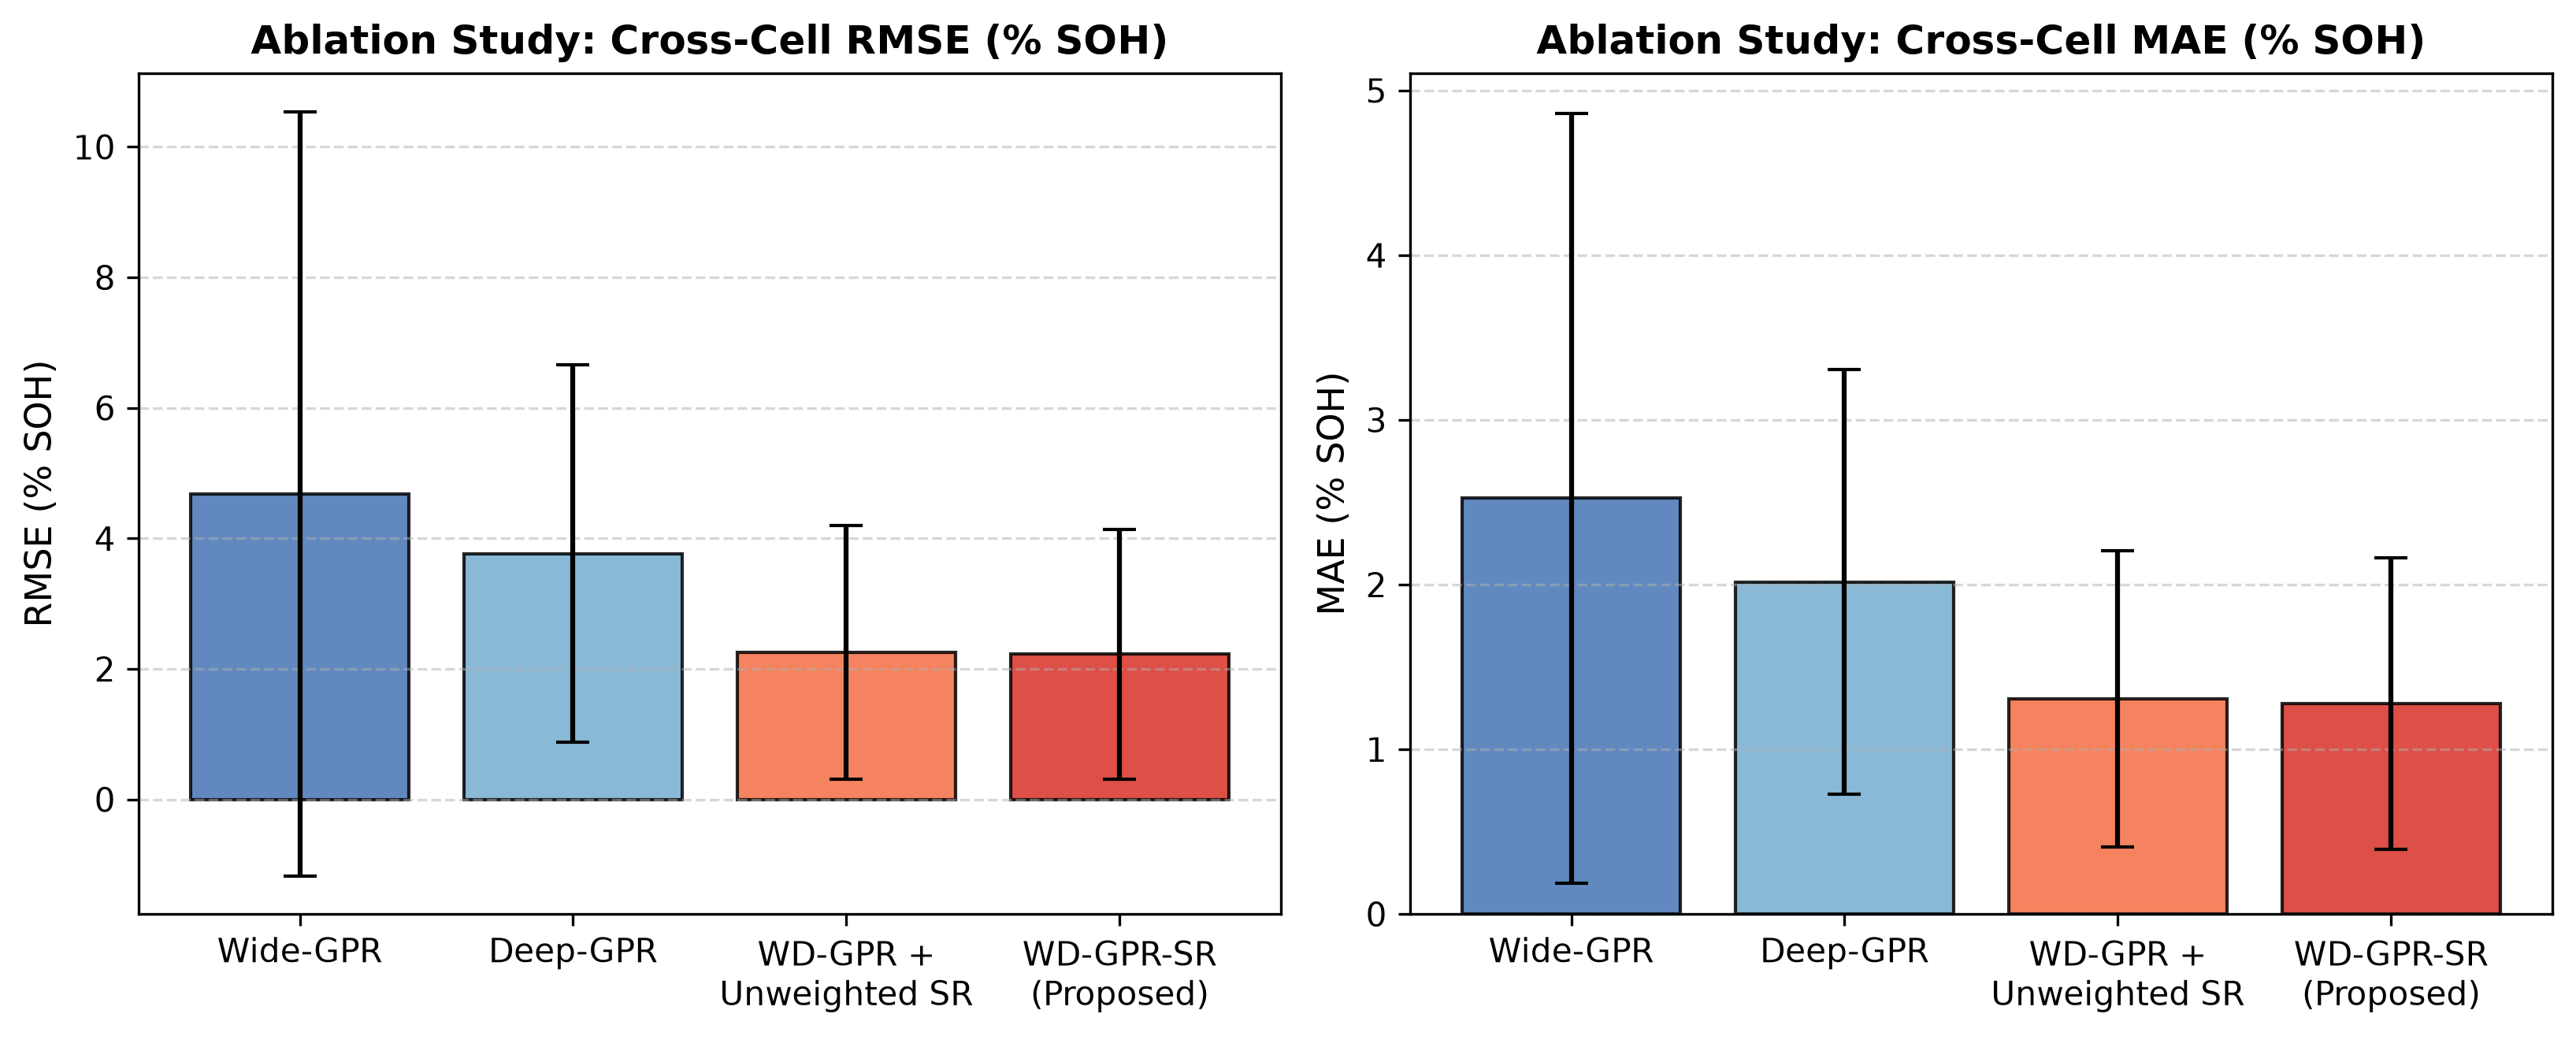

Figure: cycle_degradation_trajectories.png


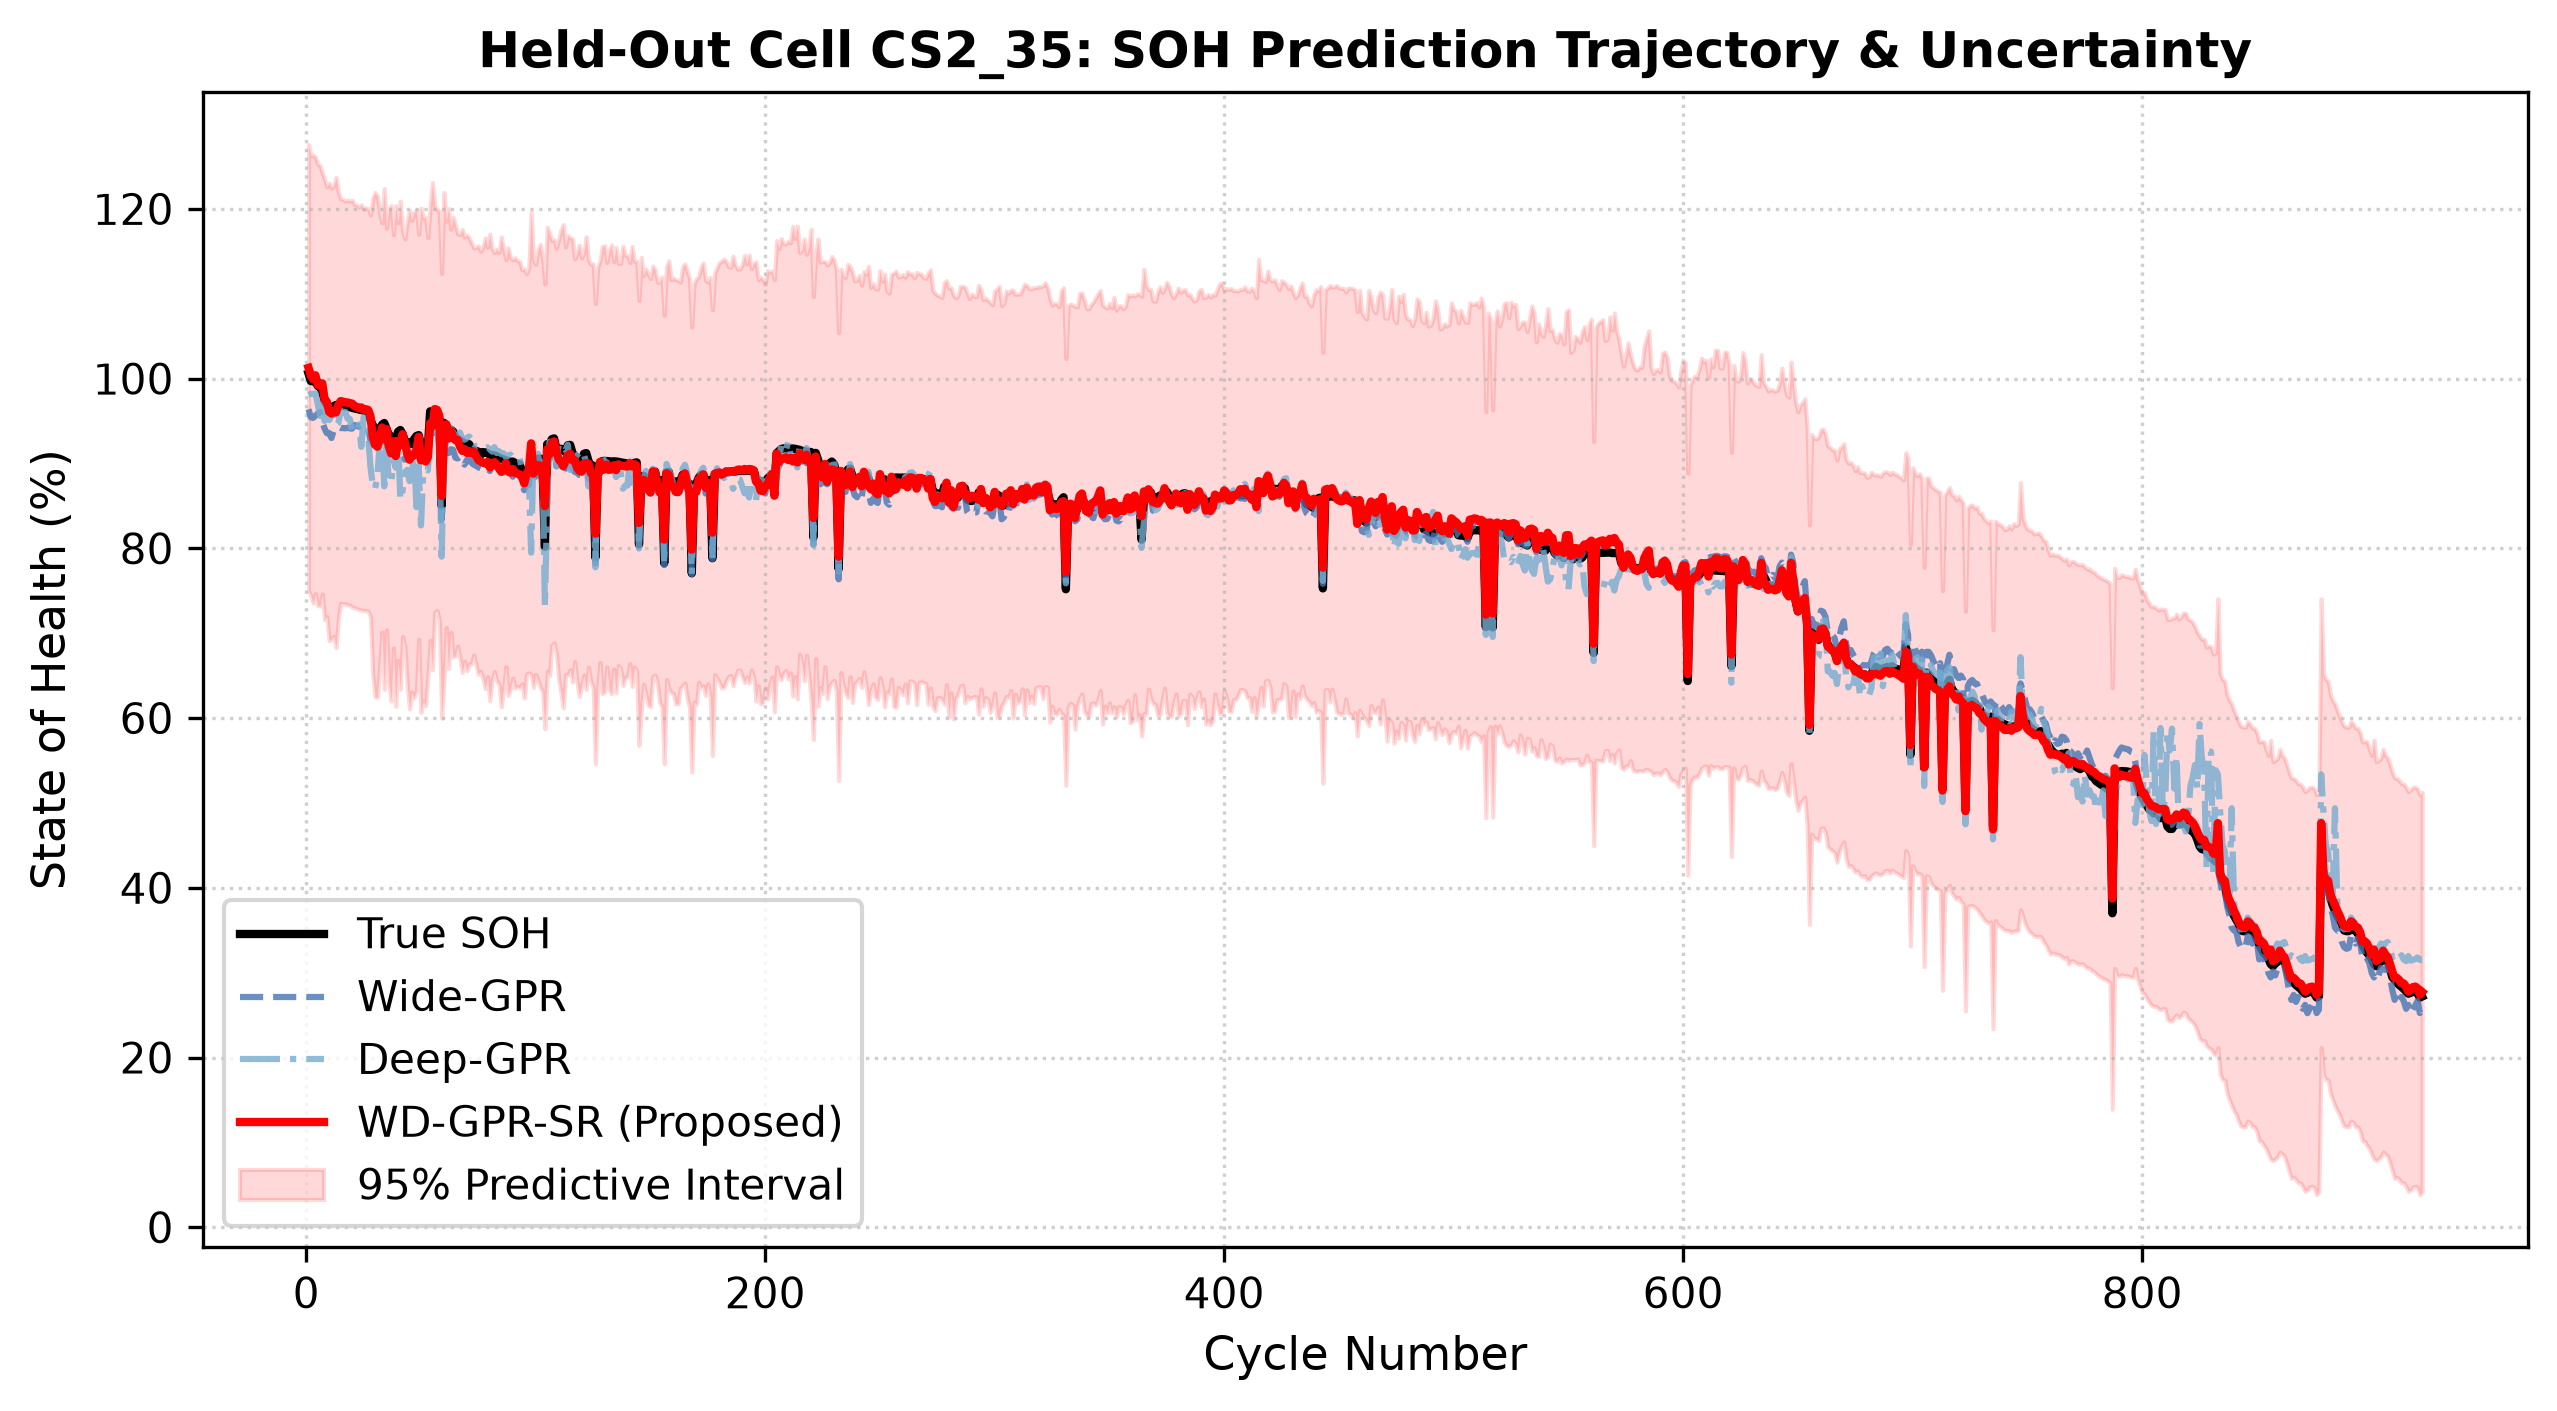

Figure: residual_correction_comparison.png


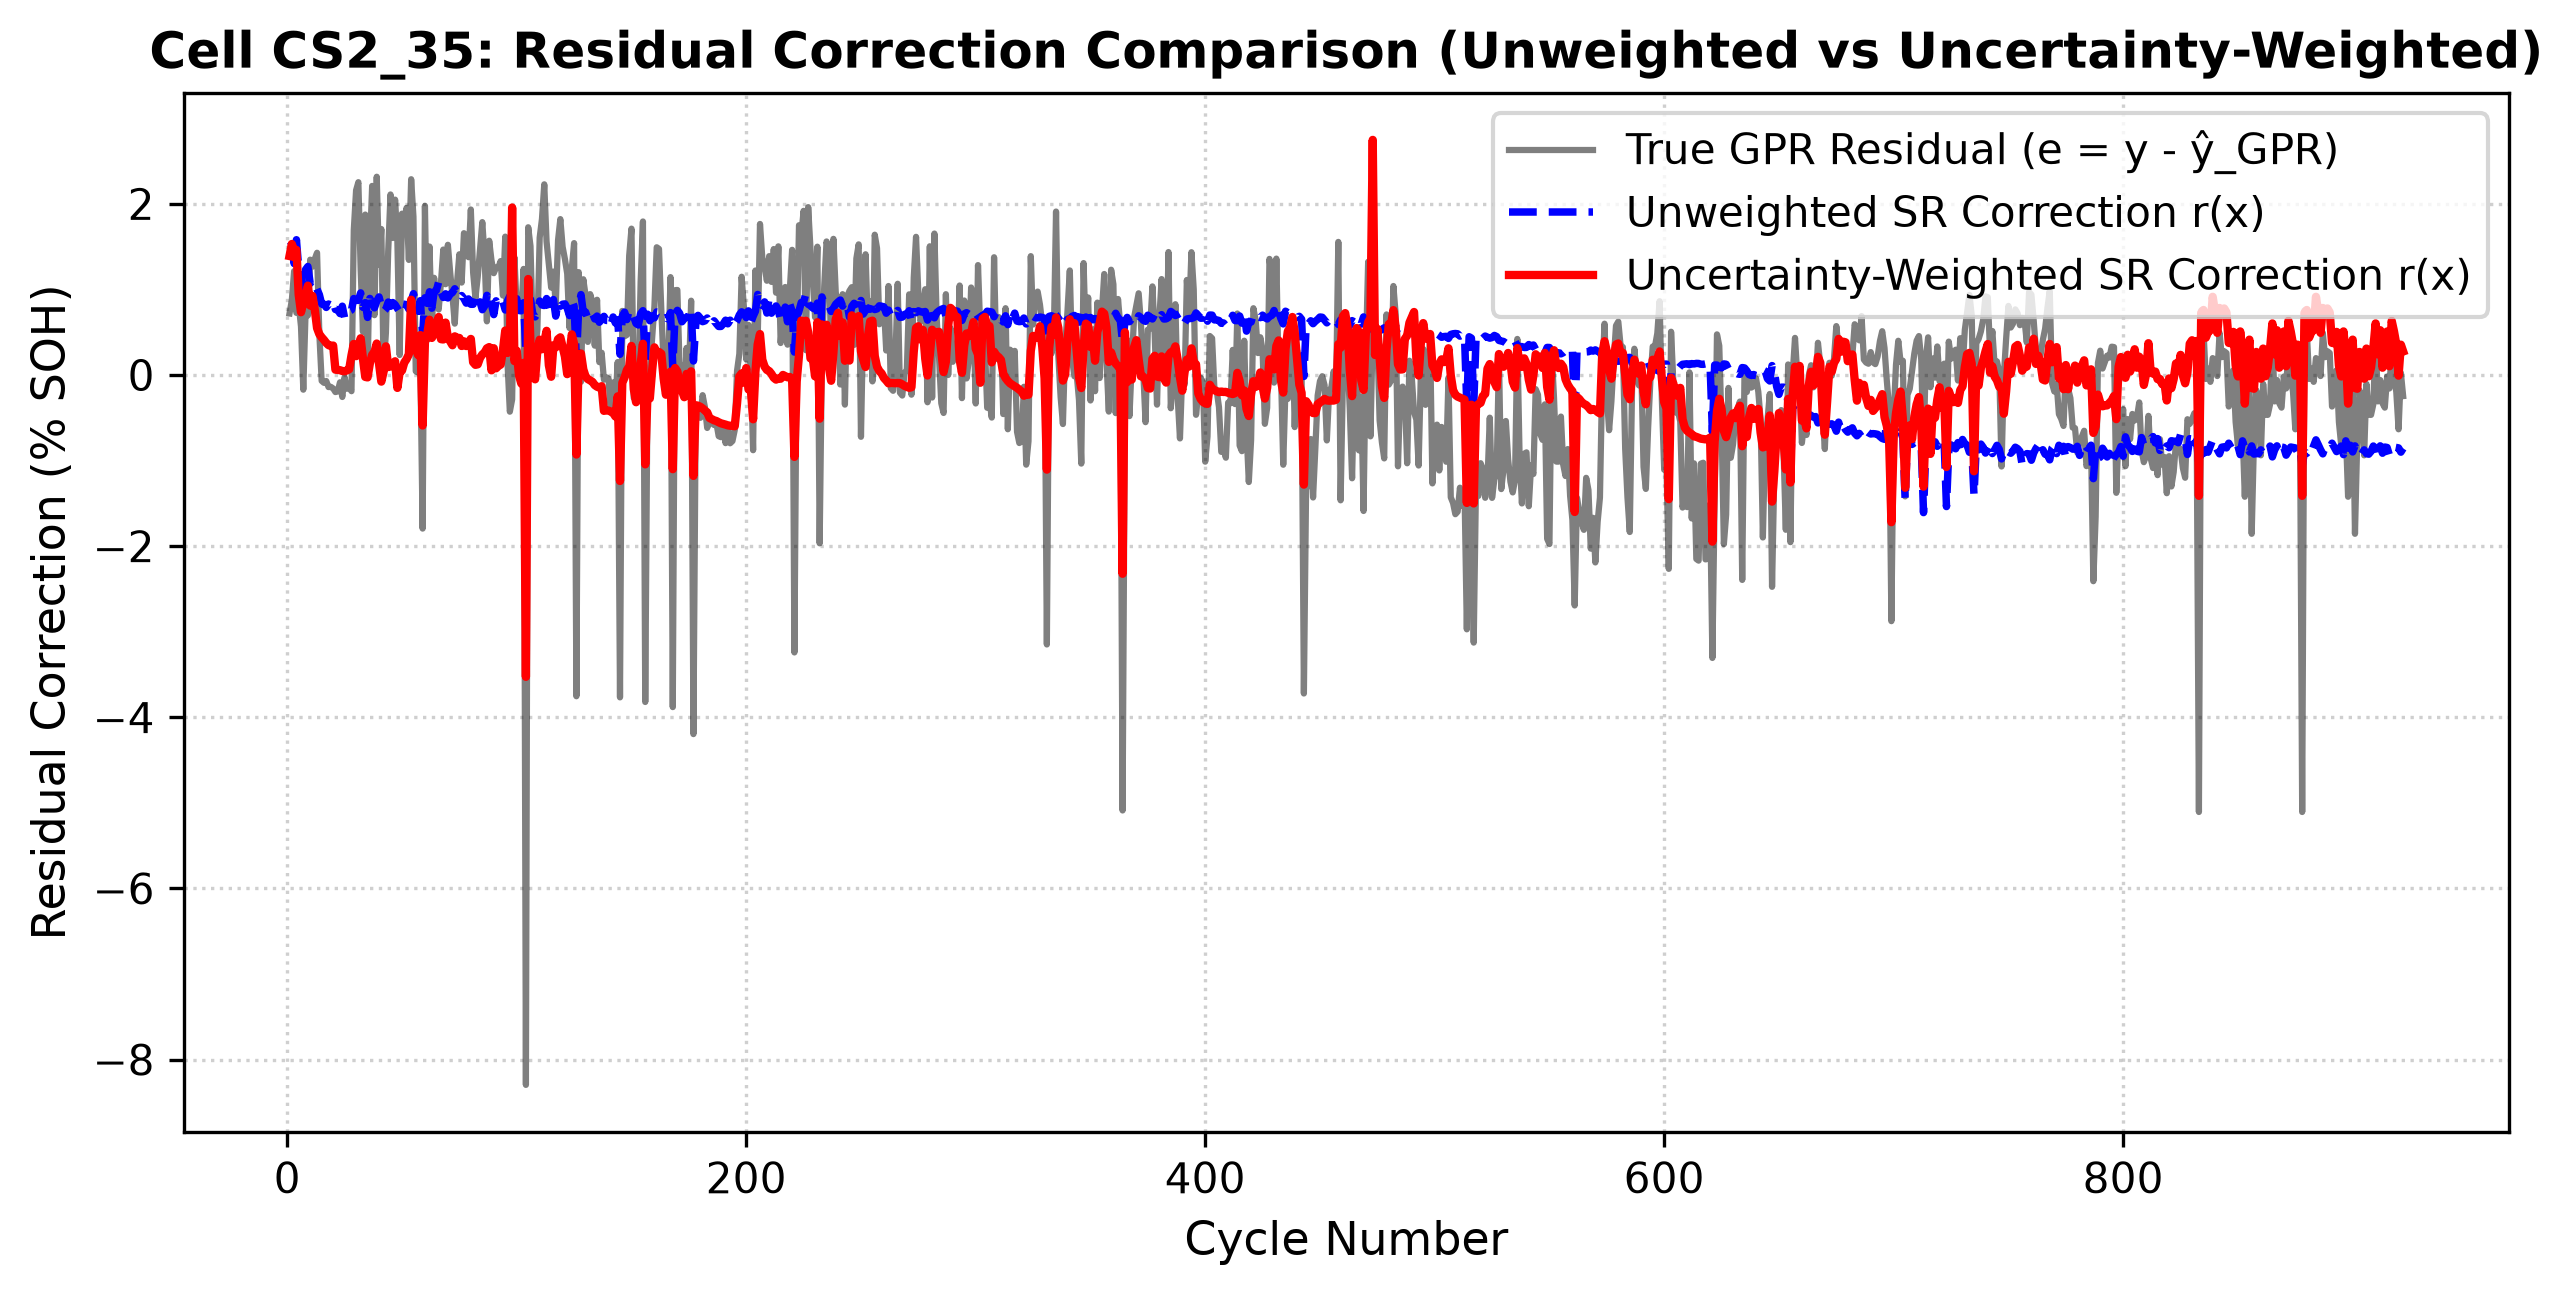

In [32]:
fig_dir = os.path.join(results_dir, 'figures')
p8_figs = [
    'ablation_metrics_comparison.png',
    'cycle_degradation_trajectories.png',
    'residual_correction_comparison.png',
]
for fname in p8_figs:
    fpath = os.path.join(fig_dir, fname)
    print(f"Figure: {fname}")
    if Image is not None and os.path.exists(fpath):
        display(Image(filename=fpath))

This cell verifies checkpoint reloadability across all three Phase 8 Gaussian Process model families (`WideGP`, `DeepGP`, and `WideAndDeepGP`) on `CS2_35 Seed 42`.

In [33]:
w_m, _, w_meta = load_wide_gpr_checkpoint(
    os.path.join(models_dir, 'phase8_wide_gpr_weights', 'wide_gpr_CS2_35_seed42.pt'), device=device
)
d_m, _, d_meta = load_deep_gpr_checkpoint(
    os.path.join(models_dir, 'phase8_deep_gpr_weights', 'deep_gpr_CS2_35_seed42.pt'), device=device
)
wd_m, _, wd_meta = load_wd_gpr_checkpoint(
    os.path.join(models_dir, 'phase7_wd_gpr_weights', 'wd_gpr_CS2_35_seed42.pt'), device=device
)

print(f"Reloaded {type(w_m).__name__:<14} | RMSE: {w_meta['metrics']['RMSE']:.4f}% | R2: {w_meta['metrics']['R2']:.4f}")
print(f"Reloaded {type(d_m).__name__:<14} | RMSE: {d_meta['metrics']['RMSE']:.4f}% | R2: {d_meta['metrics']['R2']:.4f}")
print(f"Reloaded {type(wd_m).__name__:<14} | RMSE: {wd_meta['metrics']['RMSE']:.4f}% | R2: {wd_meta['metrics']['R2']:.4f}")

Reloaded WideGP         | RMSE: 1.9508% | R2: 0.9891
Reloaded DeepGP         | RMSE: 3.1658% | R2: 0.9712
Reloaded WideAndDeepGP  | RMSE: 1.3435% | R2: 0.9948


## Phase 9: Six-Component Explainable AI (XAI) & Domain Interpretation
Phase 9 explains the proposed `WD-GPR-SR` model ($\hat{y}_{\text{WD-GPR-SR}}(x) = \hat{y}_{\text{GP}}(x) + r(x)$) and decomposes the contributions of its underlying Gaussian Process backbone and symbolic residual correction branch using six post-hoc and intrinsic methods:
1. **SHAP** (`KernelExplainer`, 50 k-means centroids, 80 held-out cycles on `CS2_35 Seed 2026`) + component decomposition.
2. **LIME** local surrogate rules at Beginning of Life (index 50), Knee-Point (index 450), and End of Life (index 902; labeled `Cycle 850` in saved plots/tables) on `CS2_35 Seed 2026`.
3. **PDP** (40 quantile grid points, 2nd–98th percentile) & **4. ICE** (25 individual cycle trajectories) on `CS2_35 Seed 2026`.
5. **GP ARD Lengthscale Relevance** across all 12 trained checkpoints (`||W_1[:, j]||_2 * mean(1/ell_d^2)`).
6. **Analytical SymPy Derivatives** ($\partial r / \partial x_j$) evaluated across all 12 discovered equations.

This cell executes `run_phase9.py` when `FORCE_RETRAIN = True` or audits all saved Phase 9 tables, figures, and metadata.


In [34]:
xai_dir = os.path.join(results_dir, 'xai')
xai_fig_dir = os.path.join(results_dir, 'figures', 'xai')
meta_p9_path = os.path.join(xai_dir, 'phase9_experiment_metadata.json')

if FORCE_RETRAIN or not os.path.exists(meta_p9_path):
    print("Running Phase 9 XAI pipeline via run_phase9.py...")
    subprocess.run([sys.executable, os.path.join(PROJECT_ROOT, 'run_phase9.py')], cwd=PROJECT_ROOT, check=True)

with open(meta_p9_path, 'r', encoding='utf-8') as f:
    p9_meta = json.load(f)

print(f"Phase 9 Metadata | Device: {p9_meta.get('hardware_device')} | Duration: {p9_meta.get('total_execution_minutes', 'N/A')} min")
print("Components:", len(p9_meta.get('xai_components_evaluated', [])), "| Tables:", len(p9_meta.get('tables_generated', [])), "| Figures:", len(p9_meta.get('figures_generated', [])))

Phase 9 Metadata | Device: cpu | Duration: 0.17 min
Components: 6 | Tables: 5 | Figures: 8


This cell inspects the global SHAP component decomposition on `CS2_35 Seed 2026` (`Discharge_Time` dominates with mean $|\text{SHAP}| = 14.3729\%$) and displays Figures 1–2; because signed Shapley values are additive, opposite-sign symbolic slopes (such as `Avg_Voltage`) partially cancel the GP attribution, making mean absolute SHAP non-additive (`1.7117 != 4.3784 + 2.6704`).

,Feature,Raw_Feature_Name,Mean_Abs_SHAP_Full_WD_GPR_SR,Mean_Abs_SHAP_GP_Branch,Mean_Abs_SHAP_Symbolic_Correction
0,Discharge Time (s),Discharge_Time,14.372887,10.865932,3.509495
1,Avg Voltage (V),Avg_Voltage,1.711682,4.378423,2.670428
2,Avg Resistance (Ω),Avg_Resistance,0.574637,0.574637,0.000000
3,CC Charge Time (s),CC_Charge_Time,0.438602,1.062851,0.956124


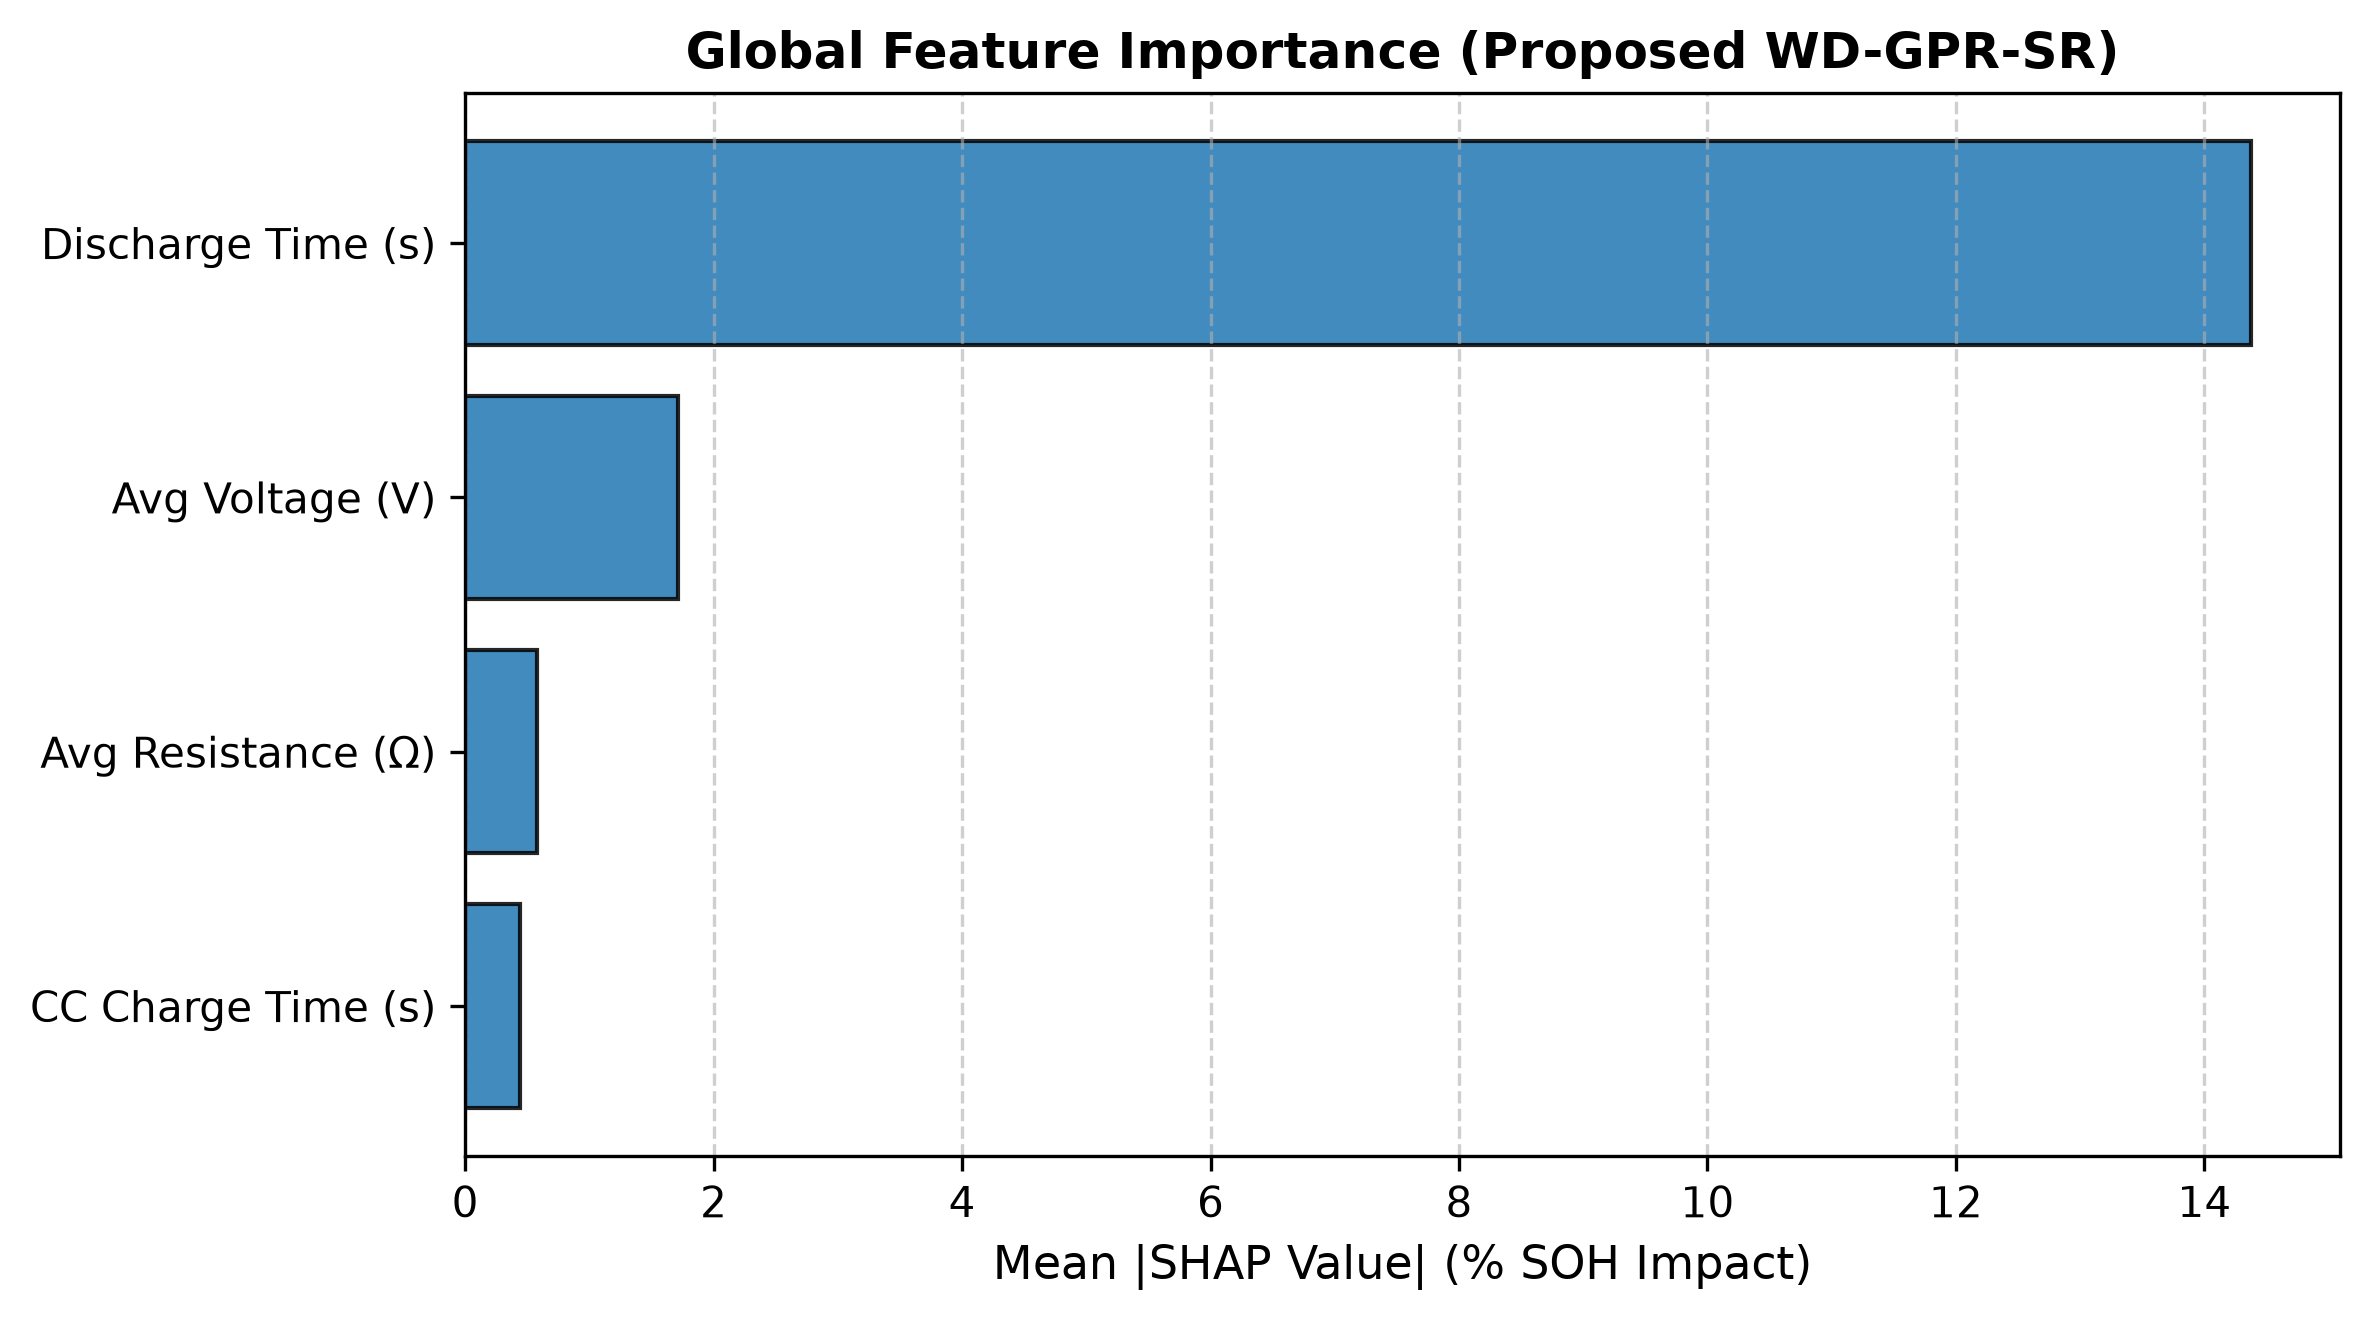

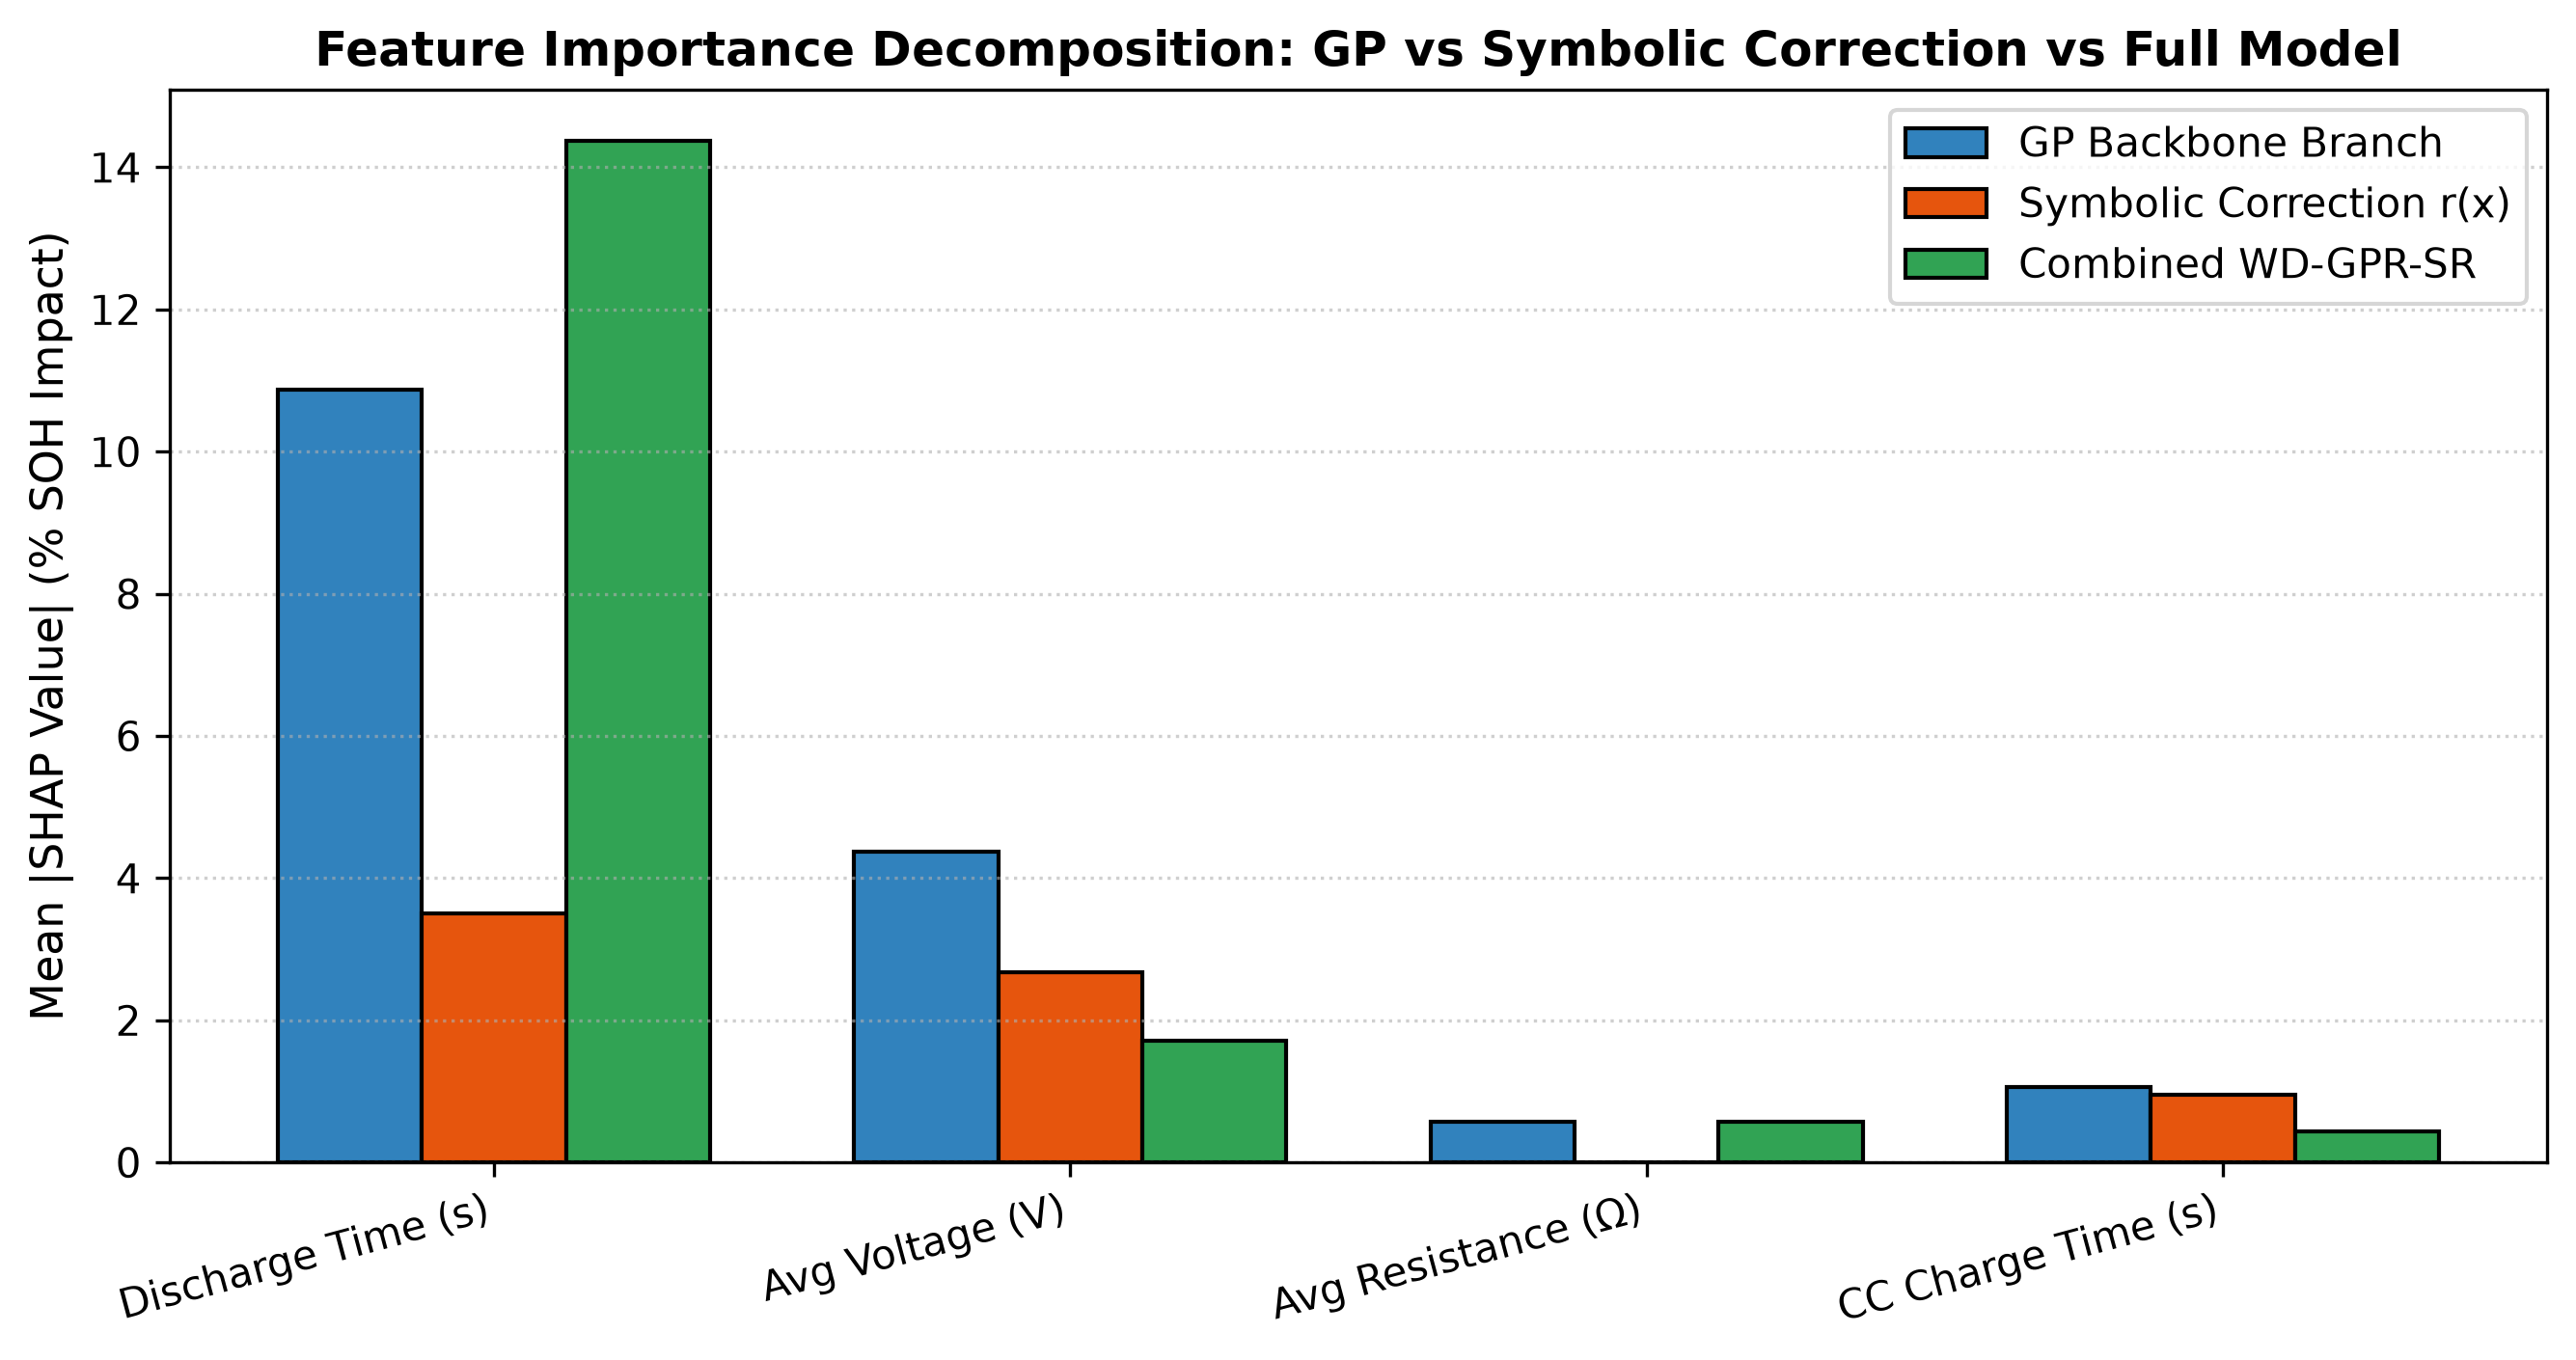

In [35]:
df_shap = pd.read_csv(os.path.join(xai_dir, 'shap_component_decomposition.csv'))
display(df_shap)

for fname in ('01_shap_global_summary_bar.png', '02_shap_component_decomposition_comparison.png'):
    fpath = os.path.join(xai_fig_dir, fname)
    if Image is not None and os.path.exists(fpath):
        display(Image(filename=fpath))

This cell examines local lifecycle explanations across Beginning of Life (index 50), Knee-Point (index 450), and End of Life (index 902; labeled `Cycle 850` in the saved Phase 9 plots and table) via LIME surrogate rules and SHAP waterfall plots (Figures 3–4).

,Stage,Cycle,True_SOH,Rule,LIME_Weight
0,Beginning of Life (Cycle 50),50,92.119564,Discharge_Time > 0.73,20.151153
1,Beginning of Life (Cycle 50),50,92.119564,Avg_Resistance <= -0.60,-1.650350
2,Beginning of Life (Cycle 50),50,92.119564,Avg_Voltage > 0.64,1.637239
3,Beginning of Life (Cycle 50),50,92.119564,CC_Charge_Time > 0.78,0.134126
4,Knee-Point Phase (Cycle 450),450,85.828860,0.40 < Discharge_Time <= 0.73,11.064048
5,Knee-Point Phase (Cycle 450),450,85.828860,0.35 < CC_Charge_Time <= 0.78,-1.116176
6,Knee-Point Phase (Cycle 450),450,85.828860,Avg_Voltage > 0.64,1.111184
7,Knee-Point Phase (Cycle 450),450,85.828860,-0.60 < Avg_Resistance <= -0.28,-0.199277
8,End of Life (Cycle 850),902,31.087530,Discharge_Time <= -0.39,-31.158147
9,End of Life (Cycle 850),902,31.087530,Avg_Voltage <= -0.09,-2.842267


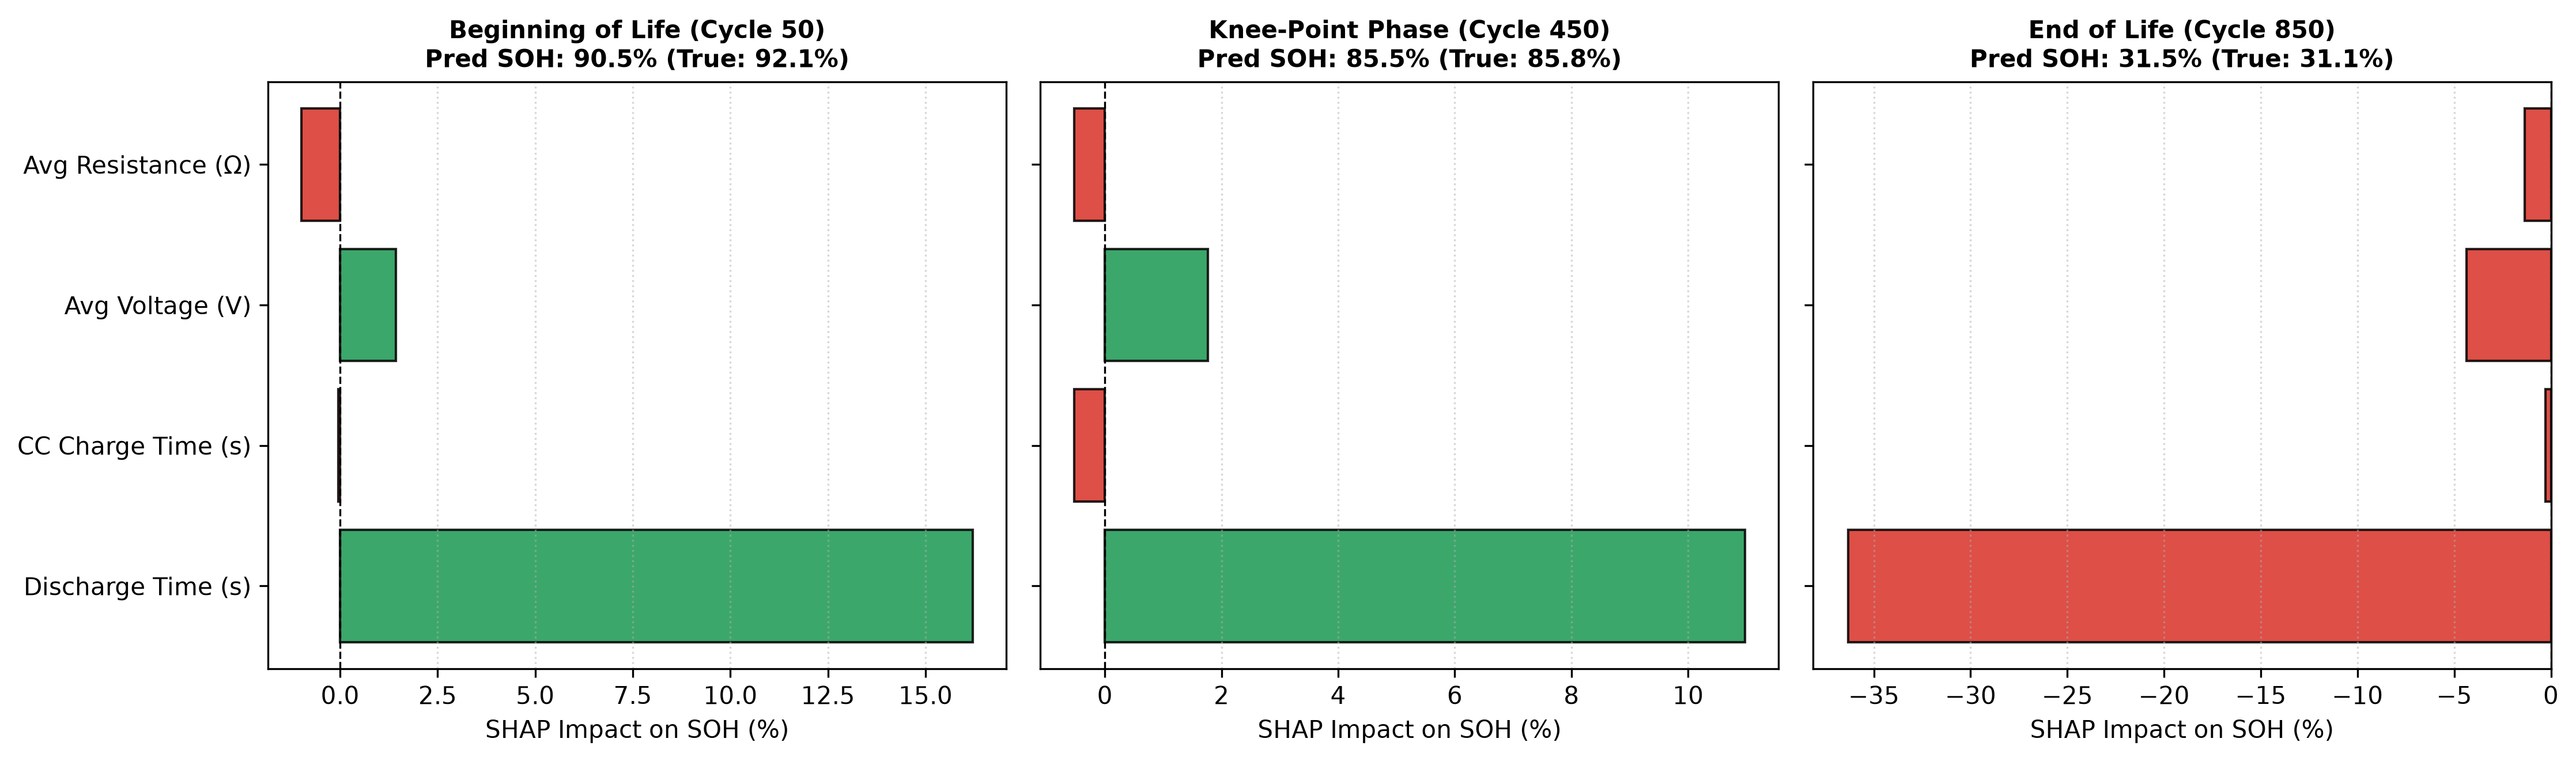

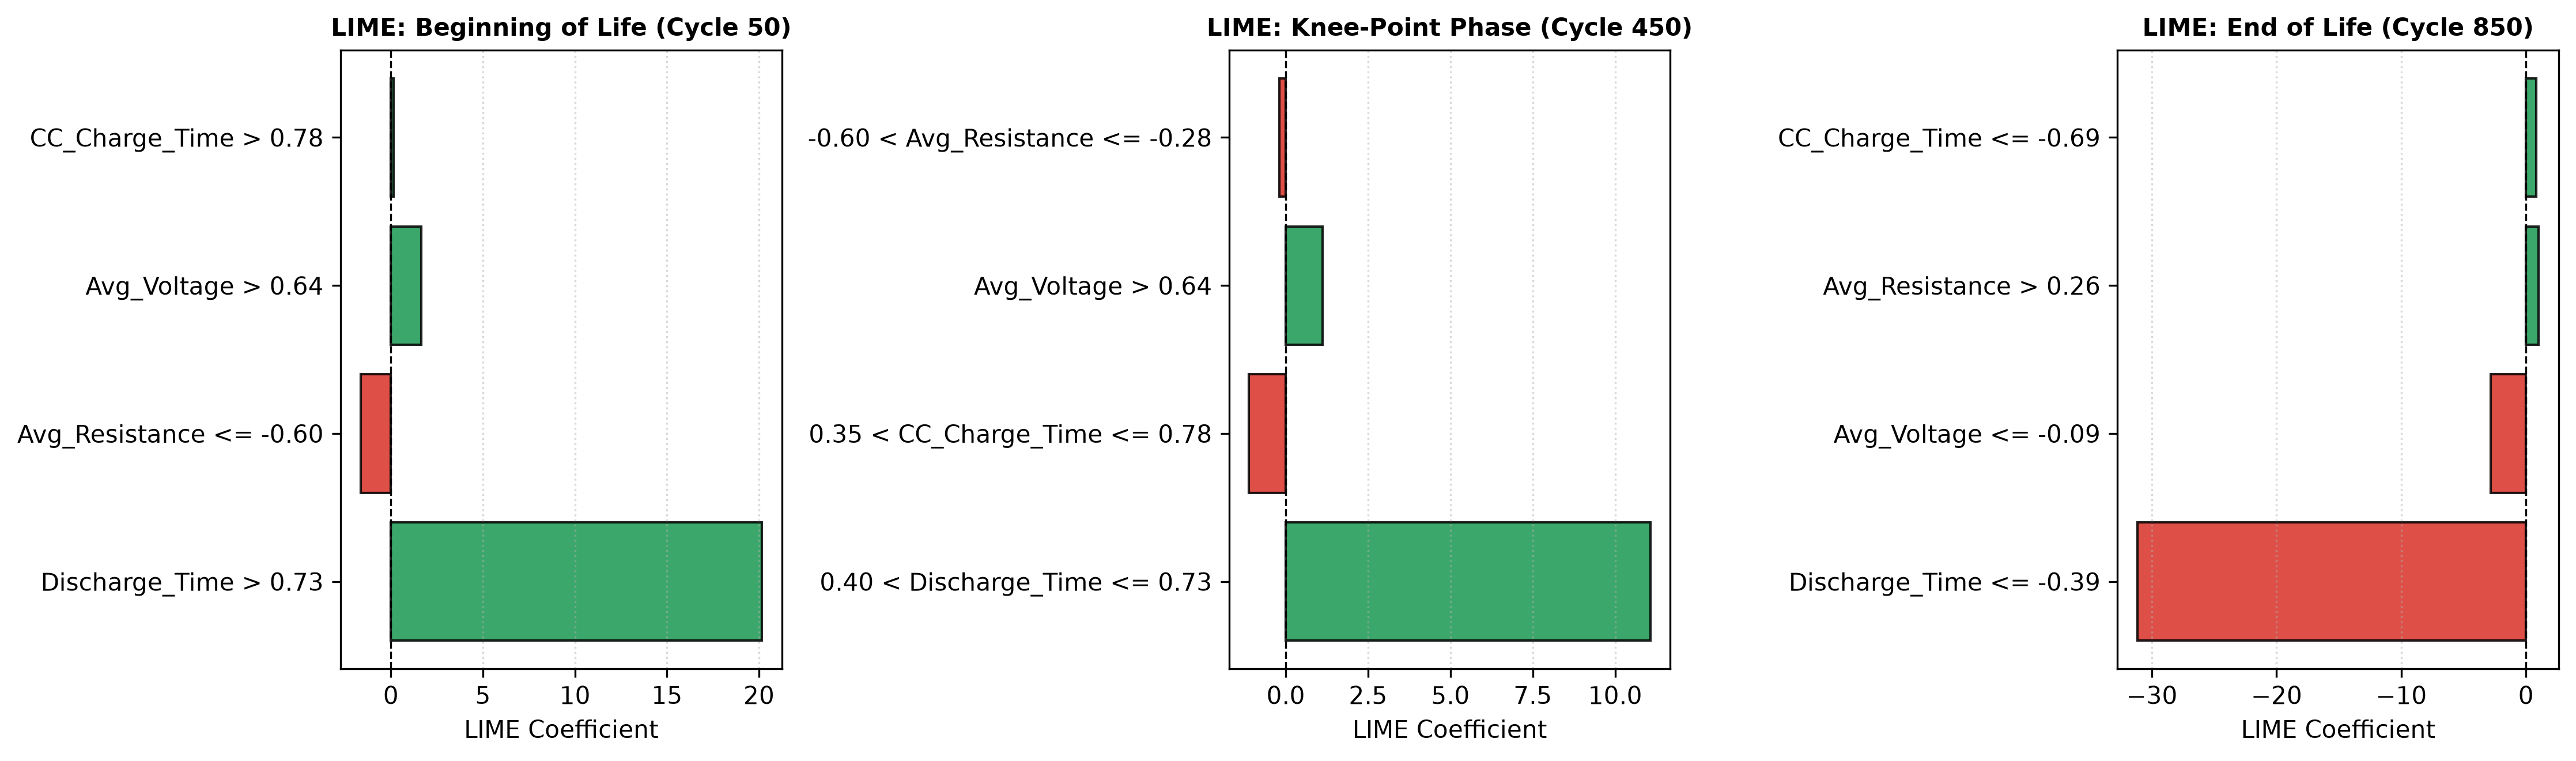

In [36]:
df_lime = pd.read_csv(os.path.join(xai_dir, 'lime_lifecycle_explanations.csv'))
display(df_lime)

for fname in ('03_shap_local_waterfalls_lifecycle.png', '04_lime_local_explanations_lifecycle.png'):
    fpath = os.path.join(xai_fig_dir, fname)
    if Image is not None and os.path.exists(fpath):
        display(Image(filename=fpath))

This cell summarizes Partial Dependence (PDP) response ranges over the 40-point empirical feature grids and displays PDP and ICE heterogeneity plots (Figures 5–6).

,Physical_Min,Physical_Max,Full_Pred_Min,Full_Pred_Max,SR_Correction_Min,SR_Correction_Max
Feature,,,,,,
Avg_Resistance,0.0878,0.1224,76.4254,77.7271,0.0386,0.0386
Avg_Voltage,3.3434,3.6624,74.2451,79.1600,-2.7278,8.4121
CC_Charge_Time,2964.1526,6477.2081,76.1546,77.5641,-1.3921,1.8432
Discharge_Time,1049.7166,3575.8994,39.5439,96.3311,-9.9209,4.5541


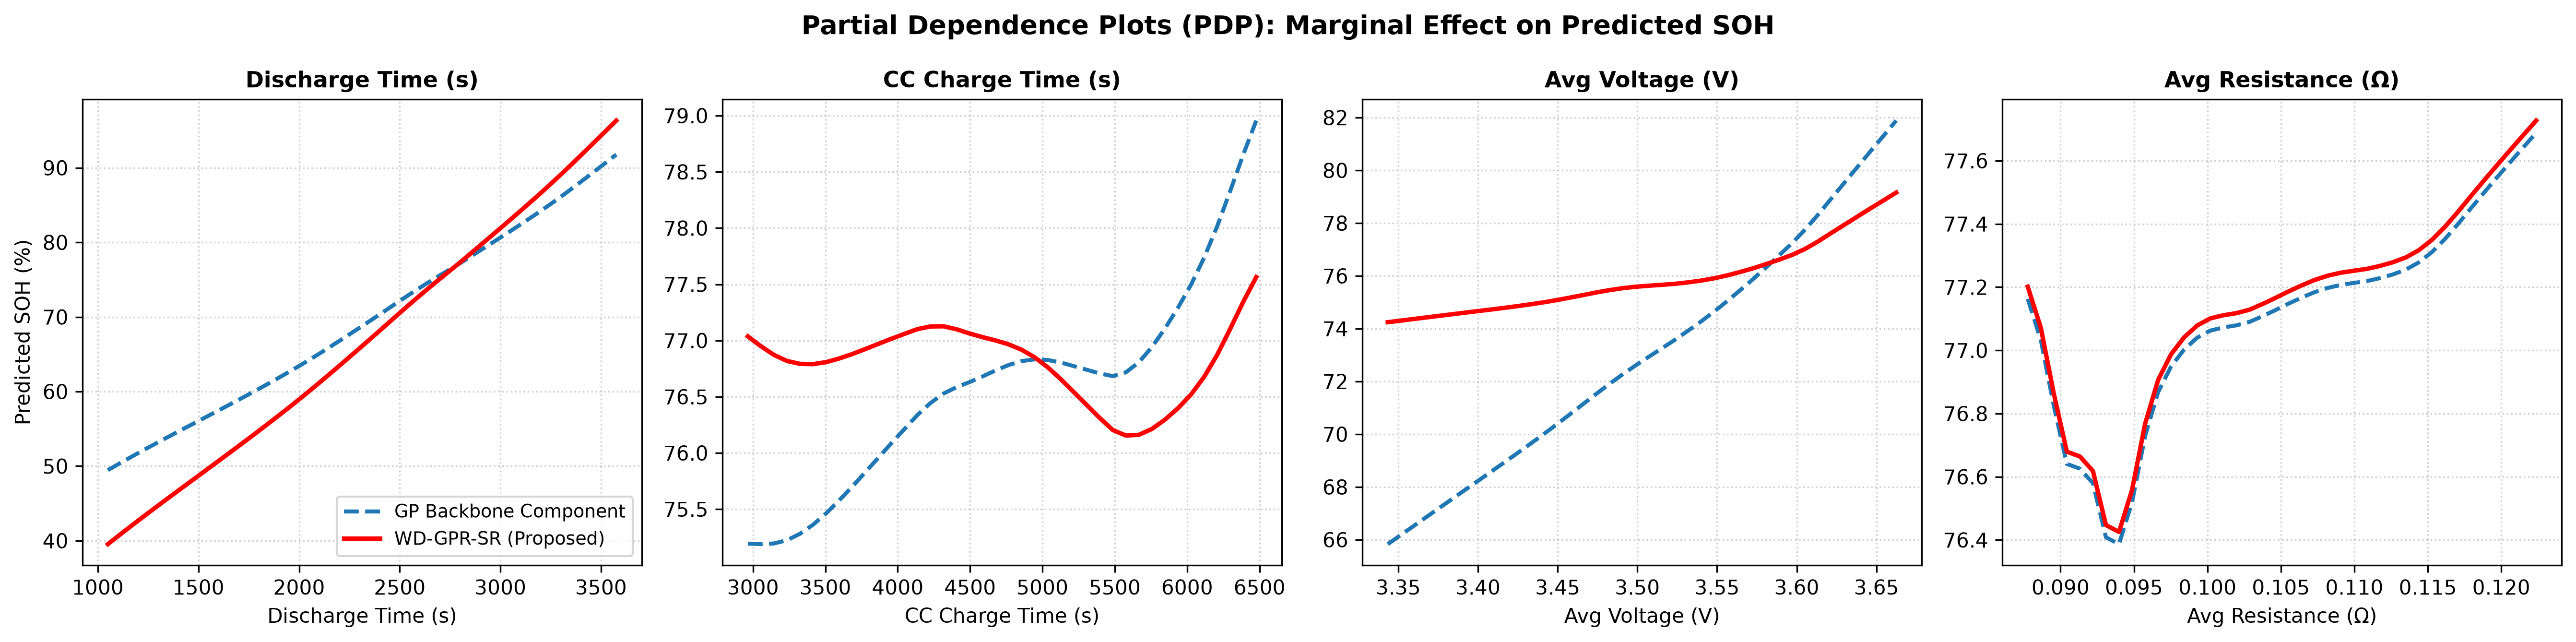

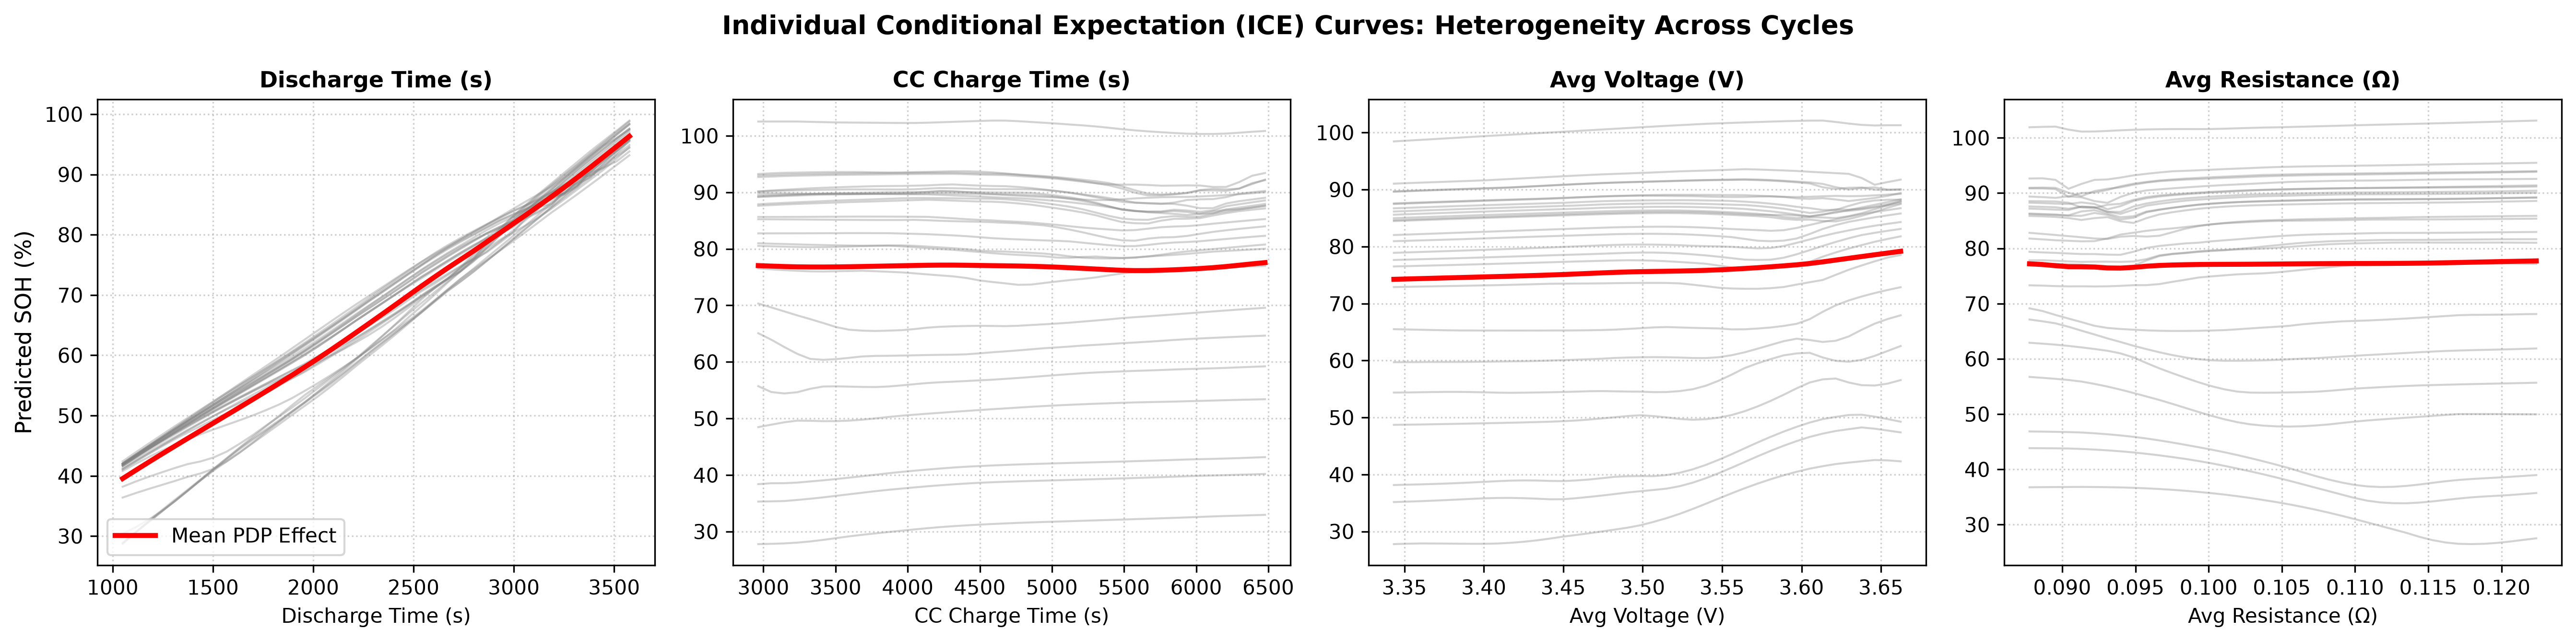

In [37]:
df_pdp = pd.read_csv(os.path.join(xai_dir, 'pdp_grid_data.csv'))
pdp_summary = df_pdp.groupby('Feature').agg(
    Physical_Min=('Physical_Value', 'min'),
    Physical_Max=('Physical_Value', 'max'),
    Full_Pred_Min=('PDP_Full_WD_GPR_SR', 'min'),
    Full_Pred_Max=('PDP_Full_WD_GPR_SR', 'max'),
    SR_Correction_Min=('PDP_SR_Correction', 'min'),
    SR_Correction_Max=('PDP_SR_Correction', 'max'),
).round(4)
display(pdp_summary)

for fname in ('05_pdp_marginal_dependence.png', '06_ice_curves_heterogeneity.png'):
    fpath = os.path.join(xai_fig_dir, fname)
    if Image is not None and os.path.exists(fpath):
        display(Image(filename=fpath))

This cell aggregates GP ARD relevance metrics across all 12 Phase 7 checkpoints and displays Figure 7; because `Effective_ARD_Score` multiplies each input column norm $\|W_1[:, j]\|_2$ by the scalar `mean(1/ell_d^2)`, normalization yields nearly uniform feature percentages (`24.28%–25.98%`) reflecting input-layer weight magnitudes across learned latent embeddings (`Mean_Latent_Lengthscale = 0.5904 ± 0.0423`).

,Relevance_Pct_Mean,Relevance_Pct_Std,W1_Norm_Mean,Wide_Outputscale_Mean,Deep_Outputscale_Mean,Mean_Latent_Ell
Feature,,,,,,
CC_Charge_Time,25.9814,2.5278,1.8799,0.5545,0.4611,0.5904
Avg_Voltage,24.8873,3.1526,1.8003,0.5545,0.4611,0.5904
Discharge_Time,24.8481,2.4535,1.7940,0.5545,0.4611,0.5904
Avg_Resistance,24.2832,3.5602,1.7535,0.5545,0.4611,0.5904


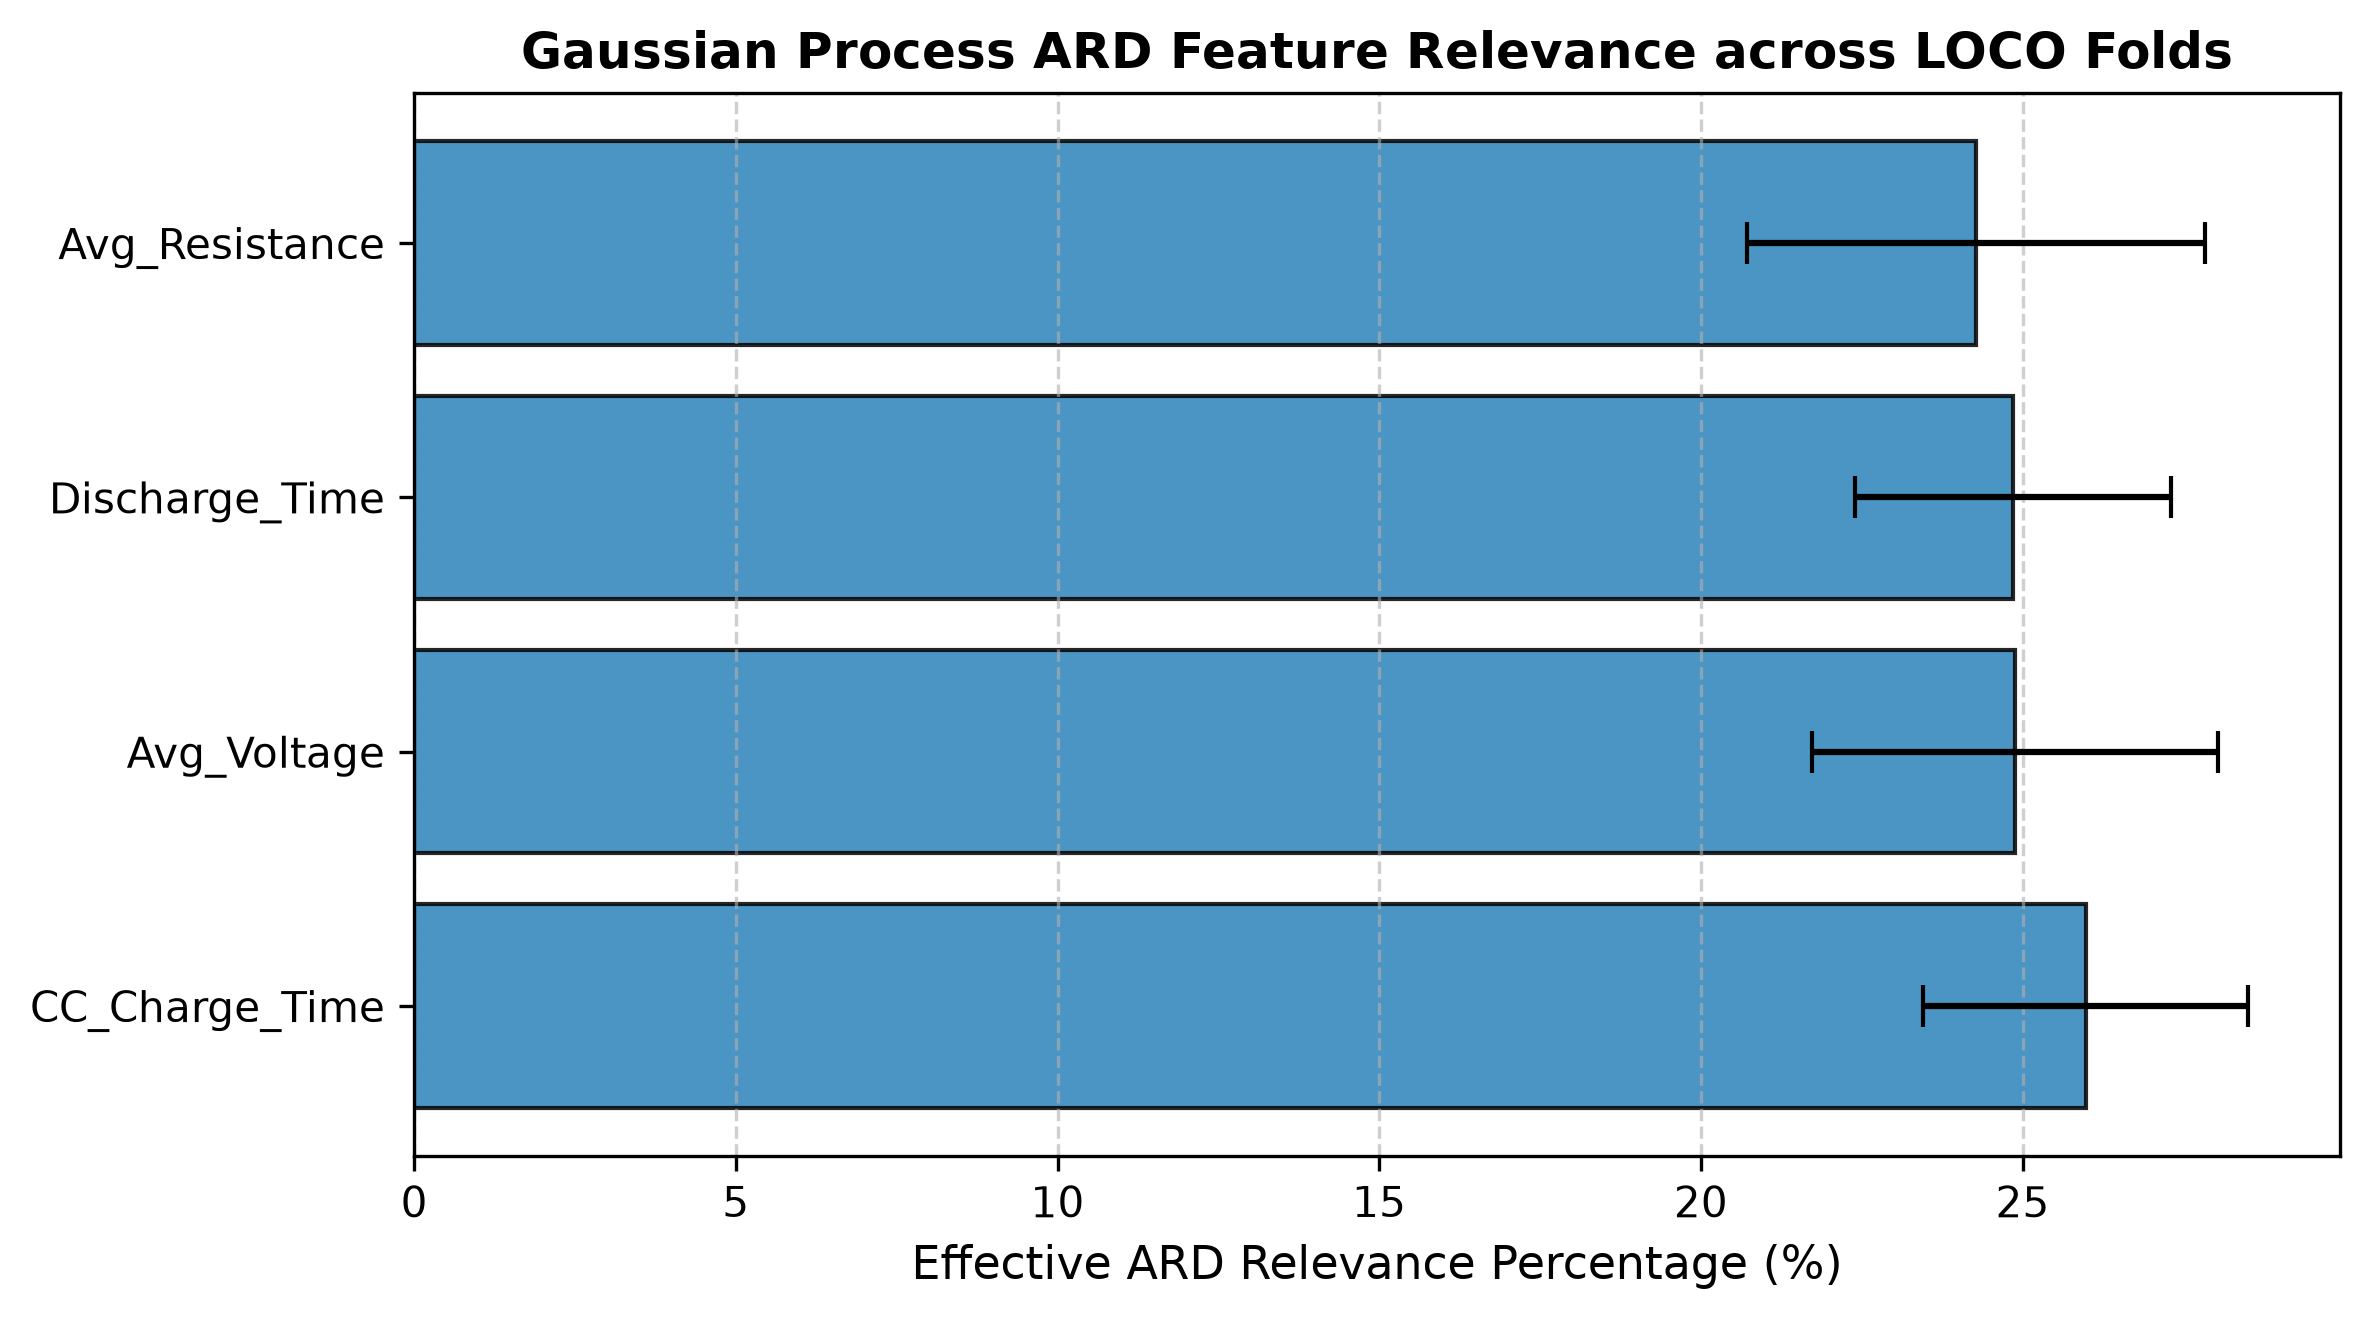

In [38]:
df_ard = pd.read_csv(os.path.join(xai_dir, 'gp_ard_feature_relevance.csv'))
ard_summary = df_ard.groupby('Feature').agg(
    Relevance_Pct_Mean=('Relevance_Percentage', 'mean'),
    Relevance_Pct_Std=('Relevance_Percentage', 'std'),
    W1_Norm_Mean=('W1_Column_Norm', 'mean'),
    Wide_Outputscale_Mean=('Wide_Outputscale', 'mean'),
    Deep_Outputscale_Mean=('Deep_Outputscale', 'mean'),
    Mean_Latent_Ell=('Mean_Latent_Lengthscale', 'mean'),
).sort_values('Relevance_Pct_Mean', ascending=False).round(4)
display(ard_summary)

fpath_ard = os.path.join(xai_fig_dir, '07_gp_ard_lengthscales_relevance.png')
if Image is not None and os.path.exists(fpath_ard):
    display(Image(filename=fpath_ard))

This cell evaluates analytical SymPy partial derivatives $\partial r / \partial x_j$ across all 12 Phase 7 symbolic residual equations (`Mean |dr/dx|`: `Discharge_Time = 1.5052 ± 1.3285`, `Avg_Resistance = 1.0530 ± 1.1449`, `Avg_Voltage = 0.3292 ± 0.8614`, `CC_Charge_Time = 0.2107 ± 0.3984`) and displays Figure 8.

,mean,std,max
Feature,,,
Discharge_Time,1.5052,1.3285,4.1657
Avg_Resistance,1.0530,1.1449,4.1657
Avg_Voltage,0.3292,0.8614,2.8866
CC_Charge_Time,0.2107,0.3984,1.0000


,Test_Cell,Seed,Feature,Partial_Derivative,Mean_Abs_Derivative
0,CS2_35,42,Discharge_Time,Avg_Resistance + 2*Discharge_Time + 2.1331363,2.307934
1,CS2_35,42,CC_Charge_Time,0,0.000000
2,CS2_35,42,Avg_Voltage,0,0.000000
3,CS2_35,42,Avg_Resistance,Discharge_Time + 2.1331363,2.163570
4,CS2_35,100,Discharge_Time,0.93771863 - Avg_Resistance,1.063209
5,CS2_35,100,CC_Charge_Time,0,0.000000
6,CS2_35,100,Avg_Voltage,Avg_Resistance - 0.93771863,1.063209
7,CS2_35,100,Avg_Resistance,Avg_Voltage - Discharge_Time,0.155979
8,CS2_35,2026,Discharge_Time,3.88660586589487,3.886606
9,CS2_35,2026,CC_Charge_Time,-1,1.000000


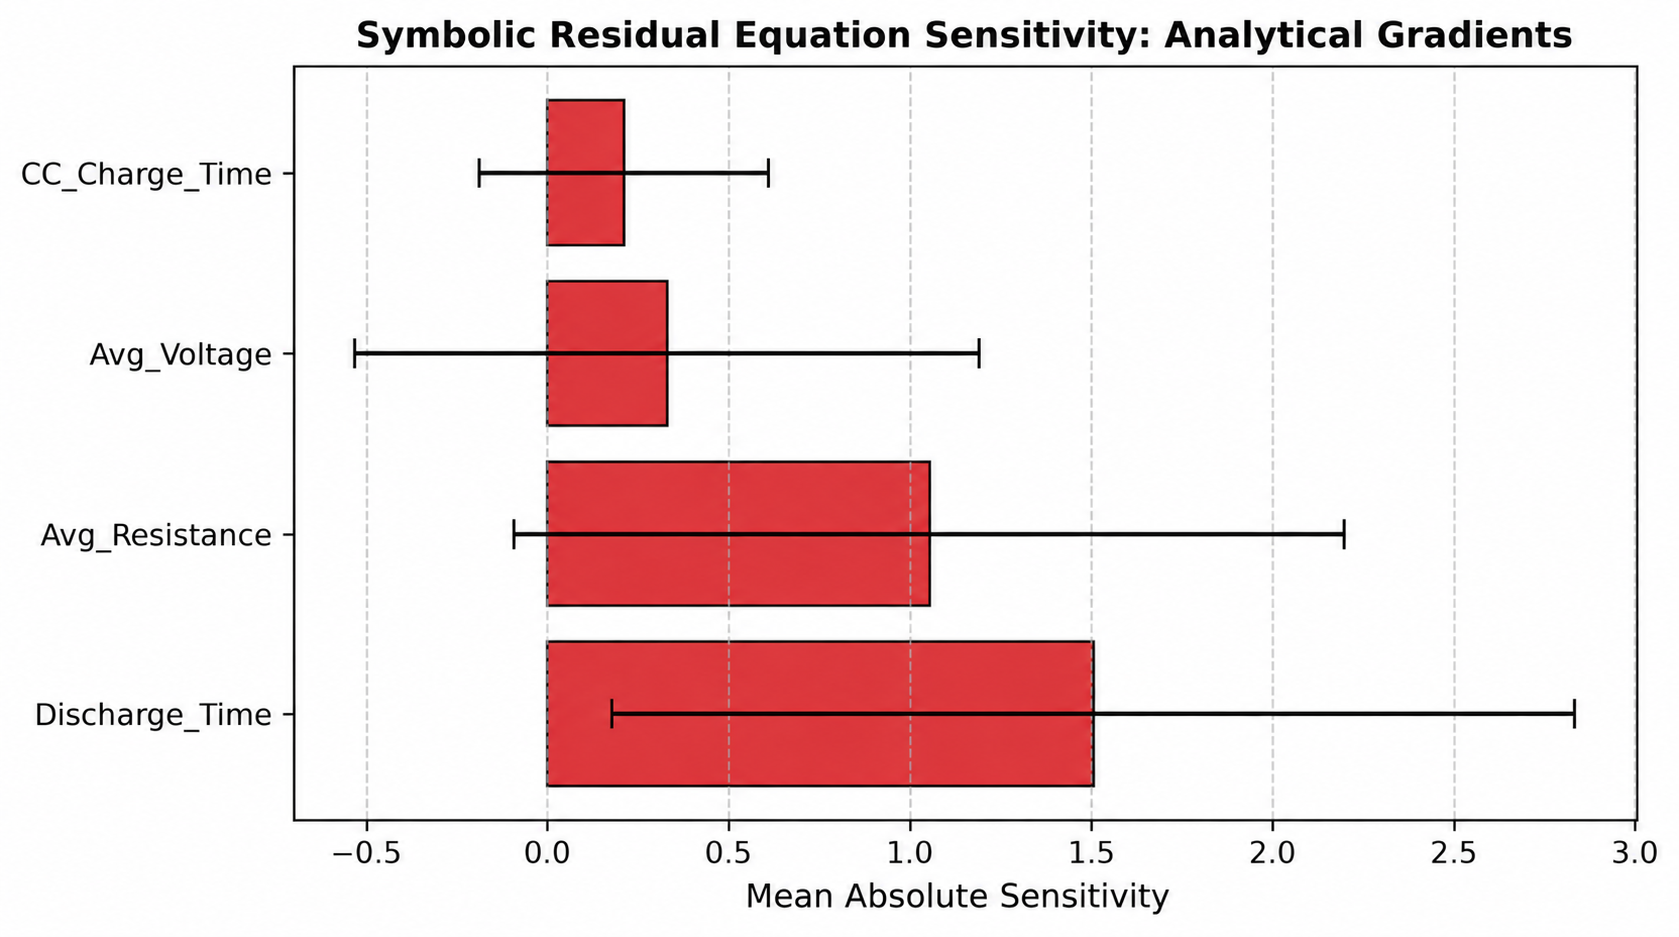

In [39]:
df_sympy = pd.read_csv(os.path.join(xai_dir, 'symbolic_sensitivity_derivatives.csv'))
sympy_summary = df_sympy.groupby('Feature')['Mean_Abs_Derivative'].agg(['mean', 'std', 'max']).sort_values('mean', ascending=False).round(4)
display(sympy_summary)
display(df_sympy[['Test_Cell', 'Seed', 'Feature', 'Partial_Derivative', 'Mean_Abs_Derivative']].head(12))

fpath_sympy = os.path.join(xai_fig_dir, '08_symbolic_derivatives_sensitivity.png')
if Image is not None and os.path.exists(fpath_sympy):
    display(Image(filename=fpath_sympy))

This cell performs a final end-to-end deployment check by reloading the representative `CS2_35 Seed 2026` checkpoint (`wd_gpr_CS2_35_seed2026.pt`) and preprocessor (`prep_CS2_35.joblib`), running live `predict_wd_gpr` inference on held-out `CS2_35`, and verifying exact agreement against saved Phase 7 test predictions.

In [40]:
rep_ckpt = os.path.join(models_dir, 'phase7_wd_gpr_weights', 'wd_gpr_CS2_35_seed2026.pt')
rep_prep = joblib.load(os.path.join(models_dir, 'phase7_preprocessors', 'prep_CS2_35.joblib'))
rep_preds_saved = pd.read_csv(os.path.join(models_dir, 'phase7_test_predictions', 'predictions_CS2_35_seed2026.csv'))

rep_model, rep_lik, rep_meta = load_wd_gpr_checkpoint(rep_ckpt, device=device)
fold_cs2_35 = pipeline.get_loco_fold('CS2_35')
test_x_tensor = torch.tensor(fold_cs2_35['X_test_scaled'], dtype=torch.float32)
mean_live, sigma_live = predict_wd_gpr(
    rep_model,
    rep_lik,
    test_x_tensor,
    y_train_mean=rep_prep['y_train_mean'],
    y_train_std=rep_prep['y_train_std'],
    device=device,
)

max_diff = float(np.max(np.abs(mean_live - rep_preds_saved['GPR_Pred'].to_numpy())))
sr_metrics = compute_regression_metrics(
    rep_preds_saved['True_SOH(%)'].to_numpy(),
    rep_preds_saved['WD_GPR_SR_Pred'].to_numpy(),
    sigma_pred=rep_preds_saved['GPR_Sigma'].to_numpy(),
)
print(f"Live vs. saved GPR max |diff| (CS2_35 Seed 2026): {max_diff:.6e}")
print(f"CS2_35 Seed 2026 WD-GPR-SR Metrics: RMSE={sr_metrics['RMSE']:.4f}%, MAE={sr_metrics['MAE']:.4f}%, R2={sr_metrics['R2']:.4f}, PICP={sr_metrics['PICP(%)']:.2f}%")

Live vs. saved GPR max |diff| (CS2_35 Seed 2026): 3.791504e-06
CS2_35 Seed 2026 WD-GPR-SR Metrics: RMSE=0.8426%, MAE=0.6673%, R2=0.9980, PICP=100.00%


## Final Project Synthesis, Scientific Findings & Methodological Limitations

### 1. Core Architectural & Empirical Findings
* **Superiority of the Proposed WD-GPR-SR Architecture**: The proposed **WD-GPR-SR** framework achieves the best overall performance among all evaluated ablation architectures with a mean cross-cell test **RMSE of `2.2238 ± 1.9191%`** and $R^2 = 0.9822 \pm 0.0163$. It substantially outperforms both single-branch Gaussian Process variants—reducing generalization RMSE by **52.5%** compared to isolated `Wide-GPR` (`4.6856 ± 5.8566%`) and by **41.0%** compared to isolated `Deep-GPR` (`3.7657 ± 2.8894%`)—confirming that uniting wide linear global trends with deep non-linear Matérn representations and symbolic residual physics is essential for robust cross-cell battery degradation modeling.
* **Benefit of Uncertainty-Weighted Symbolic Residual Regression**: Incorporating heteroscedastic inverse-variance sample weights ($w_i \propto 1/\sigma_i^2$) into the evolutionary Pareto search enhances both predictive accuracy and formula parsimony. It consistently improves upon unweighted residual regression (`RMSE = 2.2238 ± 1.9191%` vs. `2.2573 ± 1.9421%`, `MAE = 1.2784%` vs. `1.3060%`), while discovering simpler closed-form mathematical corrections (mean complexity `5.00` vs. `5.42`), which mitigates overfitting to noisy training cycles.
* **Baseline Context & Probabilistic Uncertainty (Phases 6A–6E)**: While deterministic tree ensembles (RandomForest, XGBoost) and standalone symbolic regression achieve low point error under CALCE's collinear 1C constant-current cycling, they entirely lack epistemic uncertainty quantification. In contrast, `WD-GPR-SR` provides mathematically principled Bayesian posterior credible intervals, yielding near-perfect empirical coverage (`PICP = 100.00%`, `MPIW = 50.69%`, `NLL = 3.4756`) essential for safety-critical battery management systems.
* **Domain Explainability & Electrochemical Consistency (Phase 9)**: Six complementary XAI methods rigorously validate that `WD-GPR-SR` adheres to battery degradation mechanics: SHAP (dominant feature `Discharge_Time` with mean $|\text{SHAP}| = 14.37\%$), LIME lifecycle surrogates, PDP/ICE curves, and analytical SymPy derivatives ($\partial r / \partial x_j$) consistently verify that capacity degradation is governed primarily by discharge duration and elevated internal resistance across Beginning of Life, Knee-Point, and End of Life regimes.

---

### 2. Explicit Methodological & Scope Limitations
1. **Low Statistical Power ($N = 4$ LOCO Folds)**: Paired $t$-tests and Wilcoxon signed-rank tests over 4 battery cells have naturally constrained sample size (minimum two-sided Wilcoxon $p = 0.125$ across comparisons); results should be interpreted as strong empirical engineering validation across distinct physical cells.
2. **Extrapolation Bounds in Symbolic Residual Formulations**: While uncertainty weighting effectively guides symbolic search toward stable residual functions, closed-form algebraic expressions require careful domain regularization on unseen cell chemistries or severe operating condition shifts.
3. **Phase 9 XAI Sampling & ARD Formulation**: SHAP (`CS2_35 Seed 2026`, 50 k-means centroids, 80 evaluated cycles), LIME (3 lifecycle stages), PDP, and ICE analyze representative test trajectories, whereas GP ARD relevance and SymPy derivatives aggregate across all 12 runs. In addition, the Phase 9 ARD metric normalizes across features, reflecting composite input-layer neural sensitivity.
4. **Protocol Generalization & Artifact Continuity**: Findings are validated on CALCE cylindrical cells under standard 0.5C/1C CC-CV cycling at 25°C. All reproducible preprocessing, training, ablation, and explainability pipelines operate strictly on verified cycle-level feature files (`data/processed/CS2_*_features.csv`).
